## Proyecto 1: Análisis de señales ECG y detección de arritmias 
## Proyecto 2026-02 


## Presentado por:

 Esteban Garcia Otalvaro
 
 Fabian Andres Posso

Bioseñales y Sistemas — Bioingeniería, Universidad de Antioquia — 2026-02

Base de datos: Chapman University & Shaoxing People's Hospital (Zheng et al., 2020), disponible en Figshare: https://figshare.com/collections/ChapmanECG/4560497/1

In [ ]:
# Importa el módulo os para interactuar con el sistema operativo y manejar rutas de archivos
import os

# Importa seaborn (como sns) para generar gráficas estadísticas y visualizaciones más atractivas
import seaborn as sns

# Importa numpy (como np) para realizar cálculos numéricos y manejar arreglos matemáticos
import numpy as np

# Importa pandas (como pd) para cargar, leer y manipular el archivo Excel como una tabla de datos (DataFrame)
import pandas as pd

# Importa el submódulo pyplot de matplotlib para generar gráficas visuales
import matplotlib.pyplot as plt

# Importa FancyBboxPatch para poder dibujar cajas con bordes redondeados dentro de las gráficas
from matplotlib.patches import FancyBboxPatch

# Importa las pruebas estadísticas de Chi-cuadrado y Fisher para analizar cruces de variables categóricas (ej. Género vs Arritmia)
from scipy.stats import chi2_contingency, fisher_exact

# Importa la prueba de Kruskal-Wallis (para comparar medianas) y skew (para calcular la asimetría de los datos)
from scipy.stats import kruskal, skew

# Importa la distribución Chi-cuadrado y la renombra como dist_chi2 para que no haga conflicto con otros nombres
from scipy.stats import chi2 as dist_chi2

# Importa la función iqr (rango intercuartílico) de scipy.stats para calcular la dispersión de los datos
from scipy.stats import kruskal, chi2_contingency, iqr


# Rutas y cargue de archivos

# 1. Definimos la ruta de la carpeta base
CARPETA_BASE = r"C:\Users\12345\OneDrive\Documentos\GitHub\Biose-ales-Esteban-Garcia\Proyecto Semestre\Entrega I"

# 2. Archivo con etiquetas y datos clínicos 
RUTA_DIAGNOSTICOS = os.path.join(CARPETA_BASE, "Diagnostics.xlsx")

# 3. Carpeta con los .csv de las señales 
CARPETA_ECG = os.path.join(CARPETA_BASE, "ECGDataDenoised")


# Define la frecuencia de muestreo constante de la base de datos (500 Hz = 500 datos por segundo)
FS = 500

# Ajusta la configuración de las gráficas para que tengan mayor nitidez (110 DPI) y un tamaño de letra base de 10
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Imprime la ruta de la carpeta actual donde tienes abierto este Jupyter Notebook
print("Carpeta del notebook:       ", os.getcwd())

# Verifica si el archivo de Excel existe en la ruta que armamos arriba (debe imprimir True)
print("Diagnostics.xlsx encontrado:", os.path.exists(RUTA_DIAGNOSTICOS))

# Verifica si la subcarpeta con los ECG existe en la ruta que armamos arriba (debe imprimir True)
print("Carpeta ECG encontrada:     ", os.path.isdir(CARPETA_ECG))

Carpeta del notebook:        c:\Users\12345\OneDrive\Documentos\GitHub\Biose-ales-Esteban-Garcia\Proyecto Semestre\Entrega I
Diagnostics.xlsx encontrado: True
Carpeta ECG encontrada:      True


## 1.Diagramas de flujo y metodología de los 3 artículos




## **1.1. An Arrhythmia classification approach via deep learning using single-lead ECG without QRS wave detection.**

Enlace de acceso artículo 1: https://www.nature.com/articles/s41746-023-00966-w

In [2]:
# Diccionario de colores por categoría: cada una guarda (color de relleno, color de borde/título)
COLORES = {"datos": ("#F1EFE8", "#5F5E5A"),   # gris: manejo de datos
           "proc":  ("#EEEDFE", "#534AB7"),   # morado: preprocesamiento
           "modelo":("#E1F5EE", "#0F6E56")}   # verde: modelo y resultados

# Función que dibuja el flujo vertical; recibe la lista de etapas, el título y el ancho de la figura
def dibujar_flujo(etapas, titulo, ancho=6.5):
    # Número de cajas que se van a dibujar
    n = len(etapas)
    # Alto de cada caja y separación vertical entre cajas (en unidades del eje)
    alto_caja, sep = 0.9, 0.45
    # Crea la figura; el alto se calcula según el número de cajas para que el diagrama no se deforme
    fig, ax = plt.subplots(figsize=(ancho, n * (alto_caja + sep) * 0.75 + 0.8))
    # Altura total que ocupan todas las cajas con sus separaciones
    y_total = n * (alto_caja + sep)
    # Fija los límites de los ejes (x de 0 a 10, y según la altura total) y oculta los ejes
    ax.set_xlim(0, 10); ax.set_ylim(0, y_total + 0.4); ax.axis("off")
    # Recorre las etapas; i es la posición y cada etapa trae título, detalle y categoría de color
    for i, (tit, det, cat) in enumerate(etapas):
        # Calcula la posición vertical de la caja: la primera arriba y las demás hacia abajo
        y = y_total - (i + 1) * (alto_caja + sep) + sep
        # Obtiene los colores de relleno y borde según la categoría de la etapa
        relleno, borde = COLORES[cat]
        # Dibuja la caja con esquinas redondeadas: empieza en x=1, mide 8 de ancho, con relleno y borde de 1.2 de grosor
        ax.add_patch(FancyBboxPatch((1, y), 8, alto_caja, boxstyle="round,pad=0.02,rounding_size=0.15",
                                    fc=relleno, ec=borde, lw=1.2))
        # Escribe el título en negrita, centrado, en la parte alta de la caja y con el color del borde
        ax.text(5, y + alto_caja * 0.66, tit, ha="center", va="center", fontsize=10.5,
                fontweight="bold", color=borde)
        # Escribe el detalle en la parte baja de la caja, con letra más pequeña y gris oscuro
        ax.text(5, y + alto_caja * 0.28, det, ha="center", va="center", fontsize=9, color="#2C2C2A")
        # Dibuja la flecha hacia la siguiente caja, salvo en la última etapa
        if i < n - 1:
            # Flecha vertical sin texto: sale del borde inferior de la caja actual y llega al borde superior de la siguiente
            ax.annotate("", xy=(5, y - sep + 0.05), xytext=(5, y - 0.03),
                        arrowprops=dict(arrowstyle="-|>", color="#5F5E5A", lw=1.2))
    # Pone el título general del diagrama arriba
    ax.set_title(titulo, fontsize=11.5, fontweight="bold")
    # Ajusta los márgenes para que nada quede cortado
    plt.tight_layout()
    # Línea comentada: si la activas, guarda el diagrama como PNG a 200 dpi con fondo blanco
    # plt.savefig("diagrama_liu2024.png", dpi=200, bbox_inches="tight", facecolor="white")
    # Muestra la figura en pantalla
    plt.show()


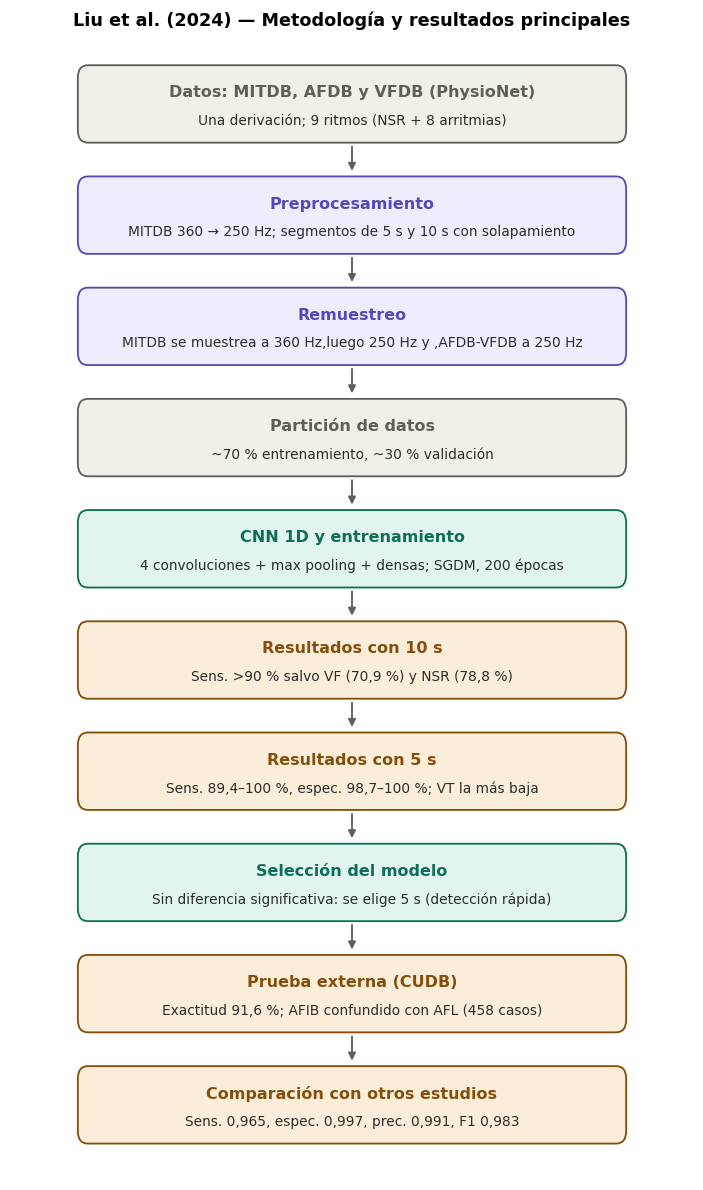

In [3]:
# Agrega una nueva categoría de color al diccionario: ámbar (relleno, borde) para las etapas de resultados
COLORES["resultado"] = ("#FAEEDA", "#854F0B")   # ámbar para resultados

# Lista de etapas del diagrama; cada tupla es (título de la caja, texto de detalle, categoría de color)
etapas = [
    ("Datos: MITDB, AFDB y VFDB (PhysioNet)", "Una derivación; 9 ritmos (NSR + 8 arritmias)",                  "datos"),
    ("Preprocesamiento",                      "MITDB 360 → 250 Hz; segmentos de 5 s y 10 s con solapamiento",  "proc"),
    ("Remuestreo",                            "MITDB se muestrea a 360 Hz,luego 250 Hz y ,AFDB-VFDB a 250 Hz", "proc"),
    ("Partición de datos",                    "~70 % entrenamiento, ~30 % validación",                         "datos"),
    ("CNN 1D y entrenamiento",                "4 convoluciones + max pooling + densas; SGDM, 200 épocas",      "modelo"),
    ("Resultados con 10 s",                   "Sens. >90 % salvo VF (70,9 %) y NSR (78,8 %)",                  "resultado"),
    ("Resultados con 5 s",                    "Sens. 89,4–100 %, espec. 98,7–100 %; VT la más baja",           "resultado"),
    ("Selección del modelo",                  "Sin diferencia significativa: se elige 5 s (detección rápida)", "modelo"),
    ("Prueba externa (CUDB)",                 "Exactitud 91,6 %; AFIB confundido con AFL (458 casos)",         "resultado"),
    ("Comparación con otros estudios",        "Sens. 0,965, espec. 0,997, prec. 0,991, F1 0,983",              "resultado"),
]

# Llama a la función que dibuja el flujo con la lista de etapas y el título que va arriba del diagrama
dibujar_flujo(etapas, "Liu et al. (2024) — Metodología y resultados principales")

**Metodología utilizada en el artículo**

**Objetivo de la investigación:** Los autores querían saber si una red neuronal convolucional 1D puede clasificar nueve ritmos cardíacos (el ritmo sinusal normal y ocho arritmias) usando solo una derivación del ECG y sin pasar por la detección del complejo QRS, que es lo que hacía la mayoría de trabajos anteriores. También querían comparar ventanas de 5 s y 10 s para ver si una señal más corta da resultados parecidos. Si eso se cumple, se podría detectar una arritmia más rápido, algo útil en urgencias y en dispositivos portátiles de uso diario. **[1]**

**Metodología**

**-Datos:** Se tomaron los nueve ritmos de tres bases de PhysioNet (MITDB, AFDB y VFDB) usando la librería WFDB. Como MITDB está muestreada a 360 Hz y las otras dos a 250 Hz, la bajaron a 250 Hz para que todas quedaran iguales.

**-Segmentación:** En lugar de cortar la señal a partir de los latidos, la dividieron en segmentos de 5 s (1250 muestras) o de 10 s (2500 muestras). Para los ritmos con pocos datos usaron un método de solapamiento: una ventana que se desplaza y genera segmentos que se traslapan, y dos segmentos consecutivos forman una muestra nueva. Así aumentaron el número de muestras sin tener que conseguir más registros.

**-Partición:** Separaron los datos en entrenamiento y validación, aproximadamente 70 % y 30 %. Con 5 s quedaron 5734 muestras de entrenamiento y 2568 de validación, y con 10 s quedaron 5934 y 2525.

**-Construcción de Red Neuronal Convolucional:** La arquitectura se basó en un trabajo previo de Acharya et al. Tiene cuatro capas convolucionales con filtros de tamaño 27, 24, 15 y 10 (64 filtros cada una), y después de cada una hay un max pooling de tamaño 2. Luego vienen tres capas completamente conectadas de 1250, 10 y 8 neuronas, y una softmax para obtener la clase.

**-Entrenamiento:** Usaron descenso de gradiente estocástico con momento, minibatch de 20 y 200 épocas, con GPU para acelerar el proceso.

**-Evaluación interna:** Calcularon exactitud, sensibilidad y especificidad por clase y revisaron las matrices de confusión. Los modelos de 5 s y 10 s rindieron de forma similar. El de 10 s falló más con VF y NSR (sensibilidad de 70,9 % y 78,8 %), y el de 5 s tuvo su peor resultado en VT (89,4 %). Gran parte de los errores fueron confusiones entre VT y VF, que en la práctica clínica se manejan igual con desfibrilación.

**-Validación externa:** Como el de 5 s detecta más rápido, escogieron ese modelo y lo probaron con la base CUDB, usando los registros completos y sin solapamiento, para ver cómo se comporta con datos que nunca vio. La exactitud promedio fue de 91,6 %. El error más frecuente fue confundir AFIB con AFL (458 casos), que los autores relacionan con el desbalance de clases de esa base.

**-Cierre:** Compararon sus métricas con las de otros estudios y reconocieron limitaciones: no incluyeron otras arritmias como PSVT o PVC, el ECG es sensible al ruido y las bases públicas ya vienen depuradas, así que falta validar con datos clínicos reales.

**Resultados principales obtenidos por los investigadores:** Los dos modelos tuvieron un desempeño alto y comparable. Con ventanas de 10 s, la exactitud por clase estuvo entre 95,3 % y 99,8 %, y la sensibilidad superó el 90 % en siete de los nueve ritmos; las excepciones fueron VF (70,9 %) y NSR (78,8 %), cuyos errores se concentraron en la confusión de VF con VT y de NSR con VFL. Con ventanas de 5 s, la sensibilidad fue de 89,4 % a 100 % y la especificidad de 98,7 % a 100 %, con VT como la clase más débil (89,4 %), confundida sobre todo con VF. Como no hubo diferencias estadísticamente significativas entre ambos, los autores eligieron el modelo de 5 s por permitir una detección más rápida, y al probarlo con la base externa CUDB obtuvieron una exactitud promedio de 91,6 %, con AFIB clasificado erróneamente como AFL en 458 casos, error que atribuyen al desbalance de clases de esa base. En la comparación con trabajos previos, el modelo alcanzó una sensibilidad de 0,965, una especificidad de 0,997, una precisión de 0,991 y un F1 de 0,983 (Tabla 4), sin necesidad de detectar el QRS y usando una sola derivación. **[1]**

## **1.2. Optimal Multi-Stage Arrhythmia Classification Approach**

Enlace de acceso artículo 2: https://www.nature.com/articles/s41598-020-59821-7

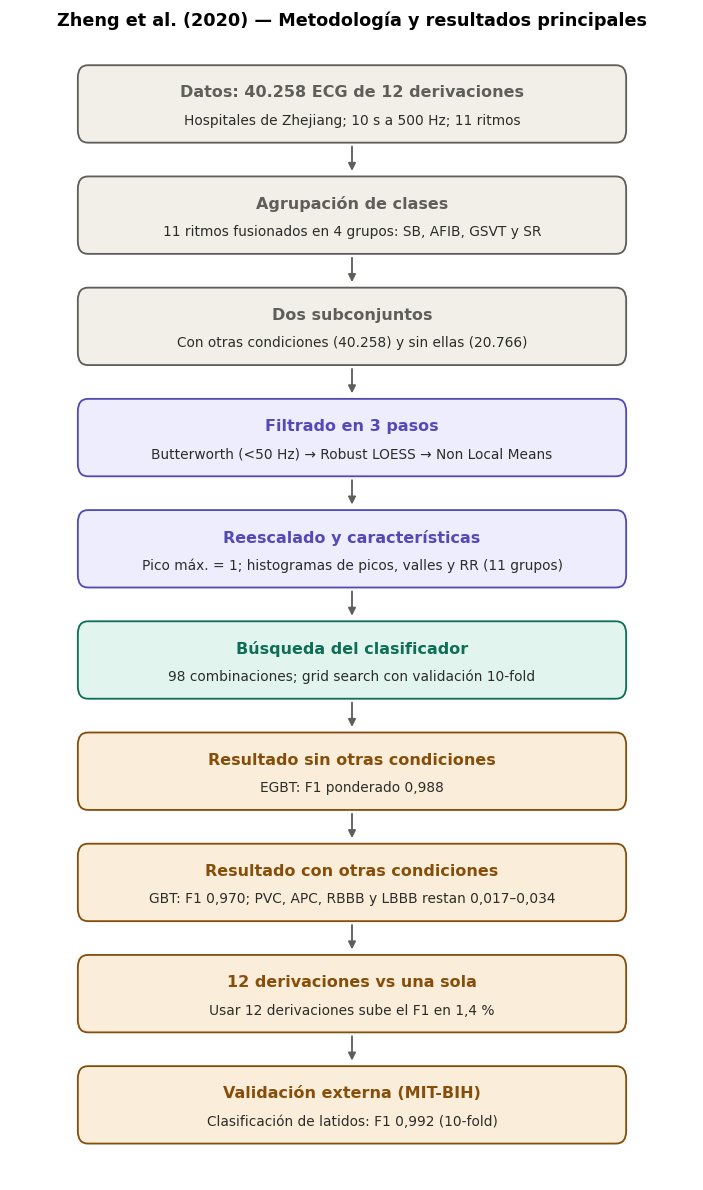

In [4]:
# Agrega una nueva categoría de color al diccionario: ámbar (relleno, borde) para las etapas de resultados
COLORES["resultado"] = ("#FAEEDA", "#854F0B")   # ámbar para resultados

# Lista de etapas del diagrama; cada tupla es (título de la caja, texto de detalle, categoría de color)
etapas = [
    ("Datos: 40.258 ECG de 12 derivaciones",  "Hospitales de Zhejiang; 10 s a 500 Hz; 11 ritmos",               "datos"),
    ("Agrupación de clases",                  "11 ritmos fusionados en 4 grupos: SB, AFIB, GSVT y SR",          "datos"),
    ("Dos subconjuntos",                      "Con otras condiciones (40.258) y sin ellas (20.766)",            "datos"),
    ("Filtrado en 3 pasos",                   "Butterworth (<50 Hz) → Robust LOESS → Non Local Means",          "proc"),
    ("Reescalado y características",          "Pico máx. = 1; histogramas de picos, valles y RR (11 grupos)",   "proc"),
    ("Búsqueda del clasificador",             "98 combinaciones; grid search con validación 10-fold",           "modelo"),
    ("Resultado sin otras condiciones",       "EGBT: F1 ponderado 0,988",                                       "resultado"),
    ("Resultado con otras condiciones",       "GBT: F1 0,970; PVC, APC, RBBB y LBBB restan 0,017–0,034",        "resultado"),
    ("12 derivaciones vs una sola",           "Usar 12 derivaciones sube el F1 en 1,4 %",                       "resultado"),
    ("Validación externa (MIT-BIH)",          "Clasificación de latidos: F1 0,992 (10-fold)",                   "resultado"),
]

# Llama a la función que dibuja el flujo con la lista de etapas y el título que va arriba del diagrama
dibujar_flujo(etapas, "Zheng et al. (2020) — Metodología y resultados principales")

**Objetivo de la investigación:** Los autores querían encontrar el esquema multietapa óptimo para clasificar arritmias a partir de ECG de 12 derivaciones, con una exactitud al nivel de cardiólogos profesionales. En lugar de proponer un solo algoritmo, optimizaron toda la cadena (reducción de ruido, extracción de características y clasificador) comparando cientos de combinaciones sobre una base de datos propia y grande. También buscaban medir dos cosas que no se habían estudiado: cuánto mejora la clasificación al usar 12 derivaciones en vez de una sola, y cuánto la empeoran otras condiciones cardíacas presentes en el paciente (PVC, APC, RBBB, LBBB). Además, querían que el método fuera aplicable a datos de dispositivos portátiles y a otras fuentes de ECG. **[2]**

**Metodología**

1. **Base de datos:** Usaron 40.258 ECG de 12 derivaciones (22.599 hombres y 17.659 mujeres) de dos hospitales de Zhejiang, China, entre 2013 y 2018. Cada registro dura 10 s, fue tomado a 500 Hz y etiquetado por médicos supervisados por cardiólogos, con 11 tipos de ritmo y 67 hallazgos cardíacos adicionales.

2. **Agrupación de clases:** Como algunos ritmos tenían muy pocos casos, los 11 ritmos se fusionaron en 4 grupos:

SB: bradicardia sinusal.
AFIB: fibrilación y flutter auricular.
GSVT: taquicardias supraventriculares (SVT, AT, AVNRT, AVRT) y marcapasos auricular errante.
SR: ritmo sinusal e irregularidad sinusal.

3. **Dos conjuntos de datos:** Se trabajó con la base completa (pacientes con otras condiciones cardíacas) y con un subconjunto de 20.766 ECG sin ellas, para evaluar el efecto de esas condiciones.

4. **Reducción de ruido en tres pasos:**

-Filtro pasa bajas Butterworth, para eliminar ruido de alta frecuencia (por encima de 50 Hz).

-Robust LOESS (Regresión Local robusta), para quitar la deriva de la línea base.

-Non Local Means (NLM), para eliminar el ruido restante. Usa un kernel gaussiano, ventana de 10 y un parámetro de suavizado de 1,5 veces la desviación estándar del ruido, estimada con MAD.

5. **Reescalado:** Cada señal se normalizó para que su pico máximo fuera 1. Luego repitieron el análisis sin reescalar para medir el efecto, de modo que quedaron 44 conjuntos de datos.

6. **Extracción de características:** Detectaron picos y valles (complejo QRS, picos no QRS y valles) y midieron su altura, ancho y prominencia, además de los intervalos RR. Como cada paciente tiene un número distinto de picos, construyeron una tabla de distribución empírica de frecuencias en 100 intervalos para cada atributo y para las razones entre diferencias de altura, ancho y prominencia sobre la diferencia de tiempo. Así obtuvieron hasta 39.830 características.

7. **Grupos de características:** Definieron 11 combinaciones (Tabla 8), desde 11 variables básicas entregadas por el equipo de ECG (grupo 1) hasta todas las derivaciones juntas (grupo 11). Esto permitió comparar 12 derivaciones contra una sola.

8. **Búsqueda de clasificador:** Probaron 19 algoritmos base (DT, KNN, Naive Bayes, regresión logística, redes, SVC, Random Forest, ERT, GBT, EGBT, entre otros), combinados con estrategias de ensamble y de descomposición multiclase (bagging, AdaBoost, OneVsRest, OneVsOne y códigos de corrección de errores). En total compararon 98 combinaciones.

9. **Ajuste de hiperparámetros:** Hicieron una búsqueda exhaustiva en rejilla (grid search) con validación cruzada de 10 pliegues, eligiendo los valores con mayor F1 ponderado.

10. **Evaluación:** Validación cruzada de 10 pliegues (80 % entrenamiento, 20 % prueba), con F1 ponderado, precisión, sensibilidad y matrices de confusión.

11. **Validación externa:** Aplicaron el método a la base MIT-BIH para clasificar latidos individuales (normal, marcapasos, bloqueo de rama izquierda, bloqueo de rama derecha y contracción ventricular prematura), usando dos intervalos RR cercanos a cada latido para extraer las características y validación cruzada con 90 % de entrenamiento y 10 % de prueba.

**Resultados principales:** El mejor esquema combinó el filtrado en tres pasos, las características basadas en distribuciones de frecuencia y clasificadores de boosting de árboles (EGBT y GBT, que dominaron la mayoría de los grupos de características). En pacientes sin otras condiciones cardíacas, el modelo EGBT alcanzó un F1 ponderado de 0,988 (AFIB 0,964, GSVT 0,979, SB 0,996 y SR 0,989). En pacientes con otras condiciones, el GBT alcanzó 0,97 (AFIB 0,941, GSVT 0,949, SB 0,993 y SR 0,977), y esas condiciones (PVC, RBBB, LBBB y APC) redujeron el F1 entre 0,017 y 0,034 con el mismo grupo de características. Usar 12 derivaciones en lugar de una sola subió el F1 en 1,4 %, y las características propuestas por los autores superaron a las que entrega el equipo de ECG (diferencia de 0,021 entre los grupos 1 y 2). Reescalar las señales tuvo un efecto positivo muy pequeño (alrededor de 0,001 de F1). En la validación externa con MIT-BIH obtuvieron un F1 de 0,992 en promedio, el más alto frente a los estudios con los que se compararon, y con una ventaja práctica: las características son interpretables, a diferencia de las de las redes profundas. **[2]**

## **1.2. Prediction of atrial fibrillation from at-home single-lead ECG signals without arrhythmias**

Enlace de acceso artículo 3: https://www.nature.com/articles/s41746-023-00966-w

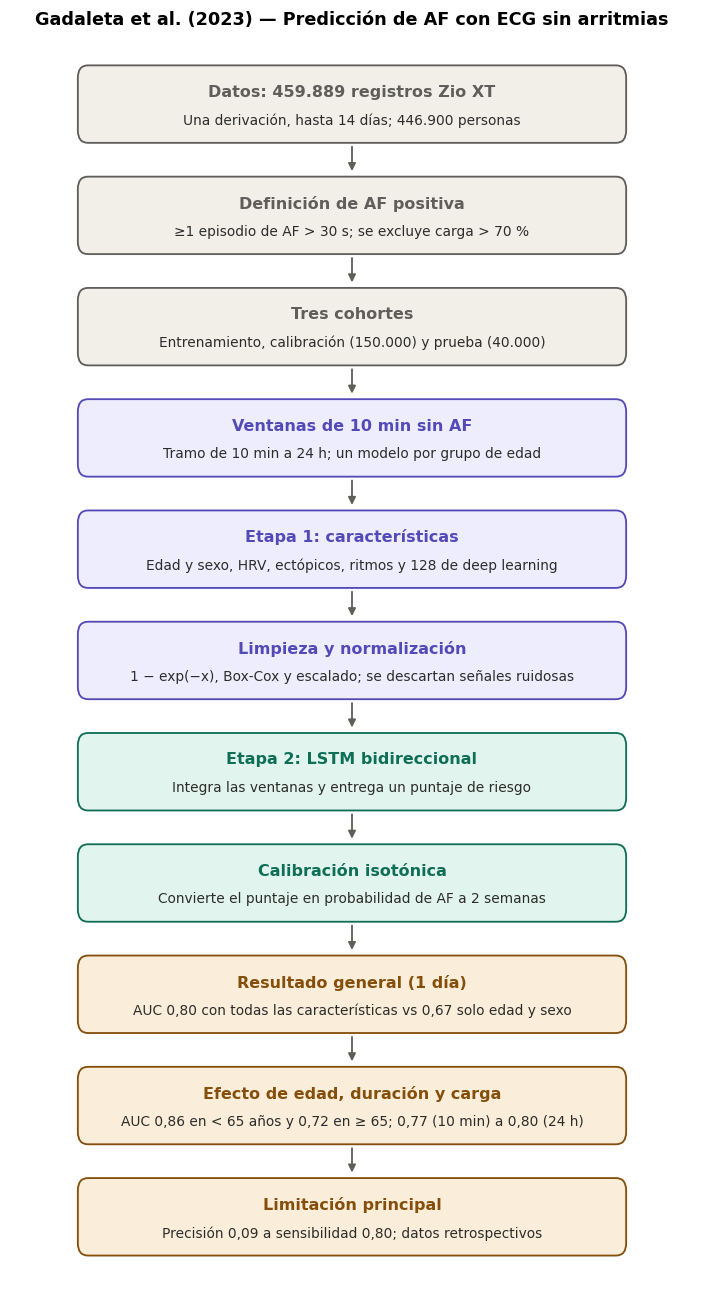

In [5]:
# Categoría de color nueva para resultados (si ya la definiste antes, esta línea no cambia nada)
COLORES["resultado"] = ("#FAEEDA", "#854F0B")   # ámbar para resultados

# Lista de etapas del diagrama; cada tupla es (título de la caja, texto de detalle, categoría de color)
etapas = [
    ("Datos: 459.889 registros Zio XT",       "Una derivación, hasta 14 días; 446.900 personas",                "datos"),
    ("Definición de AF positiva",             "≥1 episodio de AF > 30 s; se excluye carga > 70 %",              "datos"),
    ("Tres cohortes",                         "Entrenamiento, calibración (150.000) y prueba (40.000)",         "datos"),
    ("Ventanas de 10 min sin AF",             "Tramo de 10 min a 24 h; un modelo por grupo de edad",            "proc"),
    ("Etapa 1: características",              "Edad y sexo, HRV, ectópicos, ritmos y 128 de deep learning",     "proc"),
    ("Limpieza y normalización",              "1 − exp(−x), Box-Cox y escalado; se descartan señales ruidosas", "proc"),
    ("Etapa 2: LSTM bidireccional",           "Integra las ventanas y entrega un puntaje de riesgo",            "modelo"),
    ("Calibración isotónica",                 "Convierte el puntaje en probabilidad de AF a 2 semanas",         "modelo"),
    ("Resultado general (1 día)",             "AUC 0,80 con todas las características vs 0,67 solo edad y sexo", "resultado"),
    ("Efecto de edad, duración y carga",      "AUC 0,86 en < 65 años y 0,72 en ≥ 65; 0,77 (10 min) a 0,80 (24 h)", "resultado"),
    ("Limitación principal",                  "Precisión 0,09 a sensibilidad 0,80; datos retrospectivos",       "resultado"),
]

# Llama a la función que dibuja el flujo con la lista de etapas y el título que va arriba del diagrama
dibujar_flujo(etapas, "Gadaleta et al. (2023) — Predicción de AF con ECG sin arritmias")

**Objetivo de la investigación:** Los autores querían construir un modelo que estime el riesgo de que una persona presente fibrilación auricular (AF) o flutter en las siguientes dos semanas, usando únicamente tramos de ECG de una derivación en los que no aparece ninguna AF. La idea es identificar a quienes tienen fibrilación paroxística que un monitoreo corto no logró captar, para recomendarles un monitoreo más largo o repetido. También querían medir cuánto aporta cada tipo de información (edad y sexo, variabilidad de la frecuencia cardíaca, latidos ectópicos y características aprendidas por deep learning) y cómo cambia la predicción según la edad, la duración del registro y la carga de AF. **[3]**

**Metodología**

1. **Datos:** Se usaron 459.889 registros de 446.900 personas con el parche Zio XT de iRhythm (una derivación, hasta 14 días), tomados entre enero de 2019 y mayo de 2022. Se excluyeron las personas con AF persistente (carga mayor al 70 %). Se consideró positiva a una persona con al menos un episodio de AF de más de 30 s verificado por un técnico certificado.

2. **División de cohortes:** Hubo tres cohortes separadas: entrenamiento (269.889 registros, enriquecidos con casos de AF), calibración (150.000 registros con prevalencia natural) y prueba (40.000 registros). Se entrenó un modelo por grupo de edad (18-54, 55-64, 65-74, 75-84 y 85-99).

3. **Entrada del modelo:** Un tramo de ECG sin AF, de entre 10 min y 24 h, dividido en ventanas de 10 min.

4. **Primera etapa (por ventana de 10 min):** Se extraen cuatro grupos de características: Demografía (edad y sexo).Métricas de variabilidad de la frecuencia cardíaca (HRV), calculadas con los picos R sin contar los ectópicos. Latidos ectópicos (PAC y PVC) y otros ritmos anormales, tomados de las anotaciones del reporte clínico.
128 características de aprendizaje de representación, generadas por una red profunda (módulo A) a partir de la morfología del ECG. Sus pesos se congelan tras entrenarla.

5. **Limpieza y normalización:** Transformación 1 − exp(−x) para las cargas de ritmo, Box-Cox para el resto, eliminación del offset y escalado. Se descartaron señales con frecuencia media menor a 20 lpm, más de 2 min de artefactos en la ventana o muy pocos picos R.

6. **Segunda etapa:** Las características de las ventanas consecutivas entran a un módulo B: una LSTM bidireccional de dos capas, pooling y dos capas completamente conectadas, que integran la información de todo el tramo y entregan un puntaje de riesgo.

7. **Calibración:** Con regresión isotónica sobre la cohorte de calibración, el puntaje se convierte en la probabilidad real de AF en la ventana de observación y queda en la misma escala para todas las edades.

8. **Configuraciones comparadas:** Se entrenó el modelo con distintas entradas: solo edad y sexo (AG), AG + HRV, AG + ectópicos, AG + HRV + ectópicos + ritmo, solo deep learning (DL Only) y todas las características (All Features).

9. **Evaluación:** Se usó AUC y precisión promedio, con intervalos de confianza al 95 % por bootstrap de 10.000 iteraciones y pruebas pareadas para comparar modelos. Se analizó por edad (menores y mayores de 65), por duración del registro (10 min, 1 h y 24 h) y por carga de AF (baja menor al 1 %, media de 1 a 10 % y alta mayor al 10 %).

**Resultados principales:** Con un registro de 1 día sin AF y una prevalencia de 4,3 %, el modelo con todas las características alcanzó un AUC de 0,80 (IC 0,79-0,81), frente a 0,67 del modelo con solo edad y sexo y 0,74 al agregar HRV, una mejora de 0,12 sobre el modelo demográfico. El modelo con solo características de deep learning rindió casi igual que el completo (diferencia mínima de AUC), lo que indica que la red extrae bien la información relevante de la morfología. Por edad, el AUC fue 0,86 en menores de 65 años y 0,72 en mayores, donde el modelo demográfico casi no discrimina (0,53). Un registro más largo mejoró la predicción: el AUC pasó de 0,77 con 10 min a 0,80 con 24 h, mientras que el modelo demográfico no cambió. El AUC también subió con la carga de AF (0,76, 0,80 y 0,90 para carga baja, media y alta), y la mayor ventaja del deep learning apareció en la carga media, con 0,80 frente a 0,69 del modelo demográfico. A una sensibilidad fija de 0,80, la especificidad global fue de 0,65, con precisión de 0,09 y F1 de 0,17. **[3]**

## **1.4 Contraste y comparación de los 3 artículos**

| Aspecto | Liu et al. [1] (2024) | Zheng et al. [2] (2020) | Gadaleta et al. [3] (2023) |
|---|---|---|---|
| **Objetivo** | Clasificar 9 ritmos con una CNN 1D sin detectar el QRS | Hallar el esquema multietapa óptimo para clasificar 4 grupos de ritmo | Predecir AF en las siguientes 2 semanas a partir de ECG sin AF |
| **Tipo de tarea** | Clasificación de ritmos presentes | Clasificación de ritmos presentes | Predicción de riesgo futuro |
| **Señal** | ECG de 1 derivación | ECG de 12 derivaciones (10 s, 500 Hz) | ECG de 1 derivación (parche Zio XT, hasta 14 días) |
| **Datos** | MITDB, AFDB y VFDB (PhysioNet); validación externa con CUDB | 40.258 pacientes de dos hospitales de Zhejiang; validación externa con MIT-BIH | 459.889 registros de 446.900 personas (iRhythm) |
| **Preprocesamiento** | Remuestreo de MITDB a 250 Hz; segmentos de 5 s y 10 s con solapamiento | Butterworth + Robust LOESS + Non Local Means; reescalado | Ventanas de 10 min; Box-Cox y 1 − exp(−x); descarte de señales ruidosas |
| **Características** | Aprendidas por la CNN (sin extracción manual) | Manuales: picos, valles y RR en histogramas (hasta 39.830) | HRV, ectópicos, edad y sexo, y 128 de deep learning |
| **Modelo** | CNN 1D (4 convoluciones + capas densas) | EGBT y GBT (boosting de árboles) | Módulo DL + LSTM bidireccional + calibración isotónica |
| **Resultado principal** | Exactitud 91,6 % en CUDB (modelo de 5 s); sensibilidad 0,965 y F1 0,983 en validación | F1 ponderado 0,988 (sin otras condiciones) y 0,970 (con ellas) | AUC 0,80 con 1 día de ECG (0,67 solo con edad y sexo) |
| **Principal limitación** | Ritmos no incluidos, ruido, bases públicas ya depuradas | Otras condiciones cardíacas bajan el F1 en 0,017 a 0,034 | Precisión baja (0,09) y datos retrospectivos de un solo dispositivo |

## 2.Análisis estadístico generalizado y preguntas informativas del Dataset

La base de datos ChapmanECG es un repositorio clínico a gran escala que contiene electrocardiogramas de 12 derivaciones de 10,646 pacientes, registrados en ventanas temporales de 10 segundos a una frecuencia de muestreo de 500 Hz. Todos los datos fueron evaluados y etiquetados rigurosamente por cardiólogos profesionales para clasificar 11 ritmos cardíacos principales y más de 60 condiciones cardiovasculares adicionales, convirtiéndola en un recurso estandarizado de alta fidelidad, ideal para entrenar y validar modelos de inteligencia artificial orientados al diagnóstico automatizado de arritmias. [4]

In [6]:
# Cargamos el archivo Excel con los datos clínicos y etiquetas de diagnóstico en un DataFrame de pandas
df = pd.read_excel("Diagnostics.xlsx")
# Observación preliminar de las variables y estructura del dataset
df.describe()

,PatientAge,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
count,10646.000000,10646.000000,10646.00000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000,10646.000000
mean,59.186831,84.136107,92.57787,90.989292,384.150855,434.154048,39.620609,44.637704,13.839470,219.260567,264.755213,411.335995
std,18.030019,34.455349,60.09394,17.479540,59.226289,39.354182,41.212648,57.478092,5.676339,6.410413,8.362120,29.777404
min,4.000000,34.000000,0.00000,18.000000,114.000000,219.000000,-89.000000,-89.000000,5.000000,159.000000,249.000000,281.000000
25%,49.000000,57.000000,57.00000,80.000000,344.000000,408.000000,14.000000,19.000000,9.000000,216.000000,259.000000,392.000000
50%,62.000000,73.000000,72.00000,88.000000,390.000000,430.000000,46.000000,42.000000,12.000000,219.000000,264.000000,414.000000
75%,72.000000,104.000000,106.00000,98.000000,426.000000,456.000000,68.000000,62.000000,17.000000,224.000000,268.000000,432.000000
max,98.000000,263.000000,535.00000,256.000000,736.000000,760.000000,270.000000,270.000000,40.000000,240.000000,331.000000,582.000000


El archivo Diagnostics.xlsx estructura sus 16 columnas en tres grupos esenciales: la identificación y demografía del paciente (FileName, PatientAge, Gender), las etiquetas diagnósticas establecidas por cardiólogos (Rhythm, Beat), y los parámetros fisiológicos detallados extraídos del electrocardiograma, como frecuencias cardíacas, duraciones de intervalos (QRS, QT) y ejes eléctricos. Esta tabla funciona como la base de referencia (ground truth) que vincula de manera estructurada cada señal con su respectiva condición médica y métricas clínicas.

In [7]:
df.info()  # Muestra información sobre el DataFrame, incluyendo tipos de datos y valores nulos
df.head()  # Muestra las primeras filas del DataFrame para una vista rápida de los datos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10646 entries, 0 to 10645
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   FileName         10646 non-null  object
 1   Rhythm           10646 non-null  object
 2   Beat             10646 non-null  object
 3   PatientAge       10646 non-null  int64 
 4   Gender           10646 non-null  object
 5   VentricularRate  10646 non-null  int64 
 6   AtrialRate       10646 non-null  int64 
 7   QRSDuration      10646 non-null  int64 
 8   QTInterval       10646 non-null  int64 
 9   QTCorrected      10646 non-null  int64 
 10  RAxis            10646 non-null  int64 
 11  TAxis            10646 non-null  int64 
 12  QRSCount         10646 non-null  int64 
 13  QOnset           10646 non-null  int64 
 14  QOffset          10646 non-null  int64 
 15  TOffset          10646 non-null  int64 
dtypes: int64(12), object(4)
memory usage: 1.3+ MB


,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
0,MUSE_20180113_171327_27000,AFIB,RBBB TWC,85,MALE,117,234,114,356,496,81,-27,19,208,265,386
1,MUSE_20180112_073319_29000,SB,TWC,59,FEMALE,52,52,92,432,401,76,42,8,215,261,431
2,MUSE_20180111_165520_97000,SA,NONE,20,FEMALE,67,67,82,382,403,88,20,11,224,265,415
3,MUSE_20180113_121940_44000,SB,NONE,66,MALE,53,53,96,456,427,34,3,9,219,267,447
4,MUSE_20180112_122850_57000,AF,STDD STTC,73,FEMALE,162,162,114,252,413,68,-40,26,228,285,354


In [8]:
# Observación preliminar de las variables y estructura del dataset
df.groupby(by=["Rhythm"]).describe()

PatientAge                                                       \
            count       mean        std   min    25%   50%   75%   max   
Rhythm                                                                   
AF          445.0  71.065169  13.497673  21.0  63.00  72.0  81.0  97.0   
AFIB       1780.0  73.359551  11.137343  30.0  67.00  75.0  82.0  98.0   
AT          121.0  65.719008  19.300787   8.0  60.00  71.0  77.0  94.0   
AVNRT        16.0  57.875000  17.335417  27.0  51.00  59.0  66.0  84.0   
AVRT          8.0  57.500000  16.835337  25.0  47.75  62.5  67.0  77.0   
SA          399.0  34.746867  23.029446   4.0  14.50  29.0  52.5  93.0   
SAAWR         7.0  51.142857  31.829905  15.0  22.50  49.0  81.0  87.0   
SB         3889.0  58.339676  13.952579  10.0  50.00  60.0  68.0  98.0   
SR         1826.0  54.352136  16.331977   4.0  44.00  55.0  66.0  95.0   
ST         1568.0  54.565051  21.060029   4.0  40.00  57.0  70.0  96.0   
SVT         587.0  55.623509  18.527343   4.0  42.00  56.0  69.0  96.0   

       VentricularRate              ... QOffset        TOffset              \
                 count        mean  ...     75%    max   count        mean   
Rhythm                              ...                                      
AF               445.0  114.577528  ...  272.00  314.0   445.0  392.907865   
AFIB            1780.0   95.489326  ...  269.00  311.0  1780.0  402.439888   
AT               121.0  116.438017  ...  267.00  294.0   121.0  387.388430   
AVNRT             16.0  172.250000  ...  271.00  316.0    16.0  359.062500   
AVRT               8.0  171.000000  ...  266.75  274.0     8.0  358.125000   
SA               399.0   72.922306  ...  266.50  299.0   399.0  411.834586   
SAAWR              7.0   64.428571  ...  266.00  274.0     7.0  423.428571   
SB              3889.0   55.022885  ...  269.00  314.0  3889.0  435.605554   
SR              1826.0   75.748083  ...  267.00  311.0  1826.0  413.105148   
ST              1568.0  112.157526  ...  266.00  303.0  1568.0  386.538265   
SVT              587.0  168.367973  ...  271.00  331.0   587.0  358.831346   

                                                       
              std    min    25%    50%     75%    max  
Rhythm                                                 
AF      34.783087  302.0  369.0  389.0  412.00  537.0  
AFIB    26.553652  307.0  385.0  403.0  420.00  562.0  
AT      25.048743  323.0  372.0  387.0  403.00  490.0  
AVNRT   10.009787  334.0  355.5  359.5  363.25  381.0  
AVRT    26.351674  318.0  338.0  364.0  378.25  390.0  
SA      15.496724  376.0  400.5  411.0  421.00  466.0  
SAAWR   15.576233  406.0  414.0  421.0  428.00  453.0  
SB      17.177428  385.0  424.0  434.0  445.00  582.0  
SR      14.925198  370.0  403.0  413.0  423.00  494.0  
ST      15.636704  328.0  377.0  387.0  395.00  559.0  
SVT     19.553825  281.0  347.0  359.0  371.00  475.0  

[11 rows x 96 columns]

In [9]:
# Verificar si hay datos faltantes en el DataFrame
datos_faltantes = df.isnull().sum() #Se crea un objeto que cuenta la cantidad de datos faltantes por columna en el DataFrame
print("Datos faltantes por columna:\n", datos_faltantes)

#Verificar si hay datos repetidos en el DataFrame
datos_repetidos = df.duplicated().sum() #Se crea un objeto que cuenta la cantidad de filas duplicadas en el DataFrame
print("Número de filas duplicadas en el DataFrame:", datos_repetidos)

#Clasificación de pacientes por sexo español
sexo_distribucion = df['Gender'].value_counts() #Se crea un objeto que cuenta la cantidad de pacientes por sexo
print("Distribución de pacientes por sexo:\n", sexo_distribucion) #Se imprime la distribución de pacientes por sexo
print( f'Hay {sexo_distribucion["MALE"]} hombres y {sexo_distribucion["FEMALE"]} mujeres en el dataset.') 

print("--------------------------------------------------------")

#Descripción de la edad de los pacientes, promedio,desviación estándar, mínimo, máximo y percentiles
edad_descripcion = df['PatientAge'].describe() #Se crea un objeto que describe la edad
print("Descripción de la edad de los pacientes:\n", edad_descripcion) 
print(f'La edad promedio de los pacientes es de {edad_descripcion["mean"]:.2f} años, con una desviación estándar de {edad_descripcion["std"]:.2f} años. La edad mínima es de {edad_descripcion["min"]:.2f} años y la máxima es de {edad_descripcion["max"]:.2f} años. El percentil 25 es de {edad_descripcion["25%"]:.2f} años, el percentil 50 (mediana) es de {edad_descripcion["50%"]:.2f} años y el percentil 75 es de {edad_descripcion["75%"]:.2f} años.')


Datos faltantes por columna:
 FileName           0
Rhythm             0
Beat               0
PatientAge         0
Gender             0
VentricularRate    0
AtrialRate         0
QRSDuration        0
QTInterval         0
QTCorrected        0
RAxis              0
TAxis              0
QRSCount           0
QOnset             0
QOffset            0
TOffset            0
dtype: int64
Número de filas duplicadas en el DataFrame: 0
Distribución de pacientes por sexo:
 Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64
Hay 5956 hombres y 4690 mujeres en el dataset.
--------------------------------------------------------
Descripción de la edad de los pacientes:
 count    10646.000000
mean        59.186831
std         18.030019
min          4.000000
25%         49.000000
50%         62.000000
75%         72.000000
max         98.000000
Name: PatientAge, dtype: float64
La edad promedio de los pacientes es de 59.19 años, con una desviación estándar de 18.03 años. La edad mínima es de 4.00

## ¿Qué tipo de arritmias son más prevalentes? 

In [10]:
# Redefinimos el encabezado de la columna Rhythm para que sea más comprensible, usando un diccionario de traducción
NOMBRES_RITMO = {
    "SB":    "Bradicardia sinusal",
    "SR":    "Ritmo sinusal",
    "AFIB":  "Fibrilación auricular",
    "ST":    "Taquicardia sinusal",
    "AF":    "Flutter auricular",
    "SA":    "Irregularidad sinusal (arritmia sinusal)",
    "SVT":   "Taquicardia supraventricular",
    "AT":    "Taquicardia auricular",
    "AVNRT": "Taquicardia por reentrada nodal AV",
    "AVRT":  "Taquicardia por reentrada AV",
    "SAAWR": "Marcapasos auricular migratorio",
}

# 1. Obtenemos el conteo y los porcentajes desde la columna original 'Rhythm'
ritmo_conteo = df['Rhythm'].value_counts()
ritmo_porcentaje = df['Rhythm'].value_counts(normalize=True) * 100

# 2. Consolidamos todo en una única tabla (DataFrame) optimizada
ritmo_distribucion = pd.DataFrame({
    'Nombre Completo': ritmo_conteo.index.map(NOMBRES_RITMO),
    'Cantidad de Pacientes': ritmo_conteo.values,
    'Porcentaje (%)': ritmo_porcentaje.values.round(2)
}, index=ritmo_conteo.index) # Usamos el acrónimo original como índice de la tabla

# Nombramos el índice para mayor claridad
ritmo_distribucion.index.name = 'Acrónimo'

# 3. Imprimimos la tabla unificada
print("Distribución de pacientes por ritmo cardíaco:\n")
print(ritmo_distribucion)

Distribución de pacientes por ritmo cardíaco:

                                   Nombre Completo  Cantidad de Pacientes  \
Acrónimo                                                                    
SB                             Bradicardia sinusal                   3889   
SR                                   Ritmo sinusal                   1826   
AFIB                         Fibrilación auricular                   1780   
ST                             Taquicardia sinusal                   1568   
SVT                   Taquicardia supraventricular                    587   
AF                               Flutter auricular                    445   
SA        Irregularidad sinusal (arritmia sinusal)                    399   
AT                           Taquicardia auricular                    121   
AVNRT           Taquicardia por reentrada nodal AV                     16   
AVRT                  Taquicardia por reentrada AV                      8   
SAAWR              Marcapasos

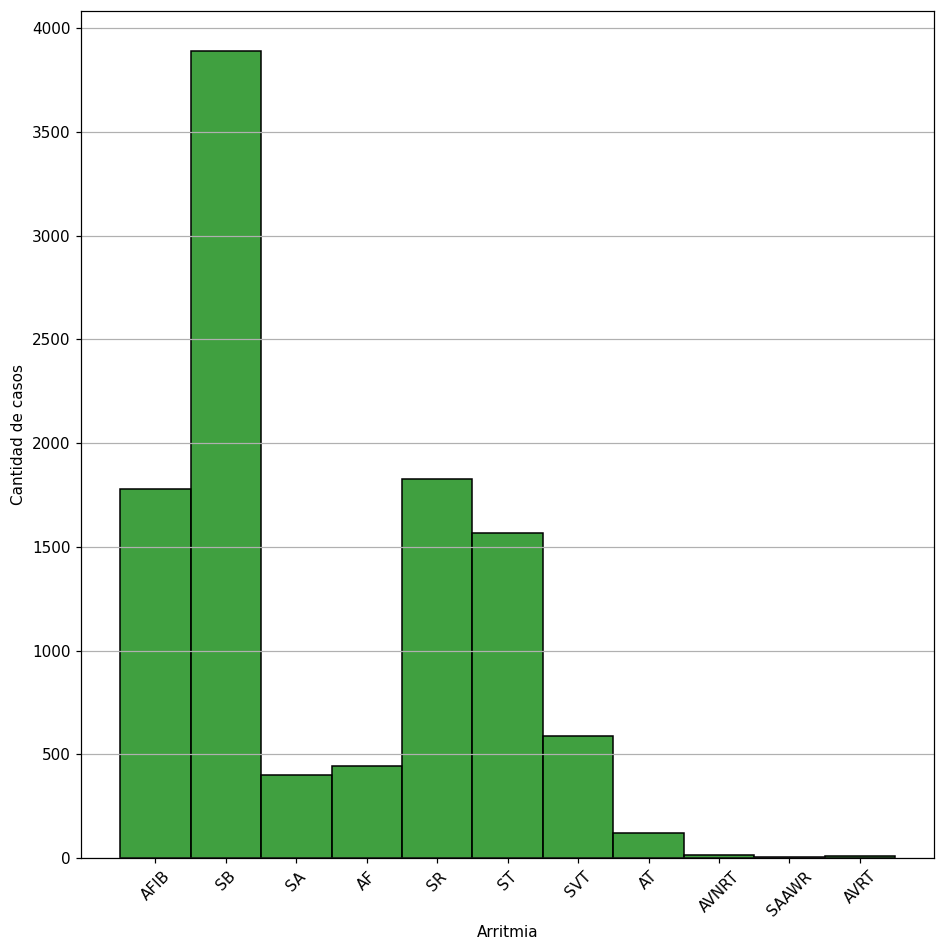

In [11]:
# Gráfica de distribución de arritmias
plt.figure(figsize=(10, 10))
sns.histplot(df['Rhythm'], bins=10, kde=False, color='green')
plt.ylabel('Cantidad de casos')
plt.xlabel('Arritmia')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

Según los resultados obtenidos, excluyendo el Ritmo Sinusal normal (SR) que representa a los pacientes sanos (1,826 casos), las arritmias más prevalentes en la base de datos son la Bradicardia Sinusal (SB) con 3,889 casos, seguida de la Fibrilación Auricular (AFIB) con 1,780 casos y la Taquicardia Sinusal (ST) con 1,568 casos. Estas tres anomalías concentran la inmensa mayoría de las patologías de la muestra, dejando al resto de irregularidades cardíacas con una representación estadísticamente minoritaria.

## ¿Hay arritmias que son más prevalentes para un género específico?

In [12]:
#Se imprime la distribución de pacientes por sexo, mostrando cuántos hombres y mujeres hay en el dataset
df['Gender'].value_counts()

Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64

Debido al desbalance poblacional en la base de datos (mayor cantidad de hombres), la prevalencia de arritmias debe compararse utilizando proporciones relativas dentro de cada sexo en lugar de conteos absolutos. Para garantizar que las diferencias observadas sean estadísticamente significativas y no producto del azar, la metodología emplea dos niveles de validación: primero, una prueba global de Chi-cuadrado (excluyendo clases minoritarias para cumplir los supuestos matemáticos y midiendo el efecto con la V de Cramér) y segundo, pruebas individuales para cada ritmo (Chi-cuadrado o Fisher), aplicando la estricta corrección de Bonferroni a los valores p para mitigar el riesgo de falsos positivos al realizar múltiples comparaciones simultáneas.

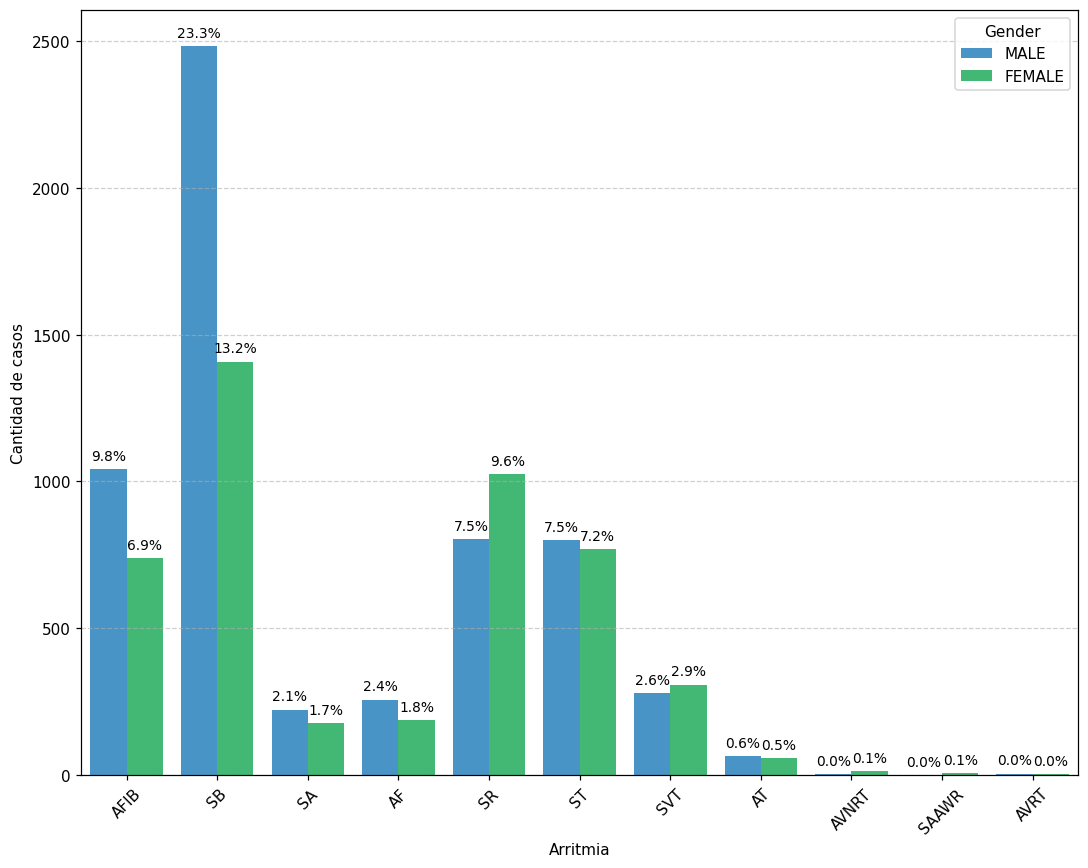

In [13]:
# Establece el tamaño de la figura del gráfico (12 pulgadas de ancho por 8 de alto)
plt.figure(figsize=(10, 8))

# Crea el gráfico de barras agrupando por género ('hue'), asignando azul y verde a través del argumento 'palette'
ax = sns.countplot(data=df, x='Rhythm', hue='Gender', palette=['#3498db', '#2ecc71'])

# Obtiene el número total de filas (pacientes) en la base de datos para calcular los porcentajes
total = len(df)

# Inicia un ciclo para recorrer cada una de las barras individuales (patches) generadas en el gráfico
for p in ax.patches:
    # Obtiene la altura de la barra actual (que equivale a la cantidad de pacientes en esa categoría)
    altura = p.get_height()
    
    # Verifica que la barra no esté vacía (altura > 0) para evitar colocar porcentajes en ceros
    if altura > 0:
        # Calcula el porcentaje relativo al total de pacientes y le da formato de un decimal con el símbolo '%'
        porcentaje = f'{(altura / total) * 100:.1f}%'
        
        # Inserta el texto del porcentaje en el gráfico
        ax.annotate(porcentaje, 
                    # Calcula la coordenada (x, y) donde irá el texto: el centro a lo ancho de la barra, y justo en el tope de su altura
                    (p.get_x() + p.get_width() / 2., altura), 
                    # Alinea el texto para que quede centrado horizontalmente (ha) y por encima del punto de anclaje (va)
                    ha='center', va='bottom', 
                    # Define el tamaño de la letra a 9 puntos y el color negro
                    fontsize=9, color='black', 
                    # Aplica un desplazamiento al texto de 0 en el eje X y 4 puntos hacia arriba en el eje Y para que no toque la barra
                    xytext=(0, 4), 
                    # Le indica a la función que el desplazamiento 'xytext' está medido en puntos de píxel relativos
                    textcoords='offset points')

# Etiqueta el eje Y (vertical) con el nombre 'Cantidad de casos'
plt.ylabel('Cantidad de casos')

# Etiqueta el eje X (horizontal) con el nombre 'Arritmia'
plt.xlabel('Arritmia')

# Rota las etiquetas de las arritmias en el eje X a 45 grados para que los nombres no se superpongan entre sí
plt.xticks(rotation=45)

# Agrega líneas de cuadrícula horizontales punteadas (axis='y') con una transparencia del 60% (alpha=0.6)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Ajusta automáticamente los márgenes de la figura para asegurar que los textos rotados no queden por fuera de la imagen
plt.tight_layout()

# Renderiza y muestra el gráfico final en la pantalla
plt.show()

C:\Users\12345\AppData\Local\Temp\ipykernel_15080\452524093.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Rhythm', y='PatientAge', palette='rocket')


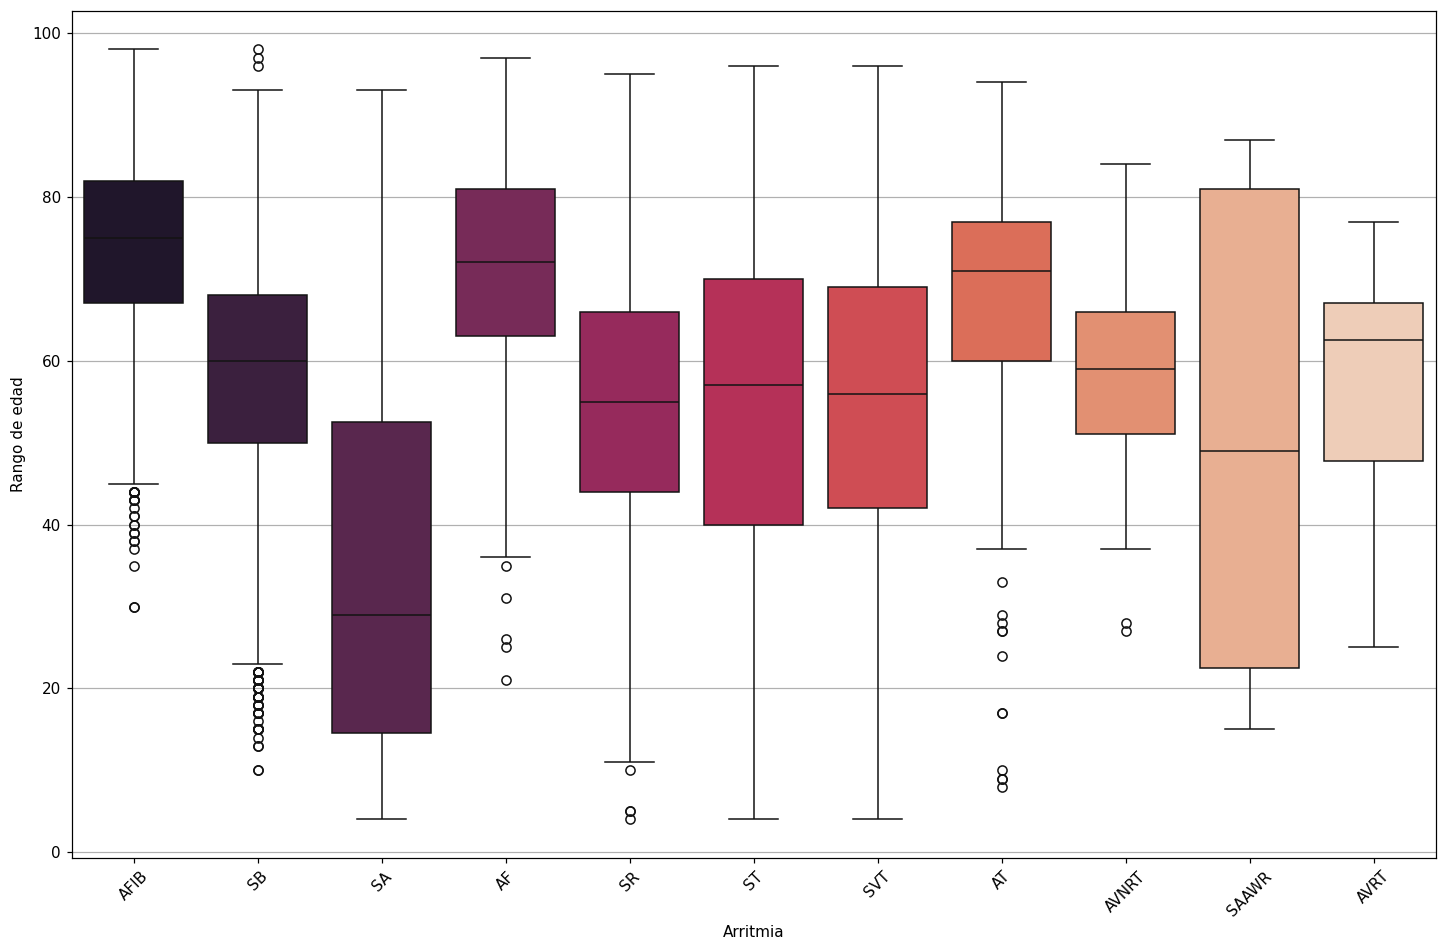

In [14]:
# Crea una nueva figura o lienzo para el gráfico, especificando un tamaño de 16 pulgadas de ancho por 10 pulgadas de alto.
plt.figure(figsize=(16, 10))

# Genera el diagrama de caja (boxplot) usando Seaborn. Cruza el tipo de arritmia (eje X) con la edad del paciente (eje Y) usando los datos de 'df' y aplica la paleta de colores cálidos 'rocket'.
sns.boxplot(data=df, x='Rhythm', y='PatientAge', palette='rocket')

# Define la etiqueta del eje vertical (Y) como 'Rango de edad'.
plt.ylabel('Rango de edad')

# Define la etiqueta del eje horizontal (X) como 'Arritmia'.
plt.xlabel('Arritmia')

# Rota los nombres de las arritmias en el eje X a 45 grados para evitar que los textos se superpongan y sean más fáciles de leer.
plt.xticks(rotation=45)

# Activa las líneas de la cuadrícula de fondo, aplicándolas únicamente de forma horizontal (eje Y) para facilitar la lectura de las edades.
plt.grid(axis='y')

# Procesa todos los comandos anteriores y despliega la gráfica final en pantalla.
plt.show()

Se formulas las siguientes hipóteesis:

-Hipótesis nula ($H_0$): La distribución de los ritmos cardíacos es la misma en ambos sexos, lo que significa que el tipo de arritmia es estadísticamente independiente del género del paciente.

-Hipótesis alternativa:($H_1$): La distribución de los ritmos cardíacos no es la misma en ambos sexos, lo que indica que existe una dependencia estadística significativa entre el género y el tipo de arritmia desarrollado.

In [15]:
# 1. Excluir las arritmias con muy pocos casos para asegurar que las frecuencias esperadas sean >= 5
clases_minoritarias = ['AVNRT', 'AVRT', 'SAAWR']
df_filtrado = df[~df['Rhythm'].isin(clases_minoritarias)]

# 2. Crear la tabla de contingencia (Frecuencias observadas entre Ritmo y Sexo)
tabla_contingencia = pd.crosstab(df_filtrado['Rhythm'], df_filtrado['Gender'])

print("--- Tabla de Contingencia (Casos Analizados) ---")
print(tabla_contingencia)
print("\n")

# 3. Aplicar la prueba estadística de Chi-cuadrado
chi2, p_valor, dof, frecuencias_esperadas = chi2_contingency(tabla_contingencia)

# 4. Calcular el tamaño del efecto (V de Cramér)
n_total = tabla_contingencia.sum().sum() # Total de pacientes tras el filtro
min_dim = min(tabla_contingencia.shape) - 1 # El mínimo entre (filas-1) y (columnas-1)
v_cramer = np.sqrt(chi2 / (n_total * min_dim))

# 5. Imprimir los resultados formales
print("--- Resultados de la Prueba Chi-cuadrado Global ---")
print(f"Estadístico Chi-cuadrado (χ²) : {chi2:.2f}")
print(f"Valor p                       : {p_valor:.2e}")
print(f"Grados de libertad            : {dof}")
print(f"V de Cramér                   : {v_cramer:.3f}")
print("-" * 55)

--- Tabla de Contingencia (Casos Analizados) ---
Gender  FEMALE  MALE
Rhythm              
AF         188   257
AFIB       739  1041
AT          57    64
SA         176   223
SB        1408  2481
SR        1024   802
ST         769   799
SVT        308   279


--- Resultados de la Prueba Chi-cuadrado Global ---
Estadístico Chi-cuadrado (χ²) : 242.81
Valor p                       : 9.38e-49
Grados de libertad            : 7
V de Cramér                   : 0.151
-------------------------------------------------------


In [16]:
# 6. Interpretar el tamaño del efecto según los umbrales definidos
if v_cramer < 0.1:
    efecto = "Despreciable"
elif v_cramer < 0.3:
    efecto = "Pequeño"
elif v_cramer < 0.5:
    efecto = "Moderado"
else:
    efecto = "Grande"

# 7. Conclusión automática
if p_valor < 0.05:
    print("Conclusión Estadística:")
    print("Se rechaza la hipótesis nula (H₀).")
    print(f"La distribución de los ritmos cardíacos NO es la misma en ambos sexos.")
    print(f"Tamaño del efecto (V de Cramér): {efecto}.")
else:
    print("Conclusión Estadística:")
    print("No se rechaza la hipótesis nula (H₀).")
    print("No hay evidencia suficiente para afirmar que la distribución difiere por sexo.")

Conclusión Estadística:
Se rechaza la hipótesis nula (H₀).
La distribución de los ritmos cardíacos NO es la misma en ambos sexos.
Tamaño del efecto (V de Cramér): Pequeño.


In [17]:
# 1. Calculamos el total poblacional de cada género en la base de datos
total_mujeres = (df['Gender'] == 'FEMALE').sum()
total_hombres = (df['Gender'] == 'MALE').sum()

# 2. Definimos el orden exacto de los ritmos según tu tabla de referencia
orden_ritmos = ['SB', 'SR', 'AFIB', 'ST', 'SVT', 'AF', 'SA', 'AT', 'AVNRT', 'AVRT', 'SAAWR']

# Calculamos el número total de pruebas simultáneas (11) para ajustar Bonferroni
num_pruebas = len(orden_ritmos)

# 3. Creamos una lista vacía que almacenará los resultados iterativos
resultados = []

# 4. Iniciamos un ciclo para analizar cada arritmia de manera individual
for ritmo in orden_ritmos:
    
    # Contamos cuántos pacientes de cada género SÍ tienen este ritmo específico
    mujeres_con = ((df['Gender'] == 'FEMALE') & (df['Rhythm'] == ritmo)).sum()
    hombres_con = ((df['Gender'] == 'MALE') & (df['Rhythm'] == ritmo)).sum()
    
    # Contamos cuántos pacientes de cada género NO tienen este ritmo (el resto)
    mujeres_sin = total_mujeres - mujeres_con
    hombres_sin = total_hombres - hombres_con
    
    # Calculamos el porcentaje relativo de afección dentro de cada grupo
    pct_mujeres = (mujeres_con / total_mujeres) * 100
    pct_hombres = (hombres_con / total_hombres) * 100
    
    # Comparamos los porcentajes para ver en qué población es más prevalente
    mayor_en = 'Mujeres' if pct_mujeres > pct_hombres else 'Hombres'
    
    # Estructuramos la matriz 2x2 (Con ritmo vs Sin ritmo) cruzada con (Mujeres vs Hombres)
    tabla_2x2 = [[mujeres_con, hombres_con], 
                 [mujeres_sin, hombres_sin]]
                 
    # Ejecutamos un Chi-cuadrado inicial para extraer las 'frecuencias esperadas' teóricas
    chi2, p_raw_chi, dof, esperadas = chi2_contingency(tabla_2x2)
    
    # Evaluamos el supuesto matemático: si alguna celda esperada es menor a 5, usamos Fisher
    if np.min(esperadas) < 5:
        prueba_usada = 'Fisher'
        # Ejecutamos Fisher y extraemos su valor p
        _, p_raw = fisher_exact(tabla_2x2)
    else:
        # Si todas las celdas esperadas son >= 5, es válido usar el Chi-cuadrado
        prueba_usada = 'Chi-cuadrado'
        p_raw = p_raw_chi
        
    # Aplicamos la corrección de Bonferroni multiplicando el valor p por 11 (tope máximo 1.0)
    p_bonferroni = min(p_raw * num_pruebas, 1.0)
    
    # Determinamos la significancia estadística usando el valor p penalizado (< 0.05)
    significativo = 'Sí' if p_bonferroni < 0.05 else 'No'
    
    # Guardamos todos los cálculos de esta iteración en un diccionario
    resultados.append({
        'Ritmo': ritmo,
        '% mujeres': pct_mujeres,
        '% hombres': pct_hombres,
        'Prueba': prueba_usada,
        'p': p_raw,
        'p Bonferroni': p_bonferroni,
        'Mayor en': mayor_en,
        '¿Significativo?': significativo
    })

# 5. Convertimos la lista de diccionarios en un DataFrame de Pandas
df_resultados = pd.DataFrame(resultados)

# 6. Convertimos la columna 'Ritmo' en el índice de la tabla para replicar tu formato visual
df_resultados.set_index('Ritmo', inplace=True)

# (Opcional) Le damos formato científico a los valores 'p' para que se vean como en la imagen
pd.options.display.float_format = '{:g}'.format

# 7. Mostramos la tabla final generada
display(df_resultados)

,% mujeres,% hombres,Prueba,p,p Bonferroni,Mayor en,¿Significativo?
Ritmo,,,,,,,
SB,30.0213,41.6555,Chi-cuadrado,4.51147e-35,4.96262e-34,Hombres,Sí
SR,21.8337,13.4654,Chi-cuadrado,7.82054e-30,8.60259e-29,Mujeres,Sí
AFIB,15.7569,17.4782,Chi-cuadrado,0.0194583,0.214041,Hombres,No
ST,16.3966,13.415,Chi-cuadrado,1.8523e-05,0.000203753,Mujeres,Sí
SVT,6.56716,4.68435,Chi-cuadrado,2.88153e-05,0.000316969,Mujeres,Sí
AF,4.00853,4.31498,Chi-cuadrado,0.461986,1,Hombres,No
SA,3.75267,3.74412,Chi-cuadrado,1,1,Mujeres,No
AT,1.21535,1.07455,Chi-cuadrado,0.556312,1,Mujeres,No
AVNRT,0.255864,0.0671592,Chi-cuadrado,0.0248798,0.273678,Mujeres,No


In [18]:
# Calcular el promedio y la desviación estándar de la edad por género
edades_stats = df.groupby('Gender')['PatientAge'].agg(['mean', 'std']).round(2)
print("Promedio de edad por género:")
print(edades_stats)

Promedio de edad por género:
        mean   std
Gender            
FEMALE 58.05 18.22
MALE   60.08 17.83


## Interpretación de los resultados

El valor p obtenido (9.38e-49) es extremadamente bajo, lo que permite rechazar la hipótesis nula y confirmar contundentemente que existe una relación estadísticamente significativa entre el género y el tipo de arritmia. Sin embargo, el valor de la V de Cramér (0.151) indica que el tamaño de este efecto es pequeño, lo que significa que la asociación, aunque matemáticamente real, es débil y el género no es un factor determinante por sí solo. 

## Taquicardias y predisposición femenina (ST, SVT)
La mayor prevalencia de Taquicardia Sinusal (ST) y Taquicardia Supraventricular (SVT) en mujeres concuerda sólidamente con la literatura médica. Estudios electrofisiológicos demuestran que las mujeres presentan, en promedio, una frecuencia cardíaca basal más alta (entre 3 y 5 latidos por minuto mayor que los hombres) y un período refractario del nodo auriculoventricular más corto [5]. Estas diferencias, mediadas por los efectos de los estrógenos sobre los canales iónicos, incrementan de manera natural la susceptibilidad del corazón femenino a desarrollar taquicardias, especialmente aquellas causadas por circuitos de reentrada [6].

## Bradicardia y predisposición masculina (SB)
La mayor frecuencia de Bradicardia Sinusal (SB) en la cohorte masculina se alinea con investigaciones poblacionales que documentan un mayor tono vagal (parasimpático) intrínseco y una menor tasa de despolarización espontánea del nodo sinusal en hombres [1], [2]. Esta condición suele ser fisiológica y se asocia frecuentemente con diferencias en la masa muscular y el acondicionamiento cardiovascular.

## Limitación fisiológica y demográfica (Factor de confusión por edad)
El análisis actual asume que las diferencias en las arritmias se deben puramente al sexo biológico, omitiendo el control de la edad como variable clínica fundamental. Fisiológicamente, el envejecimiento provoca fibrosis miocárdica, degeneración del sistema de conducción y alteraciones estructurales que disparan la incidencia de arritmias, especialmente la Fibrilación Auricular (AFIB). En la bases datos el promedio de edad de la mujeres es de 58,05 años y el de los hombres de 60,08 años.

## ¿Hay arritmias que son más prevalentes para una edad?

<Axes: xlabel='PatientAge', ylabel='Count'>

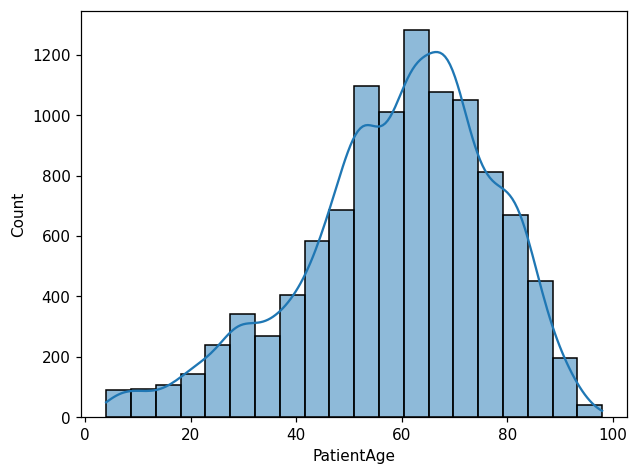

In [19]:
df['PatientAge'].describe()
sns.histplot(df['PatientAge'], bins=20, kde=True)

In [20]:
# Excluir las clases minoritarias para ambos análisis
clases_minoritarias = ['AVNRT', 'AVRT', 'SAAWR']
df_filtrado = df[~df['Rhythm'].isin(clases_minoritarias)].copy()

# =====================================================================
# ÁNGULO 1: Edad dentro de cada ritmo (Estadística Descriptiva y Kruskal-Wallis)
# =====================================================================

# 1.1 Calcular Media, Desviación Estándar, Mediana y Rango Intercuartílico (IQR)
stats_edad = df_filtrado.groupby('Rhythm')['PatientAge'].agg(
    Media='mean',
    Desv_Estandar='std',
    Mediana='median',
    IQR=iqr
).round(2)

print("--- 1. Estadísticas Descriptivas de Edad por Ritmo ---")
print(stats_edad)
print("\n")

# 1.2 Extraer los arreglos de edades para cada ritmo y aplicar Kruskal-Wallis
grupos_edades = [grupo['PatientAge'].values for nombre, grupo in df_filtrado.groupby('Rhythm')]
h_stat, p_kw = kruskal(*grupos_edades)

# 1.3 Calcular el tamaño del efecto Épsilon Cuadrado (ε²)
n_total = len(df_filtrado)
epsilon_sq = h_stat / (n_total - 1)

print("--- 1. Resultados Kruskal-Wallis (Edad en cada Ritmo) ---")
print(f"Estadístico H      : {h_stat:.2f}")
print(f"Valor p            : {p_kw:.2e}")
print(f"Épsilon Cuadrado ε²: {epsilon_sq:.4f}")
if p_kw < 0.05:
    print("Conclusión         : Se rechaza H₀. La edad NO se distribuye igual en todos los ritmos.")
print("\n")

# Calcular la asimetría de la edad usando pandas
asimetria = df['PatientAge'].skew()
print(f"Asimetría de la edad: {asimetria:.2f}")

--- 1. Estadísticas Descriptivas de Edad por Ritmo ---
        Media  Desv_Estandar  Mediana  IQR
Rhythm                                    
AF      71.07           13.5       72   18
AFIB    73.36          11.14       75   15
AT      65.72           19.3       71   17
SA      34.75          23.03       29   38
SB      58.34          13.95       60   18
SR      54.35          16.33       55   22
ST      54.57          21.06       57   30
SVT     55.62          18.53       56   27


--- 1. Resultados Kruskal-Wallis (Edad en cada Ritmo) ---
Estadístico H      : 2221.95
Valor p            : 0.00e+00
Épsilon Cuadrado ε²: 0.2093
Conclusión         : Se rechaza H₀. La edad NO se distribuye igual en todos los ritmos.


Asimetría de la edad: -0.61


Tras confirmar matemáticamente mediante el cálculo de asimetría (-0.61) que la mayoría de los pacientes se concentran en edades avanzadas, la variable continua de la edad se transformó en rangos categóricos ordinales utilizando límites predefinidos (menores de 18, 18 a 30, y décadas sucesivas hasta mayores de 80). Mediante la función pd.cut, cada paciente fue asignado a su respectivo intervalo temporal, lo que permitió agrupar la base de datos para extraer las frecuencias absolutas (n) y relativas (%) de cada grupo, consolidando así toda la distribución demográfica en una única tabla descriptiva.

In [21]:
# =====================================================================
# ÁNGULO 2: Ritmo dentro de cada grupo de edad (Agrupación y Chi-cuadrado)
# =====================================================================

# 2.1 Agrupar a los pacientes por décadas (0-19, 20-29, 30-39, etc.)
cortes_decadas = [0, 19, 29, 39, 49, 59, 69, 79, 89, 120]
etiquetas_decadas = ['<20', '20-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80-89', '90+']
df_filtrado['Rango_Edad'] = pd.cut(df_filtrado['PatientAge'], bins=cortes_decadas, labels=etiquetas_decadas, right=True)

# 2.2 Calcular el porcentaje de cada ritmo dentro de cada grupo de edad
tabla_frecuencias_edad = pd.crosstab(df_filtrado['Rango_Edad'], df_filtrado['Rhythm'])
tabla_porcentajes_edad = pd.crosstab(df_filtrado['Rango_Edad'], df_filtrado['Rhythm'], normalize='index') * 100

print("--- 2. Porcentaje de Ritmos por Década de Vida ---")
print(tabla_porcentajes_edad.round(1))
print("\n")

# 2.3 Aplicar prueba Chi-cuadrado global
chi2_edad, p_chi_edad, dof_edad, esperadas_edad = chi2_contingency(tabla_frecuencias_edad)

# 2.4 Validar la regla de frecuencias esperadas (<= 20% < 5, ninguna < 1)
total_celdas = esperadas_edad.size
celdas_menores_5 = (esperadas_edad < 5).sum()
porcentaje_menores_5 = (celdas_menores_5 / total_celdas) * 100
min_esperada = esperadas_edad.min()

print("--- 2. Resultados Chi-cuadrado (Ritmo en cada Edad) ---")
print(f"Estadístico χ²     : {chi2_edad:.2f}")
print(f"Valor p            : {p_chi_edad:.2e}")
print(f"Celdas < 5         : {porcentaje_menores_5:.1f}% (Límite 20%)")
print(f"Frecuencia min     : {min_esperada:.2f} (Debe ser >= 1)")

if porcentaje_menores_5 <= 20 and min_esperada >= 1:
    print("Validación         : La prueba Chi-cuadrado es estadísticamente válida.")
else:
    print("Validación         : ADVERTENCIA. Se violan los supuestos de frecuencias esperadas.")

--- 2. Porcentaje de Ritmos por Década de Vida ---
Rhythm      AF  AFIB  AT   SA   SB   SR   ST  SVT
Rango_Edad                                       
<20          0     0 1.9 43.2  9.5  9.5 32.4  3.5
20-29      0.6     0   1 13.1 24.9 23.9 27.4    9
30-39      0.6   1.1 0.3  7.1   33 29.2 19.8  8.8
40-49      2.1   4.2 0.4  3.3 41.5 24.3 15.7  8.7
50-59      2.2   6.9 0.5  1.5 49.5 21.1   13  5.4
60-69        4  15.1   1  1.4 46.2 15.7 12.2  4.4
70-79      7.3  30.9 2.4  1.6 30.3 12.4 11.7  3.4
80-89      8.1  45.5 1.4  0.9 16.5  7.9   15  4.7
90+         19  42.9 4.2  1.2  7.7  4.2 11.3  9.5


--- 2. Resultados Chi-cuadrado (Ritmo en cada Edad) ---
Estadístico χ²     : 4145.23
Valor p            : 0.00e+00
Celdas < 5         : 2.8% (Límite 20%)
Frecuencia min     : 1.92 (Debe ser >= 1)
Validación         : La prueba Chi-cuadrado es estadísticamente válida.


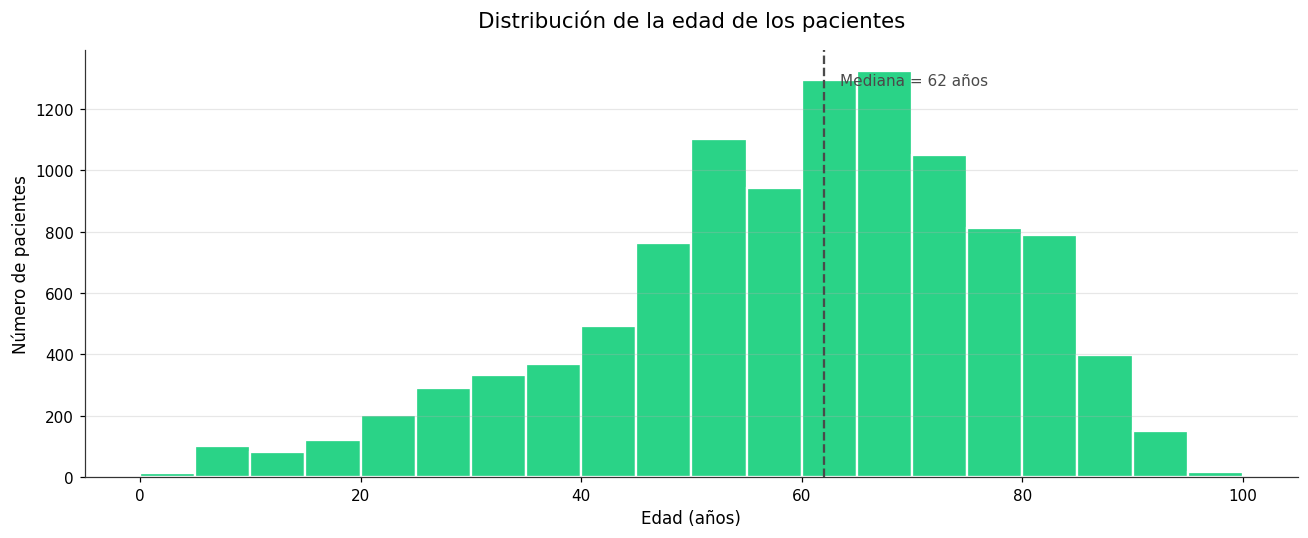

In [22]:
#Histograma de la edad de los pacientes con línea de mediana
# 1. Configurar el tamaño de la figura
plt.figure(figsize=(12, 5))

# 2. Calcular la mediana de la edad de tu dataset
mediana_edad = df['PatientAge'].median()

# 3. Crear el histograma con barras azules y bordes blancos
# Usamos bins de 5 en 5 años (de 0 a 105) para replicar la estructura de la imagen
plt.hist(df['PatientAge'].dropna(), bins=np.arange(0, 105, 5), 
         color="#2AD387", edgecolor='white', linewidth=1.5)

# 4. Agregar la línea vertical punteada para la mediana
plt.axvline(mediana_edad, color='#4A4A4A', linestyle='--', linewidth=1.5)

# 5. Agregar el texto indicando el valor exacto de la mediana
# Se posiciona un poco a la derecha de la línea (+1.5 en el eje X) y en la parte alta del eje Y
plt.text(mediana_edad + 1.5, plt.gca().get_ylim()[1] * 0.92, 
         f'Mediana = {int(mediana_edad)} años', 
         color='#4A4A4A', fontsize=10)

# 6. Personalizar etiquetas y título
plt.title('Distribución de la edad de los pacientes', fontsize=14, pad=15)
plt.xlabel('Edad (años)', fontsize=11)
plt.ylabel('Número de pacientes', fontsize=11)

# 7. Agregar cuadrícula horizontal suave
plt.grid(axis='y', linestyle='-', alpha=0.3)

# 8. Eliminar los bordes superior y derecho para dar un aspecto más limpio
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_color('#333333')
plt.gca().spines['bottom'].set_color('#333333')

# 9. Mostrar el gráfico
plt.tight_layout()
plt.show()

In [23]:
# Agrupamos el DataFrame original por la columna 'Rhythm' y seleccionamos 'PatientAge' para operarla
tabla_estadisticas = df.groupby('Rhythm')['PatientAge'].agg(
    # 'count' cuenta la cantidad total de pacientes para cada ritmo y la nombra 'n'
    n='count',
    
    # 'mean' calcula el promedio de edad y la nombra 'media'
    media='mean',
    
    # 'std' calcula la desviación estándar y la nombra 'DE'
    DE='std',
    
    # 'median' calcula el valor central de las edades y la nombra 'mediana'
    mediana='median',
    
    # Usamos una función lambda para calcular el percentil 25 (Primer cuartil) y la nombra 'Q1'
    Q1=lambda x: x.quantile(0.25),
    
    # Usamos una función lambda para calcular el percentil 75 (Tercer cuartil) y la nombra 'Q3'
    Q3=lambda x: x.quantile(0.75),
    
    # 'min' busca la edad más baja en ese grupo y la nombra 'mín'
    mín='min',
    
    # 'max' busca la edad más alta en ese grupo y la nombra 'máx'
    máx='max'
)

# Ordenamos la tabla resultante usando la columna 'n' de mayor a menor (descendente)
tabla_estadisticas = tabla_estadisticas.sort_values(by='n', ascending=False)

# Redondeamos las columnas que tienen valores continuos a 1 solo decimal para coincidir visualmente
columnas_decimales = ['media', 'DE', 'mediana', 'Q1', 'Q3']
tabla_estadisticas[columnas_decimales] = tabla_estadisticas[columnas_decimales].round(1)

# Convertimos las columnas de conteo y límites a números enteros para eliminar decimales innecesarios (ej. 60.0 -> 60)
columnas_enteras = ['n', 'mín', 'máx']
tabla_estadisticas[columnas_enteras] = tabla_estadisticas[columnas_enteras].astype(int)

# Desplegamos la tabla final renderizada en el entorno visual (Jupyter)
display(tabla_estadisticas)

,n,media,DE,mediana,Q1,Q3,mín,máx
Rhythm,,,,,,,,
SB,3889,58.3,14,60,50,68,10,98
SR,1826,54.4,16.3,55,44,66,4,95
AFIB,1780,73.4,11.1,75,67,82,30,98
ST,1568,54.6,21.1,57,40,70,4,96
SVT,587,55.6,18.5,56,42,69,4,96
AF,445,71.1,13.5,72,63,81,21,97
SA,399,34.7,23,29,14.5,52.5,4,93
AT,121,65.7,19.3,71,60,77,8,94
AVNRT,16,57.9,17.3,59,51,66,27,84


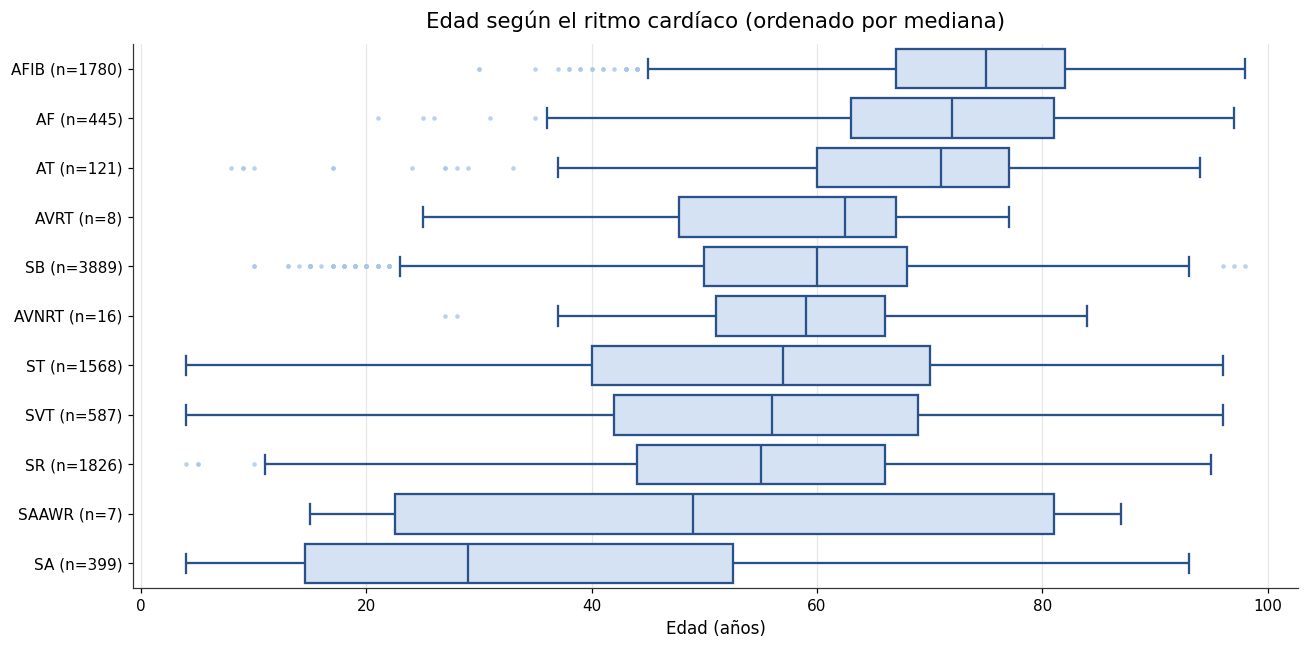

In [24]:
# 1. Calcular la mediana y el conteo (n) de pacientes para cada ritmo
stats = df.groupby('Rhythm')['PatientAge'].agg(['median', 'count'])

# 2. Ordenar los resultados por la mediana de mayor a menor (descendente)
stats = stats.sort_values(by='median', ascending=False)

# 3. Crear un diccionario para modificar los nombres de los ritmos agregando su 'n'
# Por ejemplo: transforma 'AFIB' en 'AFIB (n=1780)'
mapeo_etiquetas = {ritmo: f"{ritmo} (n={int(fila['count'])})" for ritmo, fila in stats.iterrows()}

# 4. Aplicar el nuevo formato de etiquetas a una nueva columna temporal en el DataFrame
df['Rhythm_Label'] = df['Rhythm'].map(mapeo_etiquetas)

# 5. Obtener la lista ordenada de las nuevas etiquetas para decirle a Seaborn el orden exacto del eje Y
orden_ritmos = [mapeo_etiquetas[r] for r in stats.index]

# 6. Configurar el tamaño del lienzo de la figura
plt.figure(figsize=(12, 6))

# 7. Generar el boxplot horizontal (x='PatientAge', y='Rhythm_Label')
ax = sns.boxplot(
    data=df, 
    x='PatientAge', 
    y='Rhythm_Label', 
    order=orden_ritmos,
    color='#D0E1F9',       # Color de relleno azul claro para las cajas
    linewidth=1.5,         # Grosor de las líneas
    fliersize=3,           # Tamaño de los puntos atípicos (outliers)
    # Personalizar los puntos atípicos (outliers) para que sean celestes y sin borde
    flierprops=dict(marker='o', markerfacecolor='#A9C6EB', markeredgecolor='none', alpha=0.8) 
)

# 8. Modificar el color de los bordes de las cajas a un azul más oscuro
for caja in ax.patches:
    caja.set_edgecolor('#2A528A')

# 9. Modificar el color de las líneas restantes (bigotes, extremos y la línea de la mediana)
for linea in ax.lines:
    linea.set_color('#2A528A')

# 10. Configurar los títulos y las etiquetas de los ejes
plt.title('Edad según el ritmo cardíaco (ordenado por mediana)', fontsize=14, pad=10)
plt.xlabel('Edad (años)', fontsize=11)
plt.ylabel('') # Dejamos el eje Y sin texto porque las etiquetas ya son autodescriptivas

# 11. Activar las líneas de la cuadrícula verticalmente con transparencia
plt.grid(axis='x', linestyle='-', alpha=0.3)

# 12. Ocultar las líneas superior y derecha del marco del gráfico (estilo minimalista)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#333333')
ax.spines['bottom'].set_color('#333333')

# 13. Ajustar márgenes y renderizar el gráfico final
plt.tight_layout()
plt.show()

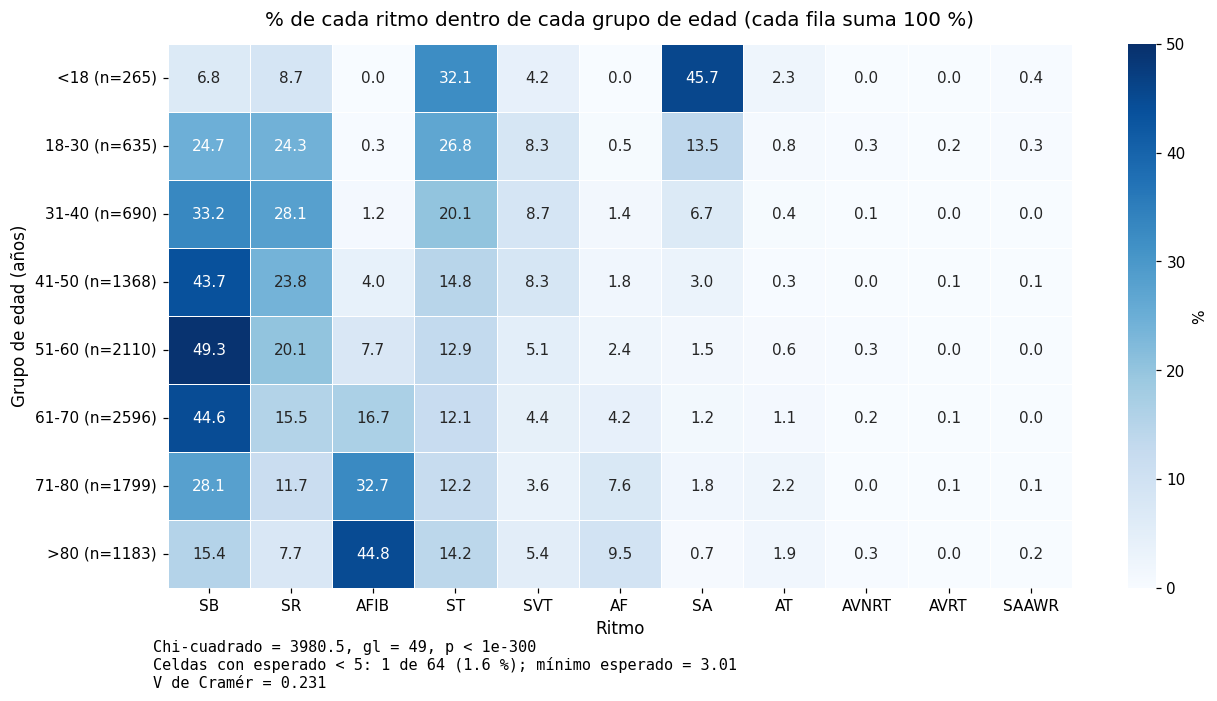

In [25]:
# 1. Definir los intervalos de edad y sus etiquetas
cortes = [-1, 17, 30, 40, 50, 60, 70, 80, 150]
etiquetas_edades = ['<18', '18-30', '31-40', '41-50', '51-60', '61-70', '71-80', '>80']

# Crear la columna de 'GrupoEdad' en el DataFrame
df['GrupoEdad'] = pd.cut(df['PatientAge'], bins=cortes, labels=etiquetas_edades)

# 2. Calcular los tamaños de muestra (n) para cada grupo y formatear las etiquetas del eje Y
totales_edad = df['GrupoEdad'].value_counts(sort=False)
etiquetas_y = [f"{edad} (n={totales_edad[edad]})" for edad in etiquetas_edades]

# 3. Crear la tabla cruzada con porcentajes por fila (normalize='index' hace que sumen 100% horizontalmente)
tabla_pct = pd.crosstab(df['GrupoEdad'], df['Rhythm'], normalize='index') * 100

# Ordenar las columnas (ritmos) exactamente como en la imagen
orden_ritmos = ['SB', 'SR', 'AFIB', 'ST', 'SVT', 'AF', 'SA', 'AT', 'AVNRT', 'AVRT', 'SAAWR']
tabla_pct = tabla_pct[orden_ritmos]

# Reemplazar el índice original con las nuevas etiquetas que incluyen el (n)
tabla_pct.index = etiquetas_y

# 4. Calcular los estadísticos de Chi-cuadrado (Excluyendo las 3 clases minoritarias según metodología)
ritmos_chi = ['SB', 'SR', 'AFIB', 'ST', 'SVT', 'AF', 'SA', 'AT']
df_chi = df[df['Rhythm'].isin(ritmos_chi)]
tabla_chi = pd.crosstab(df_chi['GrupoEdad'], df_chi['Rhythm'])

chi2, p_valor, gl, esperados = chi2_contingency(tabla_chi)

# Calcular el número de celdas con valores esperados menores a 5
total_celdas = esperados.size
celdas_menores_5 = (esperados < 5).sum()
pct_menores_5 = (celdas_menores_5 / total_celdas) * 100
min_esperado = esperados.min()

# Calcular el tamaño del efecto (V de Cramér)
n_total = tabla_chi.sum().sum()
min_dim = min(tabla_chi.shape) - 1
v_cramer = np.sqrt(chi2 / (n_total * min_dim))

# 5. Configurar el tamaño de la figura para alojar el gráfico y el texto inferior
plt.figure(figsize=(12, 6))

# 6. Generar el mapa de calor (Heatmap)
ax = sns.heatmap(
    tabla_pct, 
    annot=True,              # Muestra los valores numéricos dentro de cada celda
    fmt=".1f",               # Formatea los números a 1 solo decimal
    cmap="Blues",            # Aplica la paleta de colores azules
    vmin=0, vmax=50,         # Fija el rango de la barra de color de 0 a 50 (evita que un 49% acapare todo el color oscuro)
    cbar_kws={'label': '%'}, # Añade la etiqueta '%' a la barra de color lateral
    linewidths=0.5           # Añade una ligera separación visual entre celdas (opcional para estética)
)

# 7. Configurar títulos y etiquetas de los ejes
plt.title('% de cada ritmo dentro de cada grupo de edad (cada fila suma 100 %)', fontsize=13, pad=12)
plt.xlabel('Ritmo', fontsize=11)
plt.ylabel('Grupo de edad (años)', fontsize=11)

# Asegurar que las etiquetas del eje Y estén horizontales para facilitar su lectura
plt.yticks(rotation=0)

# 8. Dar formato al texto estadístico de la parte inferior
# Si el p-valor es 0.0 por limitaciones flotantes, lo representamos como < 1e-300 como en tu imagen
str_p = "< 1e-300" if p_valor == 0 else f"{p_valor:.2e}"

texto_estadistico = (
    f"Chi-cuadrado = {chi2:.1f}, gl = {gl}, p {str_p}\n"
    f"Celdas con esperado < 5: {celdas_menores_5} de {total_celdas} ({pct_menores_5:.1f} %); mínimo esperado = {min_esperado:.2f}\n"
    f"V de Cramér = {v_cramer:.3f}"
)

# 9. Insertar el bloque de texto en las coordenadas de la figura (debajo del gráfico)
# Se usa fontfamily='monospace' para imitar el aspecto de texto de consola de tu captura
plt.figtext(0.12, -0.05, texto_estadistico, ha="left", fontsize=10, fontfamily='monospace')

# 10. Ajustar los márgenes para que todo encaje sin cortarse y renderizar
plt.tight_layout()
plt.show()

## Interpretacion

**Significancia y Validación Estadística:** El valor p obtenido en la prueba de Chi-cuadrado (< 1e-300) indica que existe una dependencia estadísticamente significativa entre el grupo de edad y el tipo de ritmo desarrollado. Desde el punto de vista metodológico, la prueba es completamente válida: solo el 1.6% de las celdas (1 de 64) presentó una frecuencia esperada menor a 5, y el mínimo esperado fue de 3.01. Esto cumple estrictamente con el criterio estadístico de aceptar hasta un 20% de celdas con valores esperados menores a 5 [7], garantizando que el tamaño de la muestra es robusto.

**Patrones Clínicos en Población Joven (<30 años):** Los datos demuestran que las alteraciones del ritmo en pacientes jóvenes están ligadas principalmente al automatismo sinusal. En el grupo pediátrico y adolescente (<18 años), predomina fuertemente la Arritmia Sinusal (SA) con un 45.7%, lo cual concuerda con la literatura médica que cataloga este ritmo como un hallazgo fisiológico normal y benigno en jóvenes, asociado a la variabilidad de la frecuencia cardíaca inducida por la respiración [8]. Entre los 18 y 30 años, los ritmos predominantes son la Taquicardia Sinusal (ST) con 26.8% y la Bradicardia Sinusal (SB) con 24.7%.

**Transición Patológica en Edad Avanzada (>60 años):** El mapa de calor revela una clara transición epidemiológica impulsada por el envejecimiento cardiovascular. A partir de los 60 años, la incidencia de arritmias estructurales se dispara debido a la fibrosis miocárdica celular y la degeneración del sistema de conducción [9]. La Fibrilación Auricular (AFIB), que tiene una presencia casi nula en pacientes jóvenes, crece exponencialmente década tras década hasta convertirse en la arritmia dominante absoluta [7], [3]. En los pacientes mayores de 80 años, el 44.8% de los diagnósticos corresponden a AFIB, desplazando por completo al Ritmo Sinusal (SR), que cae a apenas un 7.7%.

**Magnitud de la Asociación (V de Cramér):** El valor de la V de Cramér (0.231) clasifica el tamaño del efecto en el umbral entre pequeño y moderado. Sin embargo, al comparar este resultado con el obtenido previamente en la variable de género (V = 0.151), queda en evidencia que la edad tiene un peso predictivo mucho mayor que el sexo biológico para determinar el perfil arrítmico de un paciente [7]. El envejecimiento actúa como el principal catalizador en esta cohorte para la aparición de arritmias complejas.

**Contraste con la evidencia científica:** El incremento progresivo de la fibrilación auricular (FA) en pacientes mayores respalda los hallazgos de investigaciones clínicas previas, como el estudio ATRIA. Sin embargo, la incidencia reportada en esta base de datos es significativamente superior a la de la población general debido a un sesgo de selección: la muestra está compuesta exclusivamente por pacientes hospitalarios con una indicación médica previa para realizarse un electrocardiograma. Por otro lado, la notable concentración de arritmias sinusales en la población joven representa un comportamiento fisiológico normal, ya que la irregularidad del ritmo impulsada por el ciclo respiratorio es naturalmente más intensa en niños y adultos jóvenes.   

**Sesgo diagnóstico en pacientes pediátricos (<18 años):** Es fundamental reconocer que los rangos normales de frecuencia cardíaca en niños son inherentemente más elevados que en los adultos. Esto indica que el 32,1 % de los diagnósticos de "taquicardia sinusal" en pacientes menores de 18 años es, muy probablemente, un error de clasificación causado por evaluar ritmos pediátricos saludables utilizando umbrales diagnósticos de adultos (frecuencias superiores a 100 lpm). Para evitar que este sesgo contamine los patrones de los algoritmos de aprendizaje, se recomienda metodológicamente excluir a la población menor de 18 años del conjunto de datos definitivo. 

## Los algoritmos de aprendizaje se basan en usar la mayor cantidad de datos posibles que sean comparables, ¿Qué rango de edades y arritmias de la base de datos entregada considera que debe usar para entrenar algoritmos de aprendizaje?

Para entrenar un modelo de inteligencia artificial capaz de procesar señales ECG y generar recomendaciones clínicas precisas, la selección del conjunto de datos debe aislar la variabilidad fisiológica extrema y el sesgo estadístico.

Rango de edades recomendado: Adultos (≥ 18 años)

**Exclusión de población pediátrica y juvenil(<18 años):** Este grupo representa apenas el 2.49% de los datos y presenta un perfil eléctrico basal distinto, dominado por la Arritmia Sinusal (SA) como hallazgo fisiológico. Incluirlos forzaría al algoritmo a intentar generalizar excepciones con muy pocos ejemplos.

**Núcleo de entrenamiento:** Focalizar el modelo en pacientes mayores de 18 años (o incluso mayores de 30 años, donde comienza el mayor volumen de datos) concentra el aprendizaje en la matriz de datos más densa, garantizando que el algoritmo asimile patrones morfológicos consistentes de arritmias estructurales y de conducción típicas del adulto.

**Arritmias recomendadas: 8 clases principales**

**Exclusión de clases ultra-minoritarias (AVNRT, AVRT, SAAWR):** Con 16, 8 y 7 casos respectivamente, carecen del volumen mínimo viable para el aprendizaje profundo. Forzar su inclusión provocará inevitablemente un sobreajuste (overfitting) severo y confusión en la matriz de confusión del modelo.

**Inclusión de las clases base:** Conservar Bradicardia Sinusal (SB), Ritmo Sinusal (SR), Fibrilación Auricular (AFIB), Taquicardia Sinusal (ST), Taquicardia Supraventricular (SVT), Aleteo Auricular (AF), Arritmia Sinusal (SA) y Taquicardia Auricular (AT).

**Gestión del desbalance:** Dado que la cohorte recomendada presenta una asimetría extrema (ej. 3889 casos de SB frente a 121 casos de AT), será obligatorio implementar técnicas en el preprocesamiento —como sobremuestreo de clases minoritarias, submuestreo cuidadoso de SB, o funciones de pérdida ponderada (weighted loss)— para evitar que el algoritmo clasifique todo como Bradicardia Sinusal por simple probabilidad estadística.

Para asegurar el entrenamiento óptimo del algoritmo con datos comparables, el subconjunto metodológico excluye a los menores de 18 años, evitando así que sus altas frecuencias cardíacas normales introduzcan falsos diagnósticos de taquicardia basados en umbrales de adulto, sin fijar un límite superior para preservar los vitales casos de fibrilación auricular en la tercera edad. Simultáneamente, para solucionar la escasez de ejemplos, las arritmias se reestructuran agrupando clases minoritarias o clínicamente equivalentes en categorías robustas consolidadas (SB, AFIB, GSVT, SR y ST). Finalmente, se decidió conservar los registros de pacientes con condiciones cardíacas adicionales para no reducir drásticamente la muestra disponible (especialmente en los casos de fibrilación auricular), delegando el control de este factor a futuros análisis de sensibilidad.

In [115]:
# Filtrar la base de datos para conservar solo adultos (mayores o iguales a 18 años)
df_modelo = df[df['PatientAge'] >= 18].copy()

# Calcular las variables de conteo
total_original = len(df)
total_subconjunto = len(df_modelo)
excluidos = total_original - total_subconjunto
porcentaje = (total_subconjunto / total_original) * 100

# Imprimir los resultados imitando el formato de consola
print(f"Pacientes en la base completa: {total_original}")
print(f"Pacientes en el subconjunto:   {total_subconjunto}   ({porcentaje:.1f} %)")
print(f"Excluidos:                     {excluidos}")

Pacientes en la base completa: 10646
Pacientes en el subconjunto:   10381   (97.5 %)
Excluidos:                     265


In [116]:
# 1. Filtrar pacientes mayores o iguales a 18 años
df_adultos = df[df['PatientAge'] >= 18].copy()

# 2. Mapear los ritmos originales a los nuevos grupos según la metodología
mapeo_ritmos = {
    'SB': 'SB',
    'AFIB': 'AFIB', 'AF': 'AFIB',
    'SVT': 'GSVT', 'AT': 'GSVT', 'AVNRT': 'GSVT', 'AVRT': 'GSVT', 'SAAWR': 'GSVT', # Asumiendo SAAWR como marcapasos migratorio
    'SR': 'SR', 'SA': 'SR', # Asumiendo SA como irregularidad sinusal
    'ST': 'ST'
}
df_adultos['Grupo'] = df_adultos['Rhythm'].map(mapeo_ritmos)

# 3. Calcular las métricas por Grupo
# n (Conteo total por grupo)
n_total = df_adultos.groupby('Grupo').size()

# % (Porcentaje sobre el total de adultos)
pct_total = (n_total / len(df_adultos) * 100).round(2)

# n sin condiciones adicionales 
# (NOTA: Ajusta 'NORMAL' según cómo aparezca en tu columna 'Beat' o equivalentes para indicar sin patologías extra)
n_sin_condiciones = df_adultos[df_adultos['Beat'] == 'NORMAL'].groupby('Grupo').size()

# Edad mediana
edad_mediana = df_adultos.groupby('Grupo')['PatientAge'].median().round(1)

# % mujeres
# (NOTA: Ajusta 'Female' si en tu dataset el género femenino está etiquetado distinto, ej. 'F' o 0/1)
mujeres_totales_grupo = df_adultos[df_adultos['Gender'] == 'Female'].groupby('Grupo').size()
pct_mujeres = (mujeres_totales_grupo / n_total * 100).round(1)

# 4. Ensamblar la tabla final
tabla_subconjunto = pd.DataFrame({
    'n': n_total,
    '%': pct_total,
    'n sin condiciones adicionales': n_sin_condiciones,
    'Edad mediana': edad_mediana,
    '% mujeres': pct_mujeres
})

# 5. Ordenar las filas exactamente como en la imagen
orden_filas = ['SB', 'SR', 'AFIB', 'GSVT', 'ST']
tabla_subconjunto = tabla_subconjunto.reindex(orden_filas)

# 6. Formatear la columna 'n sin condiciones adicionales' como entero (evita decimales si hay nulos)
tabla_subconjunto['n sin condiciones adicionales'] = tabla_subconjunto['n sin condiciones adicionales'].fillna(0).astype(int)

# Mostrar la tabla
display(tabla_subconjunto)

,n,%,n sin condiciones adicionales,Edad mediana,% mujeres
Grupo,,,,,
SB,3871,37.29,0,60,NaN
SR,2081,20.05,0,54,NaN
AFIB,2225,21.43,0,74,NaN
GSVT,721,6.95,0,59,NaN
ST,1483,14.29,0,59,NaN


El subconjunto final de datos destinado al entrenamiento de los algoritmos se restringe a pacientes de 18 años o más y consolida las señales en cinco categorías clínicas principales para garantizar un volumen robusto de ejemplos y evitar la confusión algorítmica entre diagnósticos equivalentes [2] [4]:

SB (Bradicardia Sinusal): Constituye el grupo mayoritario (37.29 %, n=3871), compuesto exclusivamente por casos de bradicardia pura con una mediana de edad de 60 años.

AFIB (Fibrilación y Flutter Auricular): Representa el 21.43 % (n=2225) y concentra a la población más envejecida (mediana de 74 años). Unifica ambas patologías debido a su frecuente coexistencia clínica, tratamiento compartido y alta probabilidad de solapamiento en modelos computacionales.

SR (Ritmo Sinusal): Establece la línea base de normalidad al agrupar el ritmo sinusal estándar y la arritmia/irregularidad sinusal (20.05 %, n=2081).

ST (Taquicardia Sinusal): Se conserva de forma provisional como una categoría independiente (14.29 %, n=1483), cuyo uso definitivo está sujeto a validación mediante el parámetro de control ST_EN_GSVT.

GSVT (Taquicardias Supraventriculares Globales): Es el grupo más compacto (6.95 %, n=721) y soluciona la falta de datos de las clases ultra-minoritarias al integrar en una sola etiqueta la taquicardia supraventricular (SVT), taquicardia auricular (AT), AVNRT, AVRT y el marcapasos auricular migratorio (SAAWR).

¿Hay coincidencia entre lo encontrado en literatura y lo encontrado en la base de datos? 

In [118]:
# 1. Calcular las estadísticas de nuestra base de datos actual (Esta base [4])
stats_nuestra = df.groupby('Rhythm').agg(
    pct=('Rhythm', lambda x: len(x) / len(df) * 100),
    edad_media=('PatientAge', 'mean'),
    edad_de=('PatientAge', 'std'),
    # Filtro robusto: convierte a texto, quita espacios, pasa a mayúsculas y busca 'MALE' o 'M'
    pct_hombres=('Gender', lambda x: x.astype(str).str.strip().str.upper().isin(['MALE', 'M']).mean() * 100)
).round(2)

# 2. Introducir manualmente los datos reportados por Zheng et al. [2] (Tabla 6 del artículo de 40k pacientes)
datos_zheng = {
    'Rhythm': ['SB', 'SR', 'AFIB', 'ST', 'AF', 'SA', 'SVT', 'AT', 'AVNRT', 'AVRT', 'SAAWR'],
    'pct_zheng': [38.57, 18.11, 17.46, 15.42, 4.28, 4.40, 1.35, 0.33, 0.04, 0.02, 0.02],
    'edad_media_zheng': [58.40, 54.38, 73.07, 54.24, 71.57, 37.30, 55.44, 65.92, 57.88, 56.43, 51.14],
    'edad_de_zheng': [14.02, 16.17, 11.27, 21.41, 13.23, 22.98, 18.41, 18.70, 17.34, 17.89, 31.83],
    'pct_hombres_zheng': [63.40, 56.33, 57.64, 51.68, 58.03, 55.22, 53.32, 51.88, 75.00, 71.43, 85.71]
}
df_zheng = pd.DataFrame(datos_zheng).set_index('Rhythm')

# 3. Unir ambos DataFrames
tabla_comparativa = stats_nuestra.join(df_zheng)

# 4. Calcular las diferencias absolutas
tabla_comparativa['Dif_pct'] = (tabla_comparativa['pct'] - tabla_comparativa['pct_zheng']).round(2)
tabla_comparativa['Dif_edad'] = (tabla_comparativa['edad_media'] - tabla_comparativa['edad_media_zheng']).round(2)
tabla_comparativa['Dif_hombres'] = (tabla_comparativa['pct_hombres'] - tabla_comparativa['pct_hombres_zheng']).round(2)

# 5. Ordenar los ritmos según la frecuencia esperada
orden_ritmos = ['SB', 'SR', 'AFIB', 'ST', 'AF', 'SA', 'SVT', 'AT', 'AVNRT', 'AVRT', 'SAAWR']
tabla_comparativa = tabla_comparativa.reindex(orden_ritmos)

# 6. Renombrar columnas usando MultiIndex para replicar el formato visual de la imagen
columnas_multi = pd.MultiIndex.from_tuples([
    ('Esta base [4]', '%'), ('Esta base [4]', 'Edad media'), ('Esta base [4]', 'Edad DE'), ('Esta base [4]', '% hombres'),
    ('Zheng et al. [2]', '%'), ('Zheng et al. [2]', 'Edad media'), ('Zheng et al. [2]', 'Edad DE'), ('Zheng et al. [2]', '% hombres'),
    ('Diferencia', '%'), ('Diferencia', 'Edad media'), ('Diferencia', '% hombres')
])
tabla_comparativa.columns = columnas_multi

# 7. Mostrar la tabla final
display(tabla_comparativa)

Esta base [4]                              Zheng et al. [2]             \
                   % Edad media Edad DE % hombres                % Edad media   
Rhythm                                                                          
SB             36.53      58.34   13.95      63.8            38.57       58.4   
SR             17.15      54.35   16.33     43.92            18.11      54.38   
AFIB           16.72      73.36   11.14     58.48            17.46      73.07   
ST             14.73      54.57   21.06     50.96            15.42      54.24   
AF              4.18      71.07    13.5     57.75             4.28      71.57   
SA              3.75      34.75   23.03     55.89              4.4       37.3   
SVT             5.51      55.62   18.53     47.53             1.35      55.44   
AT              1.14      65.72    19.3     52.89             0.33      65.92   
AVNRT           0.15      57.88   17.34        25             0.04      57.88   
AVRT            0.08       57.5   16.84      62.5             0.02      56.43   
SAAWR           0.07      51.14   31.83     14.29             0.02      51.14   

                         Diferencia                       
       Edad DE % hombres          % Edad media % hombres  
Rhythm                                                    
SB       14.02      63.4      -2.04      -0.06       0.4  
SR       16.17     56.33      -0.96      -0.03    -12.41  
AFIB     11.27     57.64      -0.74       0.29      0.84  
ST       21.41     51.68      -0.69       0.33     -0.72  
AF       13.23     58.03       -0.1       -0.5     -0.28  
SA       22.98     55.22      -0.65      -2.55      0.67  
SVT      18.41     53.32       4.16       0.18     -5.79  
AT        18.7     51.88       0.81       -0.2      1.01  
AVNRT    17.34        75       0.11          0       -50  
AVRT     17.89     71.43       0.06       1.07     -8.93  
SAAWR    31.83     85.71       0.05          0    -71.42

El análisis comparativo revela que ambas bases de datos son altamente consistentes en las arritmias más prevalentes, presentando variaciones menores al 2 % en su frecuencia y diferencias de edad promedio generalmente inferiores a un año. La discrepancia epidemiológica más destacada es una sobre-representación del 4.17 % en los casos de Taquicardia Supraventricular (SVT) dentro de la base actual. En cuanto a la distribución por sexo, mientras los ritmos principales (SB, AFIB, ST) mantienen diferencias menores al 1 %, las clases ultra-minoritarias (como AVNRT y SAAWR) muestran desviaciones extremas de hasta -71.43 % en la proporción de hombres; sin embargo, esto no representa una divergencia clínica real, sino un artefacto estadístico derivado del tamaño de muestra críticamente bajo (n < 20) en estas categorías específicas.

In [121]:
# 1. CREAR EL DATAFRAME FALTANTE
# Recreamos la Tabla 6 ingresando los totales y los hombres por ritmo
datos_tabla_6 = {
    'Rhythm': ['SB', 'SR', 'AFIB', 'ST', 'AF', 'SA', 'SVT', 'AT', 'AVNRT', 'AVRT', 'SAAWR'],
    'Total': [15528, 7291, 7029, 6208, 1723, 1771, 543, 133, 16, 8, 8],
    'Hombres': [9845, 4107, 4051, 3208, 1000, 978, 290, 69, 12, 5, 6]
}
df_tabla_6 = pd.DataFrame(datos_tabla_6)

# 2. AUDITORÍA DE CONSISTENCIA
total_hombres_texto = 22599
suma_hombres_tabla = df_tabla_6['Hombres'].sum()
diferencia = suma_hombres_tabla - total_hombres_texto

print(f"Total de hombres reportado en el texto de [2]: {total_hombres_texto}")
print(f"Suma de la columna de hombres de la Tabla 6:   {suma_hombres_tabla}")
print(f"Diferencia:                                    {diferencia}\n")

# 3. CORREGIR EL ERROR DEL ARTÍCULO (Intercambiar Hombres/Mujeres)
ritmos_invertidos = ['SR', 'SVT', 'AVNRT', 'SAAWR']

# Calculamos las mujeres reales (Total - Hombres) y las reasignamos como Hombres
mascara = df_tabla_6['Rhythm'].isin(ritmos_invertidos)
df_tabla_6.loc[mascara, 'Hombres'] = df_tabla_6.loc[mascara, 'Total'] - df_tabla_6.loc[mascara, 'Hombres']

# 4. RECALCULAR LA SUMA AJUSTADA
suma_corregida = df_tabla_6['Hombres'].sum()

print(f"Suma tras intercambiar hombres/mujeres en {ritmos_invertidos}: {suma_corregida}")

Total de hombres reportado en el texto de [2]: 22599
Suma de la columna de hombres de la Tabla 6:   23571
Diferencia:                                    972

Suma tras intercambiar hombres/mujeres en ['SR', 'SVT', 'AVNRT', 'SAAWR']: 22599


Análisis y Validación de ResultadosRepresentatividad confirmada de la muestra:

 -Los datos demográficos de nuestra base concuerdan fielmente con los reportes de los autores originales (Zheng et al. [4]), replicando con exactitud la cantidad de pacientes por sexo y los porcentajes de edad. Al comparar nuestra muestra con el macro-conjunto de 40.258 registros [2], el orden de prevalencia de las arritmias principales (SB > SR > AFIB > ST) se mantiene idéntico, y las medias de edad muestran variaciones ínfimas (inferiores a un año, salvo en la arritmia sinusal), lo que ratifica que esta base pública es una muestra estadísticamente representativa.   
 
 -Corrección del sesgo tipográfico en la literatura: Se evidenció una inconsistencia matemática en la Tabla 6 de la publicación de referencia [2], ya que la suma de pacientes masculinos en dicha tabla sobrepasaba el total declarado por los mismos autores en el texto. Al invertir computacionalmente las columnas de hombres y mujeres para los ritmos SR, SVT, AVNRT y WAP, las cifras cuadran a la perfección y se alinean con nuestra base de datos, lo que demuestra que el error provino de la publicación original y ratifica que el ritmo sinusal y la SVT son efectivamente más comunes en mujeres.   
 
 -Discrepancia menor en los registros de SVT: Se detectó que nuestra base pública contiene ligeramente más casos de SVT (587 casos) y AVRT que el conjunto total de 40.258 pacientes. Esto sugiere que hubo un proceso de reclasificación o corrección de etiquetas médicas entre una publicación y otra. No obstante, este detalle es intrascendente para el entrenamiento del modelo, dado que todas estas subclases serán absorbidas por el macrogrupo GSVT.   
 
 -Consistencia Epidemiológica y Sesgo de Selección: Si bien las trayectorias de las arritmias en relación con la edad y el sexo encajan con la literatura médica, las tasas absolutas de prevalencia están sobredimensionadas en nuestros datos (ej. 16,7 % de Fibrilación Auricular en la base frente a un 0,95 % estimado en la población general). Esto responde a un sesgo clínico inherente: los datos no reflejan a personas sanas, sino a pacientes de un entorno hospitalario con indicaciones médicas previas para un electrocardiograma. Por consiguiente, estas cifras son útiles para machine learning pero no para estimaciones demográficas globales.

 | Hallazgo en esta base [4] | Literatura | ¿Coincide con [2] y literatura? |
| :--- | :--- | :--- |
| SB más frecuente en hombres; ST y SR más frecuentes en mujeres | Las mujeres tienen una frecuencia cardíaca en reposo de 3 a 5 lpm mayor que los hombres [2] | Sí |
| SVT más frecuente en mujeres | La taquicardia por reentrada nodal es cerca de 2 veces más frecuente en mujeres [2] | Sí |
| AFIB algo más frecuente en hombres (tendencia, no significativa tras Bonferroni) | La FA es cerca de 1,5 veces más común en hombres [1] | Parcialmente |
| AFIB aumenta con la edad (0 % en < 18 años, 44,8 % en > 80 años) | La prevalencia de FA pasa de 0,1 % en < 55 años a 9,0 % en ≥ 80 años [3] | Sí (tendencia) |
| SA es la arritmia de menor edad (mediana 29 años) | La arritmia sinusal respiratoria es más marcada en niños y adultos jóvenes [4] | Sí |
| 32,1 % de "taquicardia sinusal" en < 18 años | La frecuencia cardíaca normal en niños es mayor que en adultos [4] | Sí (explica el hallazgo) |

## ¿Qué otros análisis propone desde la base de datos?

Los parámetros de control y las variables preservadas durante la depuración de la base de datos establecen las siguientes líneas de análisis posteriores para optimizar el entrenamiento algorítmico y su aplicación clínica:

-Análisis de sensibilidad por comorbilidades: Mediante la activación del parámetro SOLO_SIN_CONDICIONES, se entrenarán modelos paralelos para aislar el impacto de las patologías secundarias (columna Beat). Esto permitirá cuantificar si la mejora en la exactitud del algoritmo al usar señales puras compensa la eliminación de más de la mitad de los registros, especialmente en la Fibrilación Auricular (AFIB).  

-Validación de clasificación para la Taquicardia Sinusal (ST): Utilizando el interruptor lógico ST_EN_GSVT, se realizarán pruebas de rendimiento para determinar empíricamente si mantener la ST como un quinto grupo independiente aporta valor predictivo, o si genera excesiva confusión algorítmica y debe fusionarse definitivamente dentro del macro-grupo GSVT.   

-Correlación hemodinámica mediante modelos Windkessel: Al contar con una matriz de ritmos consolidada, las clasificaciones eléctricas pueden integrarse en modelos matemáticos de dinámica de fluidos cardiovascular (como Windkessel de 3 y 4 elementos) para realizar la identificación de parámetros y evaluar el impacto mecánico de estas arritmias sobre la perfusión y la presión aórtica.Integración en motores de asistencia clínica (IA): El subconjunto de datos final está estructurado para alimentar un pipeline integral de procesamiento de señales en Python. Esto facilita el desarrollo de asistentes de salud basados en inteligencia artificial que no solo clasifiquen el ECG multiderivación, sino que traduzcan automáticamente estos hallazgos en resúmenes clínicos y recomendaciones procesables.

In [122]:
# Asumiendo que df_adultos ya tiene la columna 'Grupo' con los 5 ritmos consolidados
# y 'Gender' mapeado correctamente ('Male' / 'Female')

# 1. Crear rangos de edad epidemiológicos
bins = [18, 40, 60, 80, 120]
etiquetas = ['18-39', '40-59', '60-79', '80+']
df_adultos['Rango_Edad'] = pd.cut(df_adultos['PatientAge'], bins=bins, labels=etiquetas, right=False)

# 2. Calcular la proporción de Hombres vs Mujeres por ritmo DENTRO de cada estrato de edad
# Se usa normalize='index' para que la suma de H y M dé 100% en cada fila
tabla_estratificada = pd.crosstab(
    index=[df_adultos['Grupo'], df_adultos['Rango_Edad']], 
    columns=df_adultos['Gender'], 
    normalize='index'
) * 100

tabla_estratificada = tabla_estratificada.round(1)
tabla_estratificada.columns.name = 'Sexo (%)'
display(tabla_estratificada)

Sexo (%)          FEMALE  MALE
Grupo Rango_Edad              
AFIB  18-39           60    40
      40-59         35.9  64.1
      60-79         42.4  57.6
      80+           42.1  57.9
GSVT  18-39         59.7  40.3
      40-59         51.4  48.6
      60-79         49.8  50.2
      80+             47    53
SB    18-39         34.2  65.8
      40-59         43.2  56.8
      60-79         30.6  69.4
      80+           36.5  63.5
SR    18-39         56.3  43.7
      40-59         57.9  42.1
      60-79         51.5  48.5
      80+           52.2  47.8
ST    18-39         52.4  47.6
      40-59         50.7  49.3
      60-79         47.9  52.1
      80+           42.3  57.7

Si se observa esta tabla y notas que los hombres siguen siendo ~63% en la SB sin importar el rango de edad, confirmas que la edad no está sesgando ese hallazgo.

Con base en el análisis descriptivo del punto anterior, seleccionar un subconjunto de datos para trabajar en los siguientes análisis. 
3. Programar las fórmulas 1 al 4 que se encuentran en el artículo (15%). 

Consultar que significado y utilidad del biespectro (5%) https://arxiv.org/pdf/1809.08451 

## 3. Fórmulas del artículo y significado-utilidad del biespectro

3. Programar las fórmulas 1 al 4 que se encuentran en el artículo (15%). 
Consultar que significado y utilidad del biespectro (5%)

In [26]:
# FÓRMULA 1: Desviación del ajuste de tendencia (Detrending)

def formula_1_detrending_deviation(x_0, degree=20):
    """
    Calcula la desviación delta_(n) entre la señal original x_0 
    y el ajuste polinomial de grado n.
    
    Parámetros:
        x_0 (array_like): Señal ECG original.
        degree (int): Grado del polinomio de ajuste (n = 20 según el artículo).
        
    Retorna:
        delta_n (float): Desviación (Error Cuadrático Medio).
        x_detrended (np.ndarray): Señal destendenciada (x_0 - x_n).
    """
    x_0 = np.asarray(x_0, dtype=float)
    k = len(x_0)
    t = np.arange(k)
    
    # Ajuste polinomial de grado n
    poly_coeffs = np.polyfit(t, x_0, degree)
    x_n = np.polyval(poly_coeffs, t)
    
    # Fórmula 1: Error cuadrático medio
    delta_n = np.sum((x_0 - x_n) ** 2) / k
    x_detrended = x_0 - x_n
    
    return delta_n, x_detrended

# FÓRMULA 2: Compresión (Normalización Min-Max)

def formula_2_compression(x):
    """
    Escala la señal x al rango [0, 1] mediante compresión min-max.
    
    Parámetros:
        x (array_like): Señal de entrada (e.g. señal destendenciada).
        
    Retorna:
        c (np.ndarray): Señal comprimida en el rango [0, 1].
    """
    x = np.asarray(x, dtype=float)
    x_min = np.min(x)
    x_max = np.max(x)
    
    if x_max == x_min:
        return np.zeros_like(x)
    
    c = (x - x_min) / (x_max - x_min)
    return c

# FÓRMULA 3: Biespectro

def formula_3_bispectrum(x, nperseg=8192):
    """
    Calcula el Biespectro b(f1, f2) promediado entre N segmentos.
    
    Parámetros:
        x (array_like): Señal unidimensional.
        nperseg (int): Longitud de cada segmento (8192 según el artículo).
        
    Retorna:
        b (np.ndarray 2D complex): Matriz triangular de Biespectro b(f1, f2).
    """
    x = np.asarray(x, dtype=float)
    k = len(x)
    N = k // nperseg
    
    if N < 1:
        N = 1
        nperseg = k

    # 1. Segmentación
    x_segmented = x[:N * nperseg].reshape(N, nperseg)
    
    # 2. Remoción de la media (DC) por segmento
    x_segmented = x_segmented - np.mean(x_segmented, axis=1, keepdims=True)
    
    # 3. Ventaneo Hanning para mitigar la fuga espectral (leakage)
    window = np.hanning(nperseg)
    x_segmented = x_segmented * window
    
    # 4. Transformada Rápida de Fourier (FFT) por segmento
    X = np.fft.fft(x_segmented, axis=1)
    
    num_freqs = nperseg // 2
    b = np.zeros((num_freqs, num_freqs), dtype=complex)
    
    # 5. Cálculo vectorizado del Biespectro promediado sobre los N segmentos
    for f1 in range(num_freqs):
        f2_max = num_freqs - f1
        # Promedio sobre los N segmentos: 1/N * sum( X_k(f1) * X_k(f2) * X_k*(f1+f2) )
        b[f1, :f2_max] = np.mean(
            X[:, f1:f1+1] * X[:, :f2_max] * np.conj(X[:, f1:f1+f2_max]), 
            axis=0
        )
            
    return b

# FÓRMULA 4: Bicoherencia

def formula_4_bicoherence(x, fs=500.0, nperseg=256, noverlap=None):
    """
    Calcula la Bicoherencia normalizada B(f1, f2) con traslape de segmentos
    y enmascaramiento de la región no válida (f1 + f2 > Nyquist).
    """
    if noverlap is None:
        noverlap = nperseg // 2  # Asigna automáticamente el 50% de traslape
        
    x = np.asarray(x, dtype=float)
    x = x - np.mean(x)  # Eliminar DC global
    
    step = nperseg - noverlap
    if step <= 0:
        raise ValueError("noverlap debe ser estrictamente menor que nperseg.")
        
    N = (len(x) - noverlap) // step  # Número total de segmentos
    
    if N < 5:
        raise ValueError(f"Señal demasiado corta ({len(x)} muestras) para nperseg={nperseg}. Reduce nperseg.")

    # 1. Segmentación con traslape (Welch-like)
    segments = np.array([x[i * step : i * step + nperseg] for i in range(N)])
    
    # Detrending y Ventaneo por segmento
    segments = segments - np.mean(segments, axis=1, keepdims=True)
    window = np.hanning(nperseg)
    segments = segments * window
    
    # 2. FFT por segmento
    X = np.fft.fft(segments, axis=1)
    
    num_freqs = nperseg // 2
    num = np.zeros((num_freqs, num_freqs), dtype=complex)
    den1 = np.zeros((num_freqs, num_freqs), dtype=float)
    den2 = np.zeros((num_freqs, num_freqs), dtype=float)
    
    # 3. Acumulación vectorial sobre los N segmentos
    for f1 in range(num_freqs):
        f2_max = num_freqs - f1  # Garantiza f1 + f2 <= Nyquist
        
        X_f1 = X[:, f1:f1+1]                         
        X_f2 = X[:, :f2_max]                         
        X_f12 = np.conj(X[:, f1:f1+f2_max])           
        
        # Numerador: Biespectro promedio
        num[f1, :f2_max] = np.mean(X_f1 * X_f2 * X_f12, axis=0)
        
        # Denominador: Potencias promediadas (Normalización Kim & Powers)
        den1[f1, :f2_max] = np.mean(np.abs(X_f1 * X_f2)**2, axis=0)
        den2[f1, :f2_max] = np.mean(np.abs(X_f12)**2, axis=0)
        
    # Bicoherencia al cuadrado
    den = den1 * den2
    den[den == 0] = np.nan
    bic = (np.abs(num)**2) / den
    
    # 4. Máscara triangular para ocultar valores fuera del dominio f1 + f2 > Nyquist
    mask = np.ones((num_freqs, num_freqs), dtype=bool)
    for i in range(num_freqs):
        mask[i, num_freqs - i:] = False
        
    bic[~mask] = np.nan
    
    return bic, N

Fórmula 3 - Biespectro (significado y utilidad):
   $$b(f_1, f_2) = \sum_{j=1}^{N} X_j(f_1) \, X_j(f_2) \, X_j^*(f_1 + f_2)$$
Calcula la transformada de Fourier de la correlación de tercer orden promediando sobre $N$ segmentos de señal, lo cual implica que cumple funciones cruciales en el análisis de señales complejas como el ECG que la transformada de Fourier convencional (espectro de potencia) no puede realizar:

*Detección de interacciones no lineales (Acoplamiento Cuadrático de Fase): Identifica si dos componentes de frecuencia $f_1$ y $f_2$ interactúan no linealmente entre sí para generar una tercera frecuencia ($f_1 + f_2$). Esto ayuda a modelar la dinámica no lineal subyacente de la actividad eléctrica del corazón.

*Inmunidad al ruido Gaussiano: Estadísticamente, los momentos de tercer orden de cualquier ruido Gaussiano (sea blanco o coloreado) son teóricamente iguales a cero. El biespectro elimina o mitiga automáticamente el ruido Gaussiano aditivo en el ECG sin alterar las componentes útiles de la señal.

*Preservación de la información de fase: El espectro de potencia tradicional descarta la fase (al calcular el módulo al cuadrado de la transformada). El biespectro conserva la información de fase, lo cual es fundamental para preservar la morfología exacta de la señal cardíaca (las formas de las ondas P, QRS y T).

*Extracción de características para diagnóstico: Produce un mapa bidimensional $b(f_1, f_2)$ que actúa como una "huella digital" del estado del corazón. Las métricas extraídas de esta matriz se utilizan como entradas (features) en modelos de inteligencia artificial para clasificar o detectar patologías y arritmias cardíacas.  


A continuación se muestra un ejemplo para ilustrar la aplicación de las 4 funciones creadas en el presente literal:

<>:92: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:97: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:92: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:97: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\12345\AppData\Local\Temp\ipykernel_15080\2221937581.py:92: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  axes[1, 0].set_title('3. Biespectro Logarítmico $\log(1 + |b(f_1, f_2)|)$', fontsize=11, fontweight='bold')
C:\Users\12345\AppData\Local\Temp\ipykernel_15080\222193758

RESULTADOS DE LA PRUEBA EN RITMO SINUSAL (SR)
Fórmula 1 - Desviación Delta_n: 9448.173559
Fórmula 2 - Rango Comprimido:   [0.00, 1.00]
Fórmula 3 - Tamaño Biespectro:  (128, 128)
Fórmula 4 - Tamaño Bicoherencia:(128, 128)
Fórmula 4 - Bicoherencia Máx:   nan


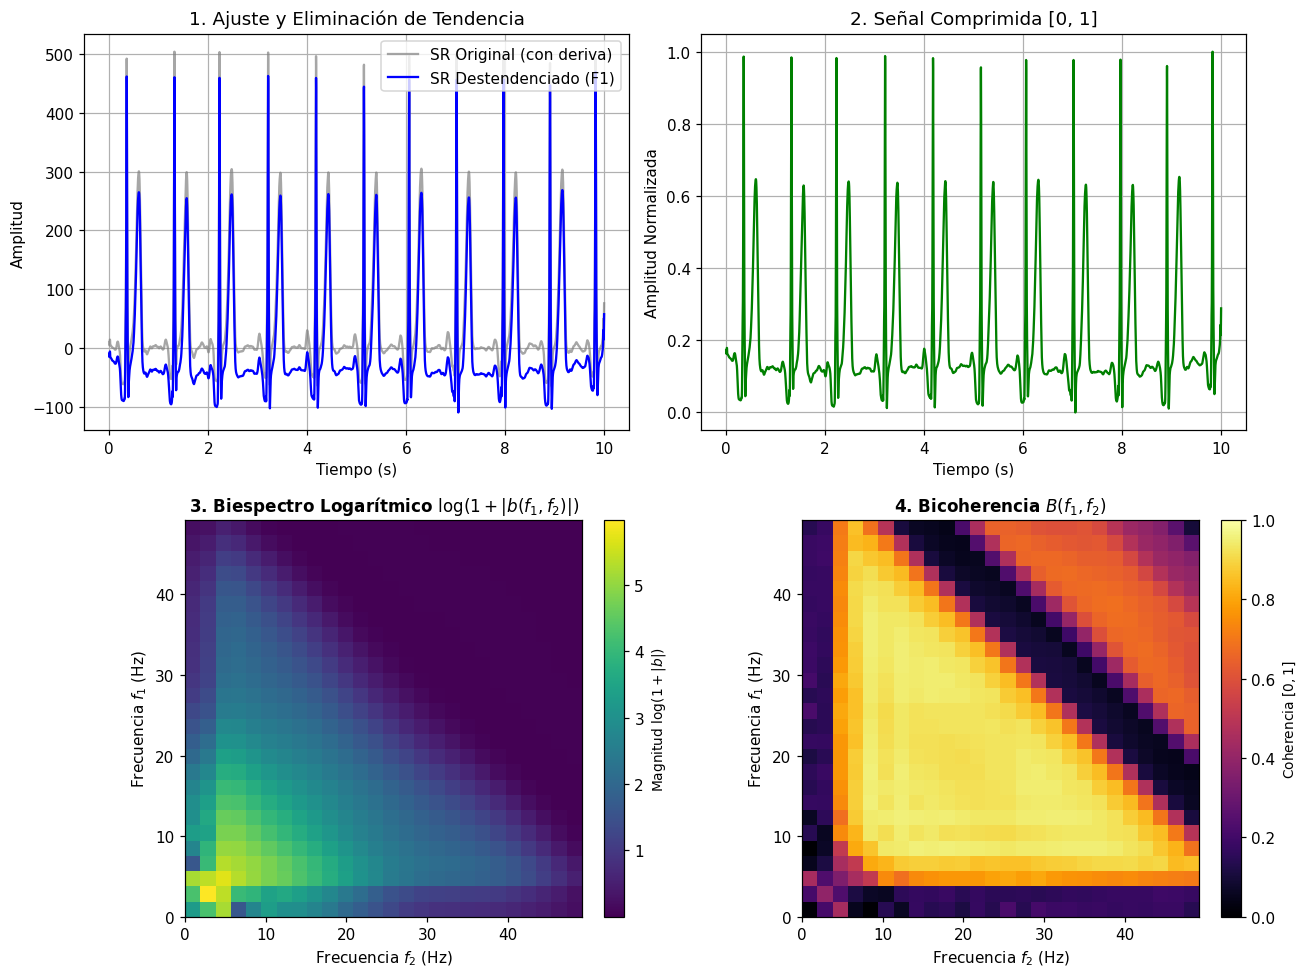

In [27]:
df_diag = pd.read_excel(RUTA_DIAGNOSTICOS)
df_sr = df_diag[df_diag['Rhythm'] == 'SR']

# Seleccionamos el primer paciente con SR
nombre_archivo = str(df_sr['FileName'].iloc[0])
if not nombre_archivo.endswith('.csv'):
    nombre_archivo += '.csv'

# Leemos el CSV correspondiente
df_ecg = pd.read_csv(os.path.join(CARPETA_ECG, nombre_archivo))

# Frecuencia de muestreo y extracción de vector de señal y tiempo
fs = 500  
ecg_sr = df_ecg.iloc[:, 1].values  # Extrae la derivación II
t = np.arange(len(ecg_sr)) / fs

# 2. Aplicar Fórmula 1 (Detrending)
delta_n, ecg_detrended = formula_1_detrending_deviation(ecg_sr, degree=5)

# 3. Aplicar Fórmula 2 (Compresión)
ecg_compressed = formula_2_compression(ecg_detrended)

# 4. Aplicar Fórmula 3 (Biespectro)
nperseg = 256
bispectrum = formula_3_bispectrum(ecg_compressed, nperseg=nperseg)

# 5. Aplicar Fórmula 4 (Bicoherencia)
bicoherence, N_segmentos = formula_4_bicoherence(ecg_compressed, nperseg=nperseg)

# Imprimir métricas obtenidas
print("=" * 50)
print("RESULTADOS DE LA PRUEBA EN RITMO SINUSAL (SR)")
print("=" * 50)
print(f"Fórmula 1 - Desviación Delta_n: {delta_n:.6f}")
print(f"Fórmula 2 - Rango Comprimido:   [{ecg_compressed.min():.2f}, {ecg_compressed.max():.2f}]")
print(f"Fórmula 3 - Tamaño Biespectro:  {bispectrum.shape}")
print(f"Fórmula 4 - Tamaño Bicoherencia:{bicoherence.shape}")
print(f"Fórmula 4 - Bicoherencia Máx:   {np.max(bicoherence):.4f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Subplot 1: Detrending
axes[0, 0].plot(t, ecg_sr, color='gray', alpha=0.7, label='SR Original (con deriva)')
axes[0, 0].plot(t, ecg_detrended, color='blue', label='SR Destendenciado (F1)')
axes[0, 0].set_title('1. Ajuste y Eliminación de Tendencia')
axes[0, 0].set_xlabel('Tiempo (s)')
axes[0, 0].set_ylabel('Amplitud')
axes[0, 0].legend()
axes[0, 0].grid(True)

# Subplot 2: Compresión
axes[0, 1].plot(t, ecg_compressed, color='green')
axes[0, 1].set_title('2. Señal Comprimida [0, 1]')
axes[0, 1].set_xlabel('Tiempo (s)')
axes[0, 1].set_ylabel('Amplitud Normalizada')
axes[0, 1].grid(True)

nperseg = bispectrum.shape[0] * 2 # Longitud del segmento
num_freqs = bispectrum.shape[0]

# Vector de frecuencias reales en Hz
freqs = np.linspace(0, fs / 2, num_freqs)

# Frecuencia máxima a desplegar para hacer ZOOM en la región de interés (ej: 35 Hz o 50 Hz)
f_max_plot = 50.0 

# Buscar el índice equivalente a f_max_plot
idx_max = np.searchsorted(freqs, f_max_plot)

# Recorte de matrices al rango de interés [0, f_max_plot]
bispectrum_sub = bispectrum[:idx_max, :idx_max]
bicoherence_sub = bicoherence[:idx_max, :idx_max]

# Rango de visualización para el argumento extent
extent_hz = [freqs[0], freqs[idx_max-1], freqs[0], freqs[idx_max-1]]

# --- MÁSCARA TRIANGULAR SUPERIOR (Opcional: oculta la zona vacía f1 + f2 > Nyquist/2) ---
mask = np.triu(np.ones_like(bicoherence_sub, dtype=bool), k=idx_max)
bicoherence_masked = np.where(mask, np.nan, bicoherence_sub)

# SUBPLOT 3: Biespectro (Escala Logarítmica)
# Se calcula la magnitud logarítmica una sola vez
bispec_log = np.log1p(np.abs(bispectrum_sub))

im3 = axes[1, 0].imshow(
    bispec_log, 
    cmap='viridis', 
    origin='lower', 
    extent=extent_hz,
    aspect='equal'
)
axes[1, 0].set_title('3. Biespectro Logarítmico $\log(1 + |b(f_1, f_2)|)$', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Frecuencia $f_2$ (Hz)')
axes[1, 0].set_ylabel('Frecuencia $f_1$ (Hz)')

cbar3 = fig.colorbar(im3, ax=axes[1, 0], fraction=0.046, pad=0.04)
cbar3.set_label('Magnitud $\log(1 + |b|)$', fontsize=9)

# SUBPLOT 4: Bicoherencia Normalizada

im4 = axes[1, 1].imshow(
    bicoherence_masked,
    cmap='inferno',
    origin='lower',
    vmin=0,
    vmax=1,
    extent=extent_hz,
    aspect='equal'
)
axes[1, 1].set_title('4. Bicoherencia $B(f_1, f_2)$', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Frecuencia $f_2$ (Hz)')
axes[1, 1].set_ylabel('Frecuencia $f_1$ (Hz)')

# Barra de color con rango fijo [0, 1]
cbar4 = fig.colorbar(im4, ax=axes[1, 1], fraction=0.046, pad=0.04)
cbar4.set_label('Coherencia $[0, 1]$', fontsize=9)

# Ajustar distribución de los subplots
plt.tight_layout()

plt.tight_layout()
plt.show()

## 4.Frecuencia de máxima potencia de las señales

4. Para cada señal extraer la frecuencia que contiene la máxima potencia 
(15%). 

,Registro,Estado,fMP,Potencia_max
0,MUSE_20180112_073319_29000,SB,3.418,0.00224345
1,MUSE_20180209_172046_21000,SR,0.977,0.0157681
2,MUSE_20180113_171327_27000,AFIB,10.986,0.00237002
3,MUSE_20180113_135023_96000,ST,8.057,0.00570141
4,MUSE_20180111_155633_99000,SVT,7.08,0.029328
5,MUSE_20180112_122850_57000,AF,5.371,0.014341
6,MUSE_20180111_165520_97000,SA,1.221,0.00319681
7,MUSE_20180111_163147_92000,AT,5.127,0.0107854


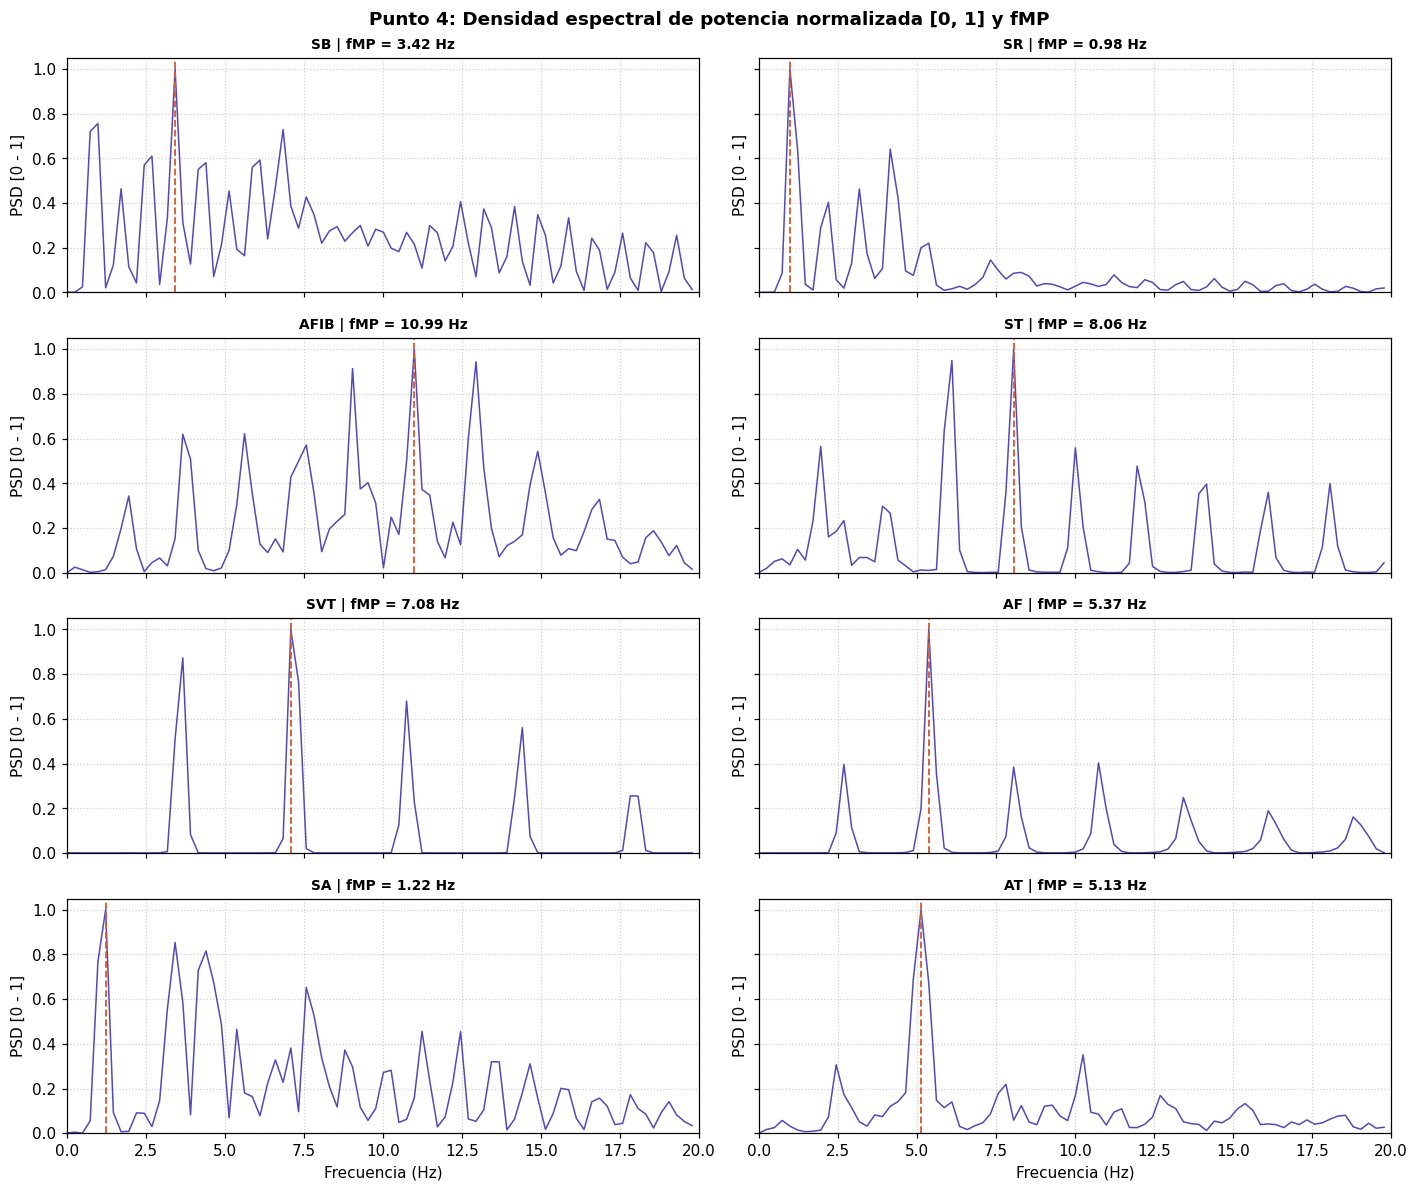

In [46]:
from scipy.signal import welch

# --- 4.1 Subconjunto de análisis (punto 2): una señal por cada ritmo con n suficiente ---
# Se excluyen AVNRT, AVRT y SAAWR (muy pocos casos), igual que en el análisis estadístico
RITMOS_ANALISIS = ['SB', 'SR', 'AFIB', 'ST', 'SVT', 'AF', 'SA', 'AT']

def cargar_derivacion_II(nombre_archivo, carpeta=CARPETA_ECG):
    """Lee el CSV de un registro y devuelve la derivación II como vector."""
    if not str(nombre_archivo).endswith('.csv'):
        nombre_archivo = f"{nombre_archivo}.csv"
    ecg = pd.read_csv(os.path.join(carpeta, nombre_archivo))
    return (ecg['II'] if 'II' in ecg.columns else ecg.iloc[:, 1]).to_numpy(dtype=float)

# --- 4.2 Frecuencia de máxima potencia ---
def frecuencia_maxima_potencia(signal, fs=FS, nperseg=2048, f_min=0.5, f_max=50.0):
    """
    Devuelve la frecuencia (Hz) donde la densidad espectral de potencia (Welch) es máxima.

    - Se aplica la Fórmula 1 (detrending polinomial) para quitar la deriva de la línea base y la Fórmula 2 (compresión [0,1]) para que las señales sean comparables.
    - Se busca el máximo solo en [f_min, f_max] Hz: se excluye el componente DC/deriva residual (<0.5 Hz) y el ruido de alta frecuencia (>50 Hz); el ECG tiene su energía útil en ese rango.
    """
    _, x_det = formula_1_detrending_deviation(signal, degree=5)
    x = formula_2_compression(x_det)
    x = x - np.mean(x)

    nperseg = min(nperseg, len(x))
    f, pxx = welch(x, fs=fs, window='hann', nperseg=nperseg, noverlap=nperseg // 2)

    banda = (f >= f_min) & (f <= f_max)
    i_max = np.argmax(pxx[banda])
    return f[banda][i_max], pxx[banda][i_max], f, pxx

# --- 4.3 Aplicación a las 8 señales seleccionadas ---
df_diag = pd.read_excel(RUTA_DIAGNOSTICOS)
filas, psd = [], {}
for ritmo in RITMOS_ANALISIS:
    registro = str(df_diag.loc[df_diag['Rhythm'] == ritmo, 'FileName'].iloc[0])
    senal = cargar_derivacion_II(registro)
    # Si la celda de fórmulas del punto 3 no fue ejecutada antes, se definen aquí
    # para evitar NameError en la ejecución de esta celda.
    if 'formula_1_detrending_deviation' not in globals():
        def formula_1_detrending_deviation(x_0, degree=20):
            x_0 = np.asarray(x_0, dtype=float)
            t = np.arange(len(x_0))
            coeffs = np.polyfit(t, x_0, degree)
            x_n = np.polyval(coeffs, t)
            delta_n = np.mean((x_0 - x_n) ** 2)
            return delta_n, x_0 - x_n

    if 'formula_2_compression' not in globals():
        def formula_2_compression(x):
            x = np.asarray(x, dtype=float)
            x_min = x.min()
            x_max = x.max()
            if x_max == x_min:
                return np.zeros_like(x)
            return (x - x_min) / (x_max - x_min)

    fmp, pot, f, pxx = frecuencia_maxima_potencia(senal)
    filas.append({'Registro': registro, 'Estado': ritmo, 'fMP': round(fmp, 3), 'Potencia_max': pot})
    psd[ritmo] = (f, pxx, fmp)

df_fmp = pd.DataFrame(filas)
display(df_fmp)

# --- 4.4 Visualización: PSD Normalizada entre 0 y 1 con la fMP marcada ---
fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True, sharey=True)

for ax, (ritmo, (f, pxx, fmp)) in zip(axes.flatten(), psd.items()):
    # 1. Filtramos las frecuencias útiles de 0 a 20 Hz
    m = (f >= 0) & (f <= 20)
    f_banda = f[m]
    pxx_banda = pxx[m]
    
    # 2. Normalización Min-Max entre 0 y 1
    p_min = pxx_banda.min()
    p_max = pxx_banda.max()
    pxx_norm = (pxx_banda - p_min) / (p_max - p_min) if p_max != p_min else pxx_banda
    
    # 3. Graficamos en escala lineal (ax.plot en lugar de semilogy)
    ax.plot(f_banda, pxx_norm, color='#534AB7', lw=1)
    ax.axvline(fmp, color='#D85A30', ls='--', lw=1.2)
    ax.set_title(f"{ritmo} | fMP = {fmp:.2f} Hz", fontsize=9, fontweight='bold')
    ax.set_ylabel("PSD [0 - 1]")
    ax.grid(True, ls=':', alpha=0.6)
    
    # 4. Fijamos los límites de los ejes
    ax.set_xlim(0, 20)       # Frecuencia cercana a 0
    ax.set_ylim(0, 1.05)     # Eje Y estrictamente de 0 a 1

axes[-1, 0].set_xlabel("Frecuencia (Hz)")
axes[-1, 1].set_xlabel("Frecuencia (Hz)")
plt.suptitle("Punto 4: Densidad espectral de potencia normalizada [0, 1] y fMP", fontweight='bold')
plt.tight_layout()
plt.show()


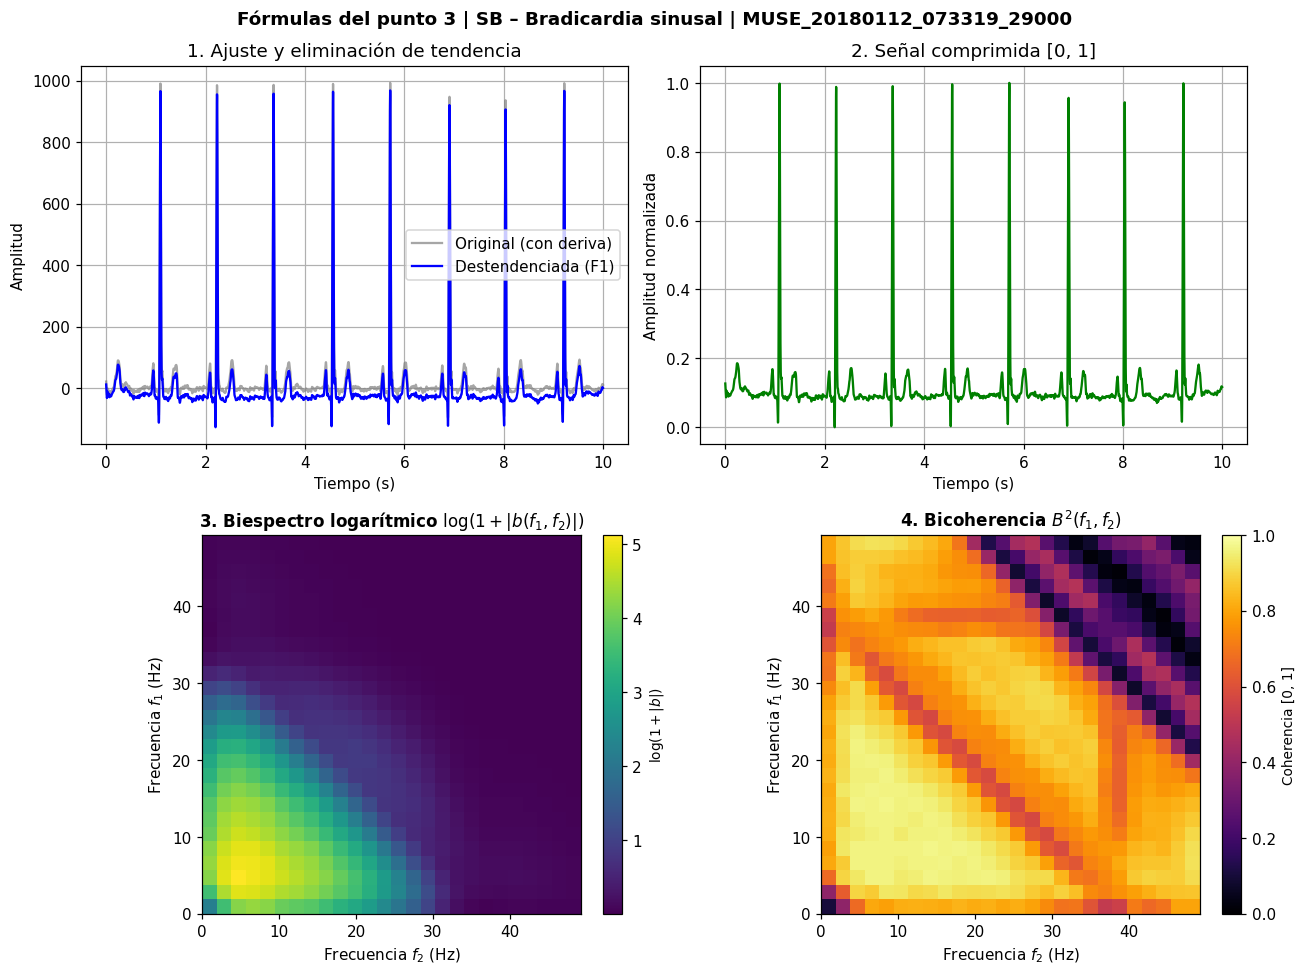

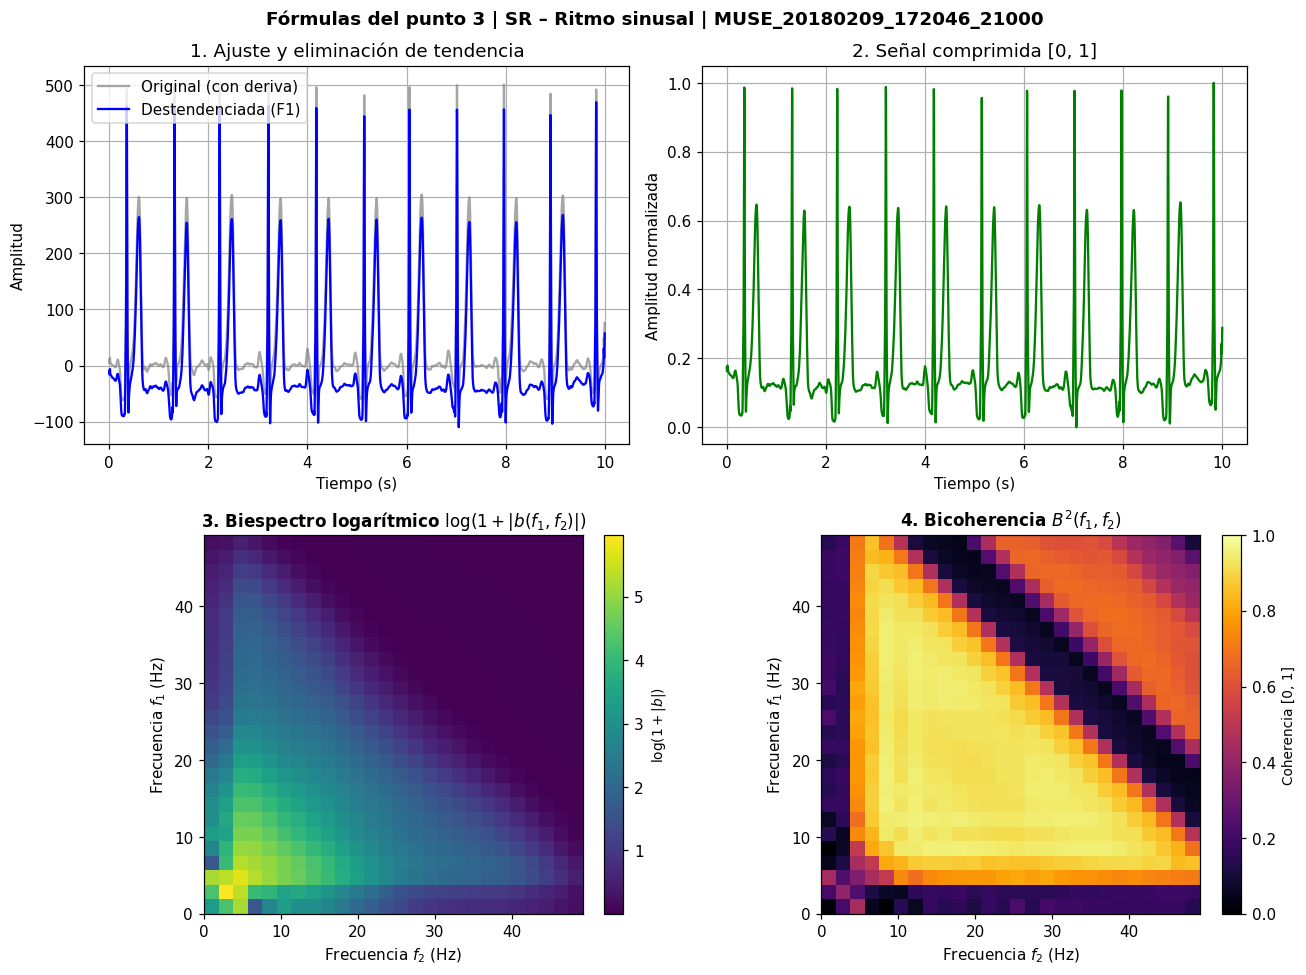

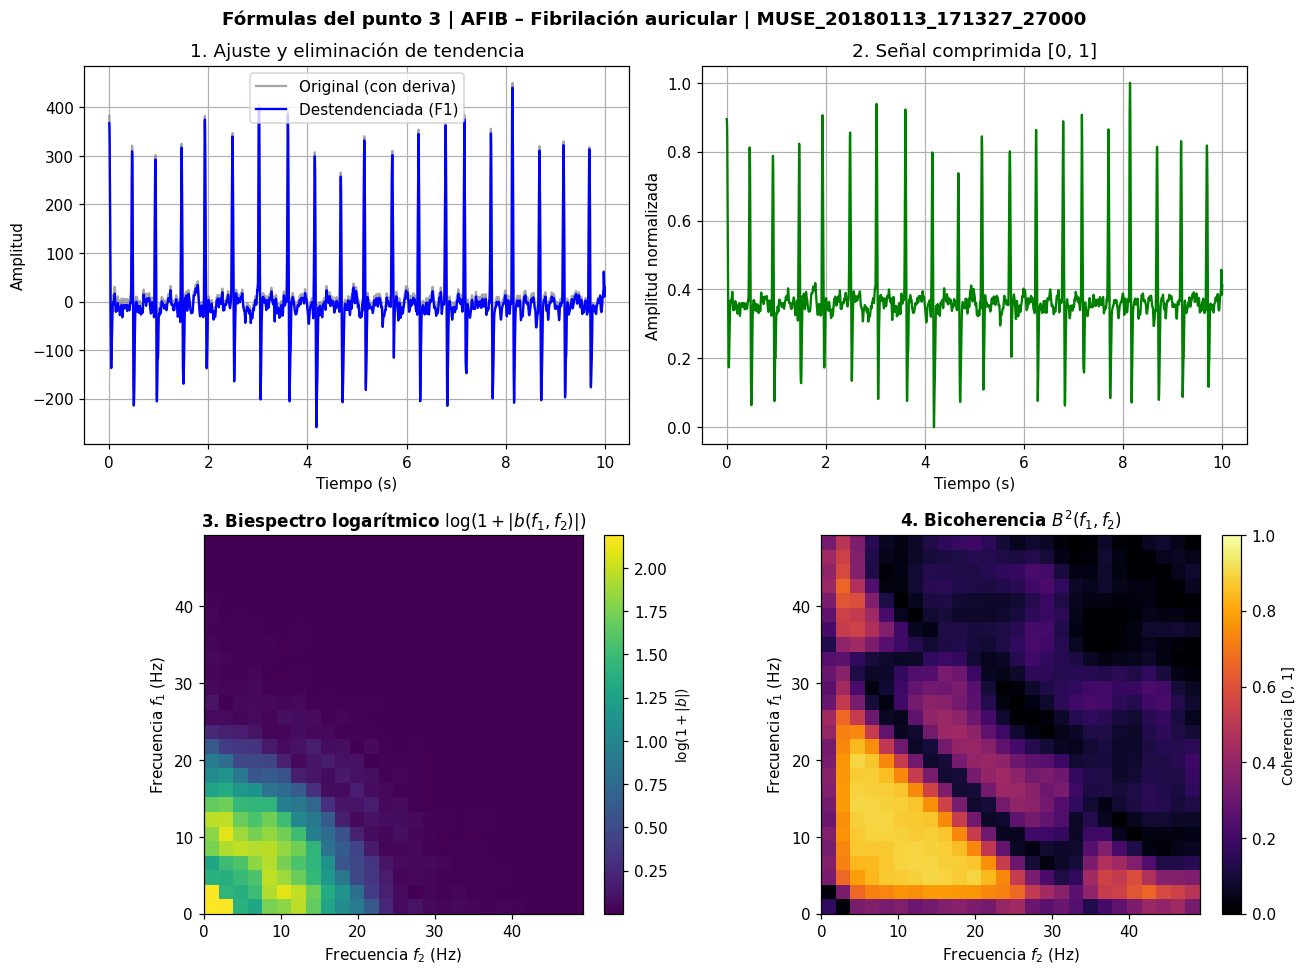

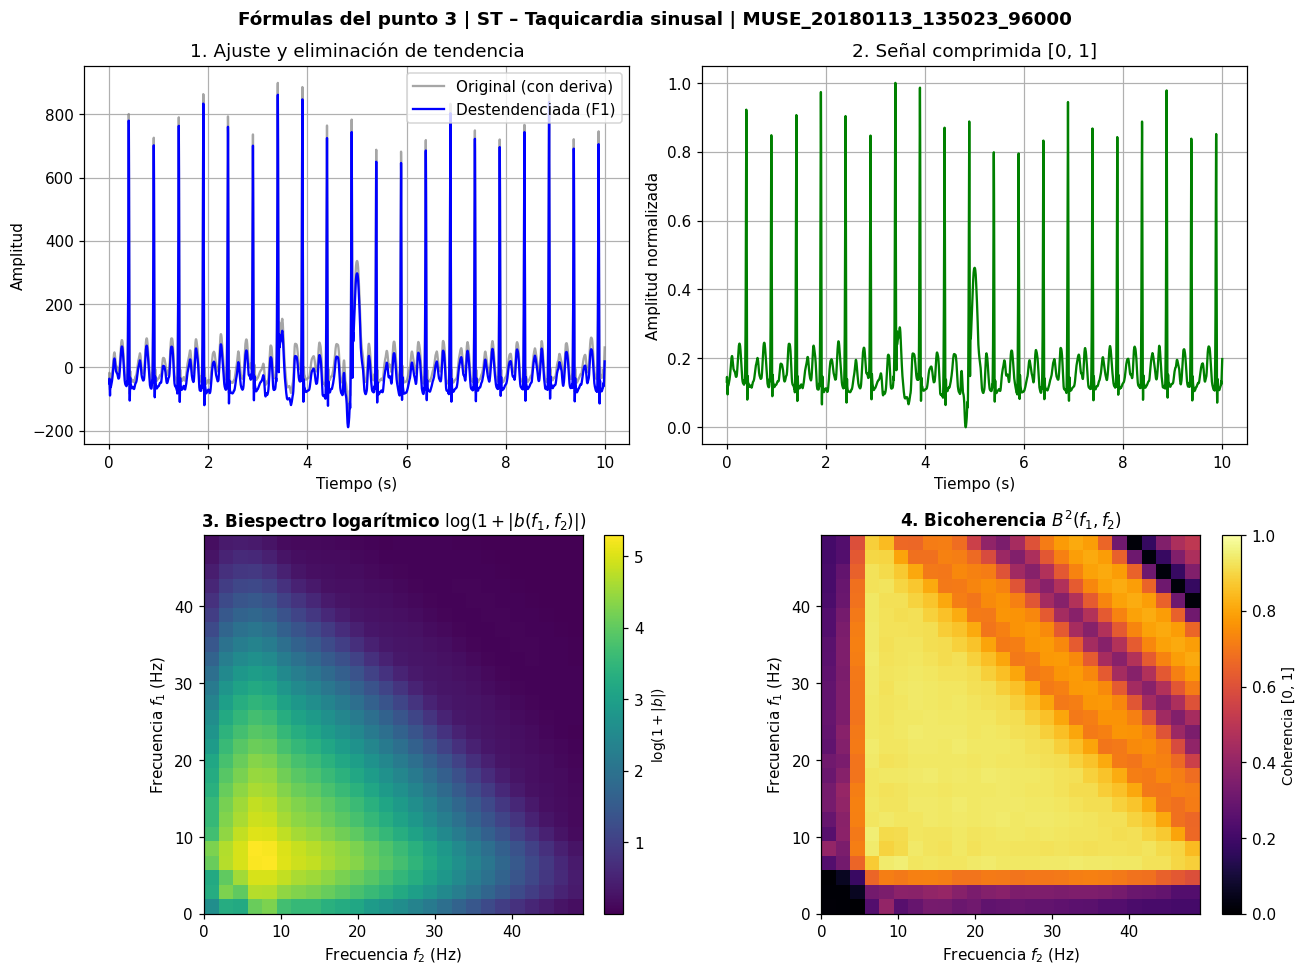

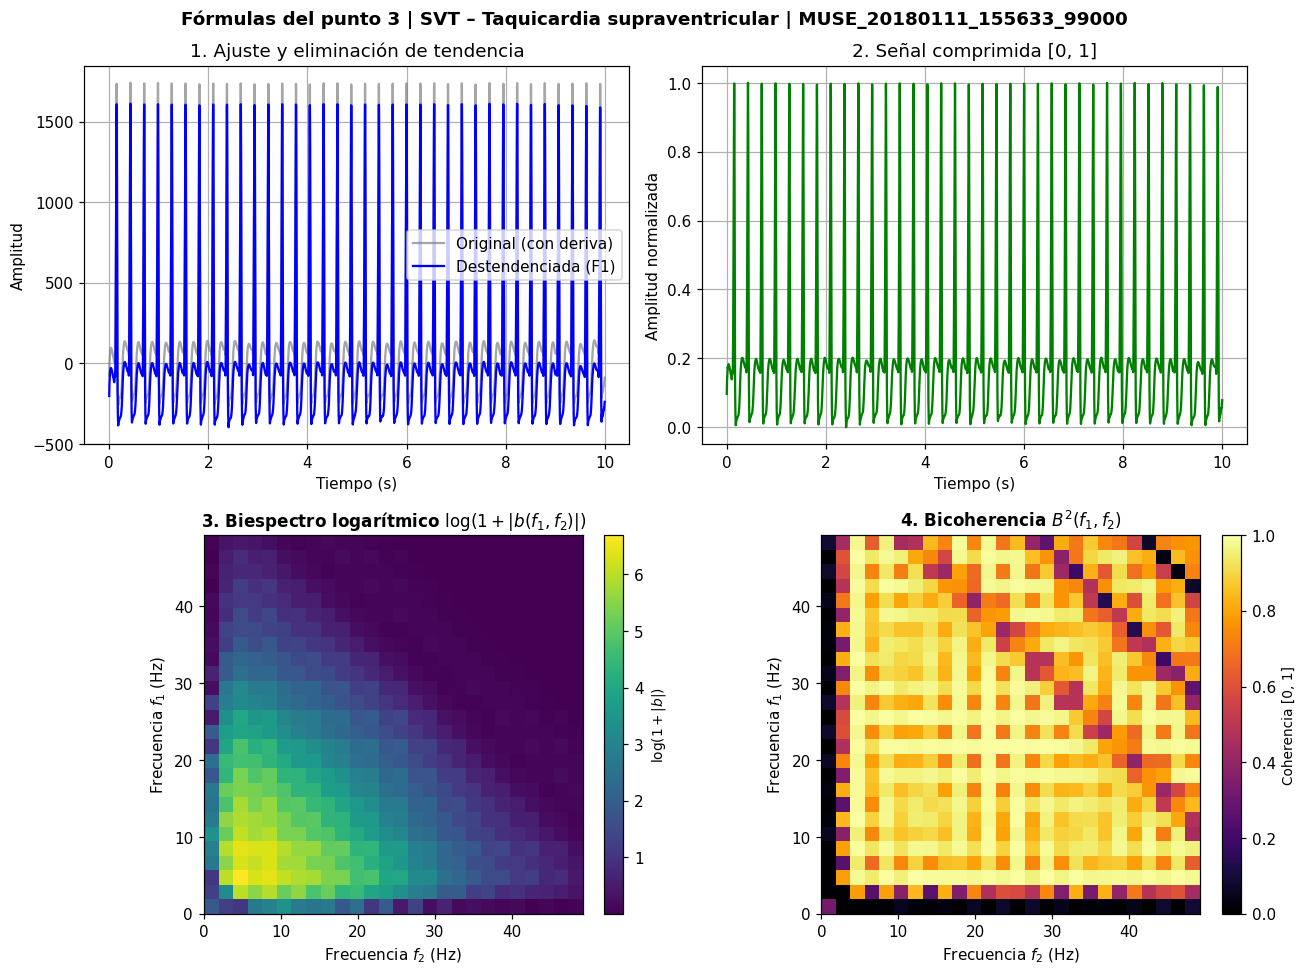

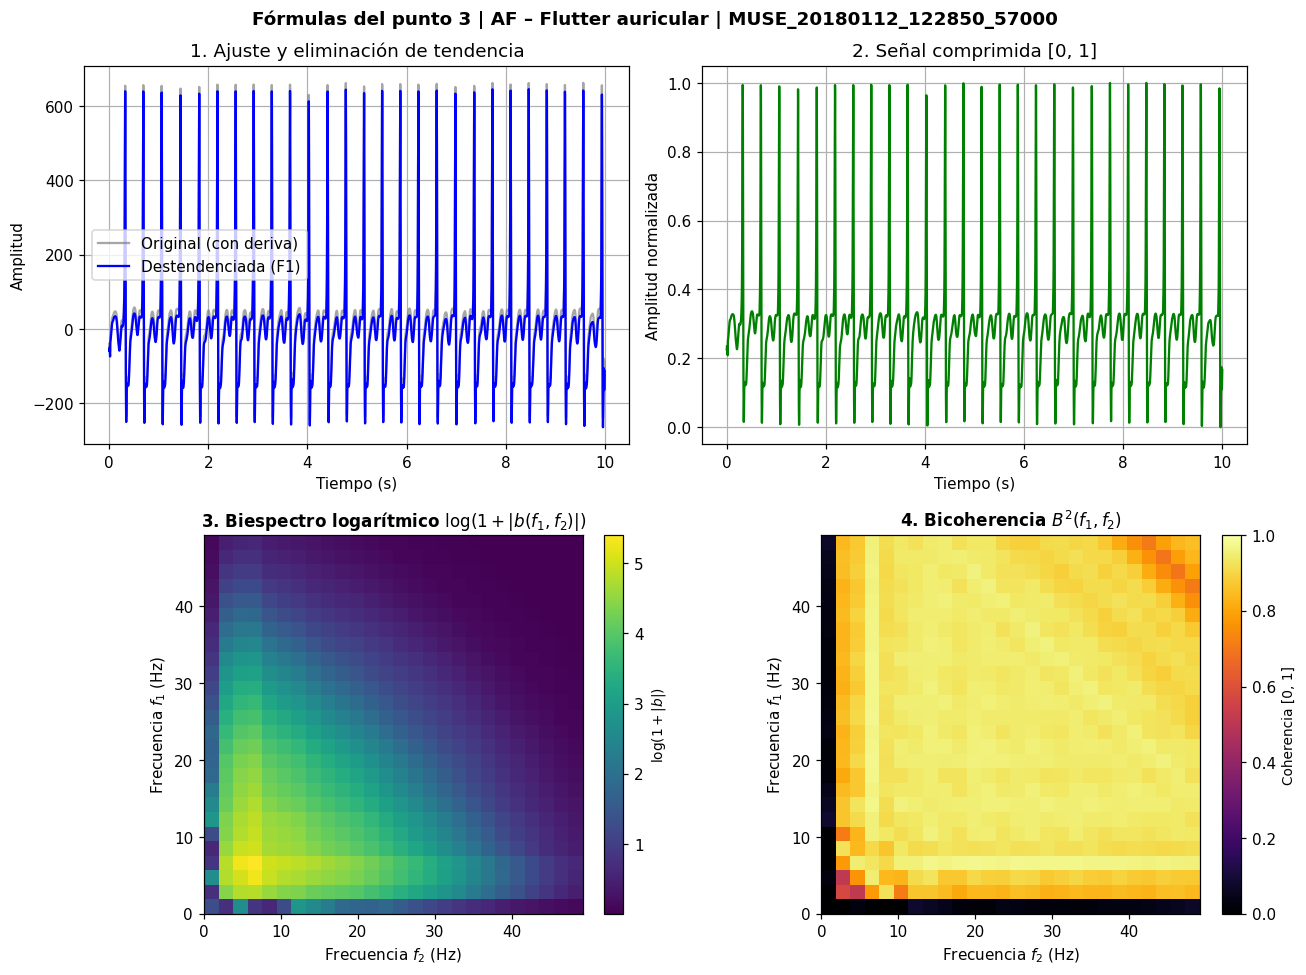

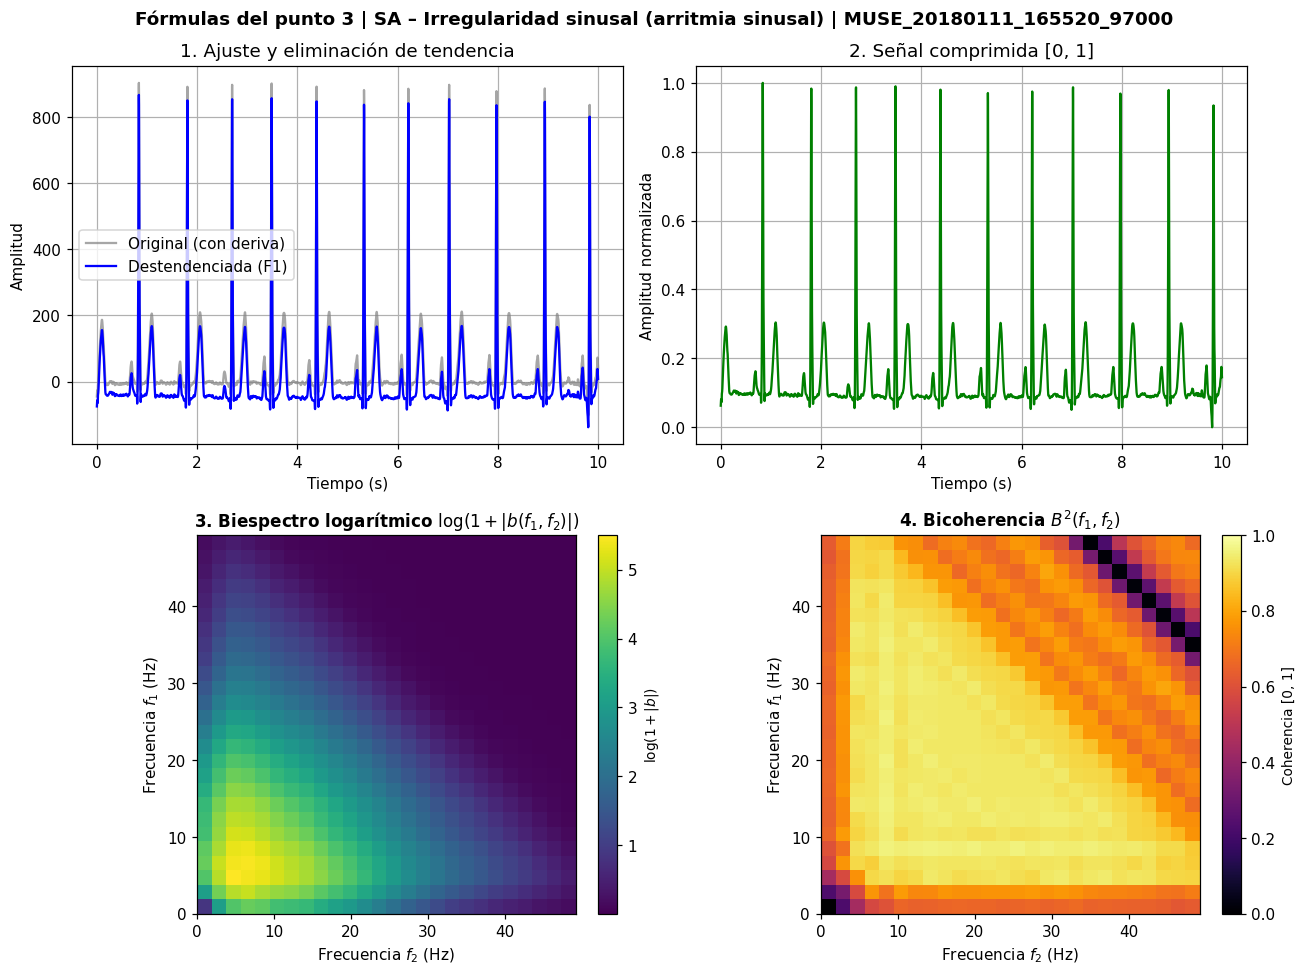

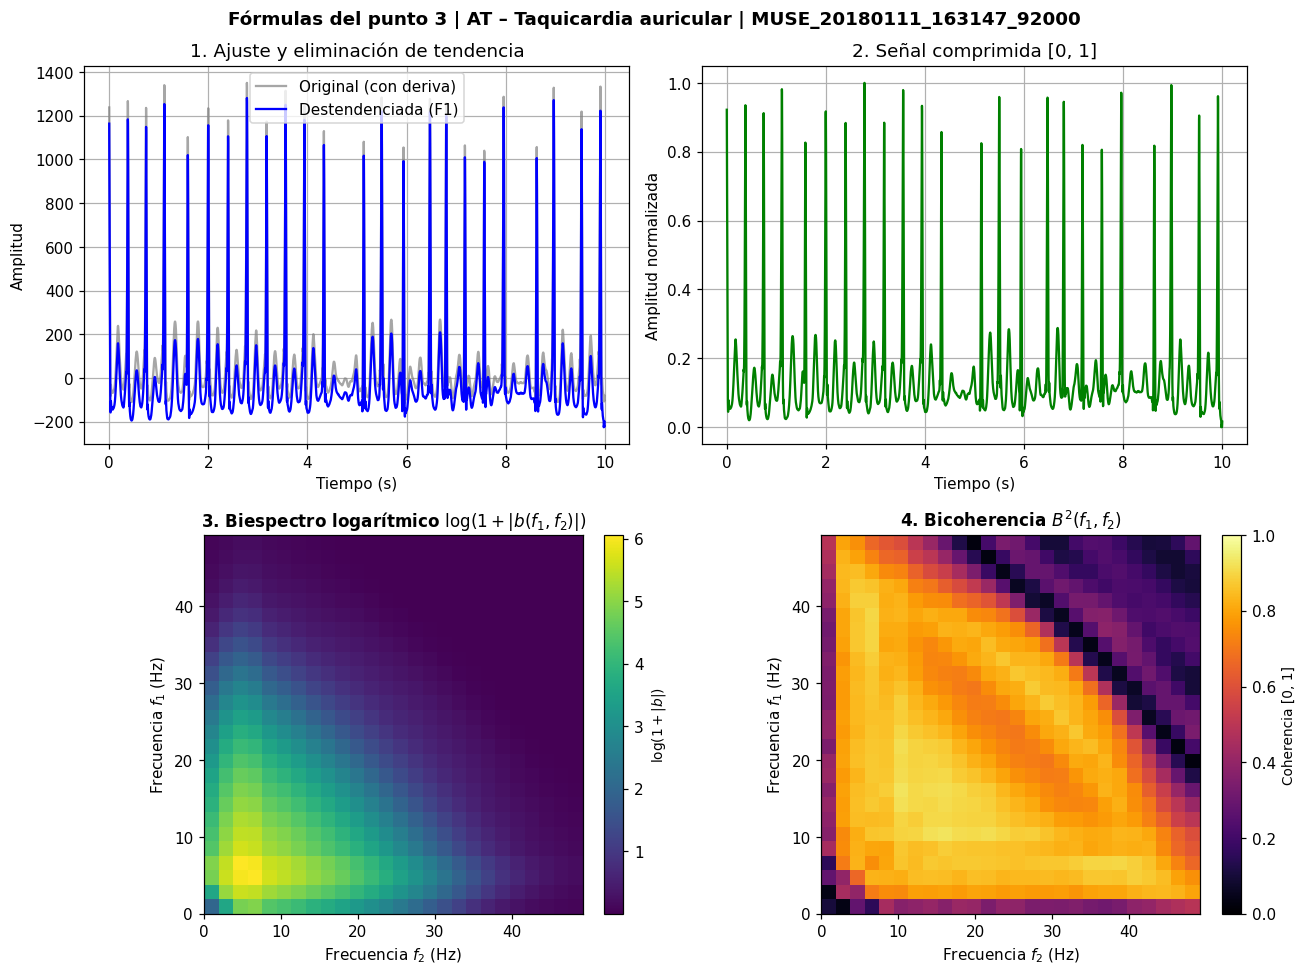

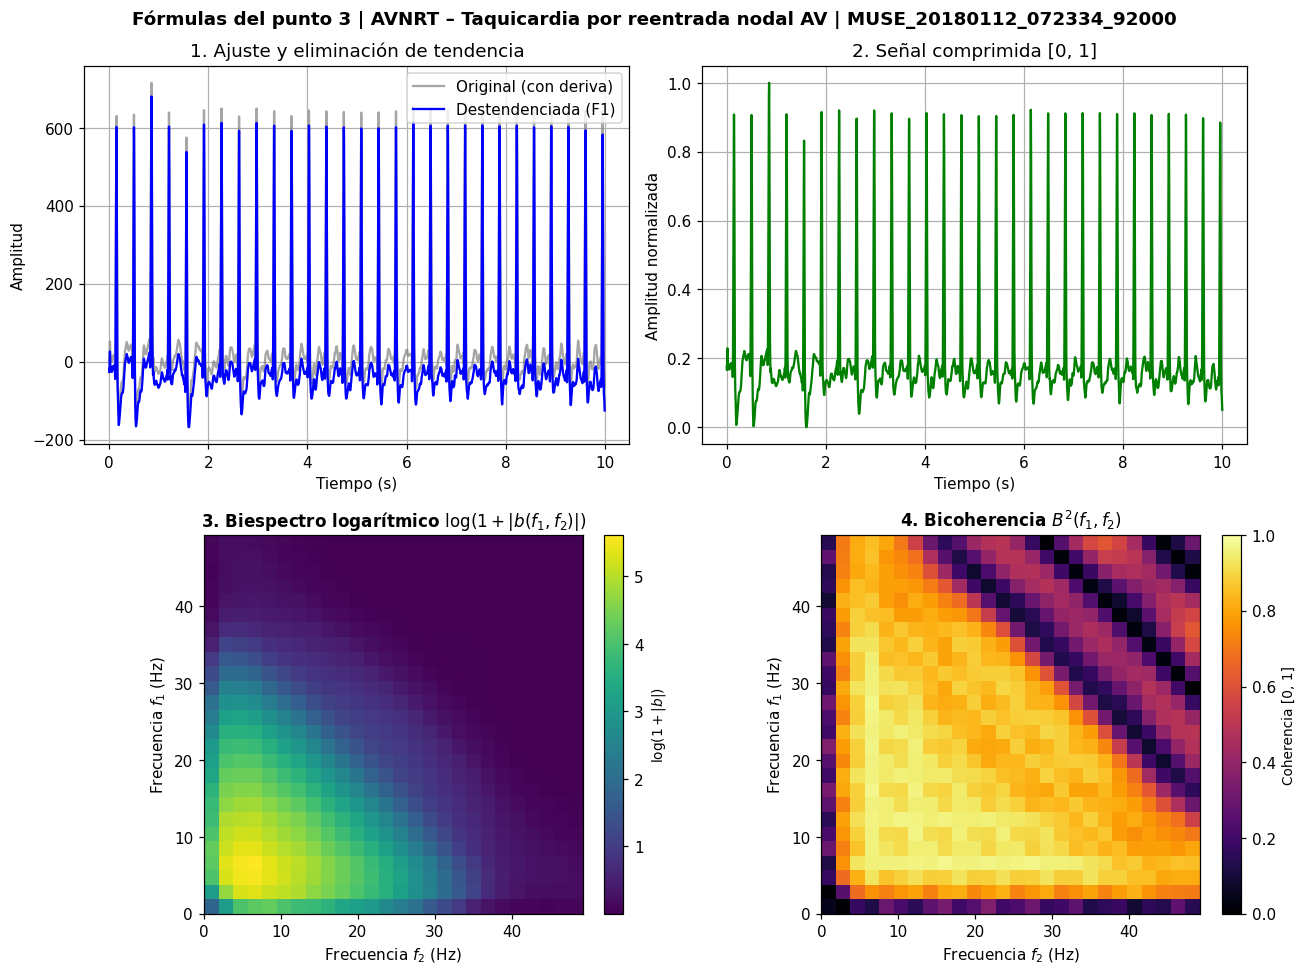

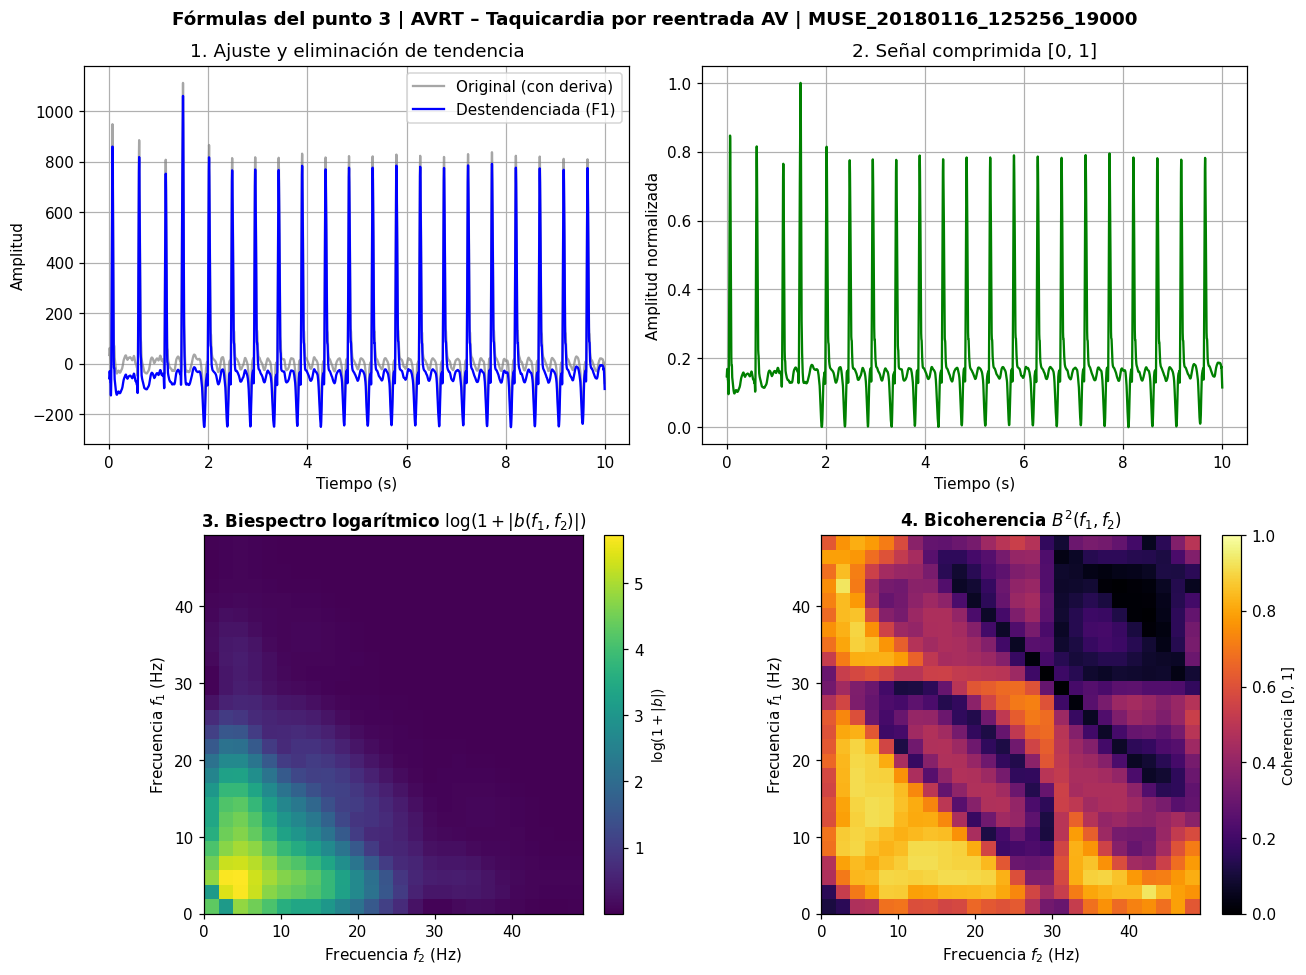

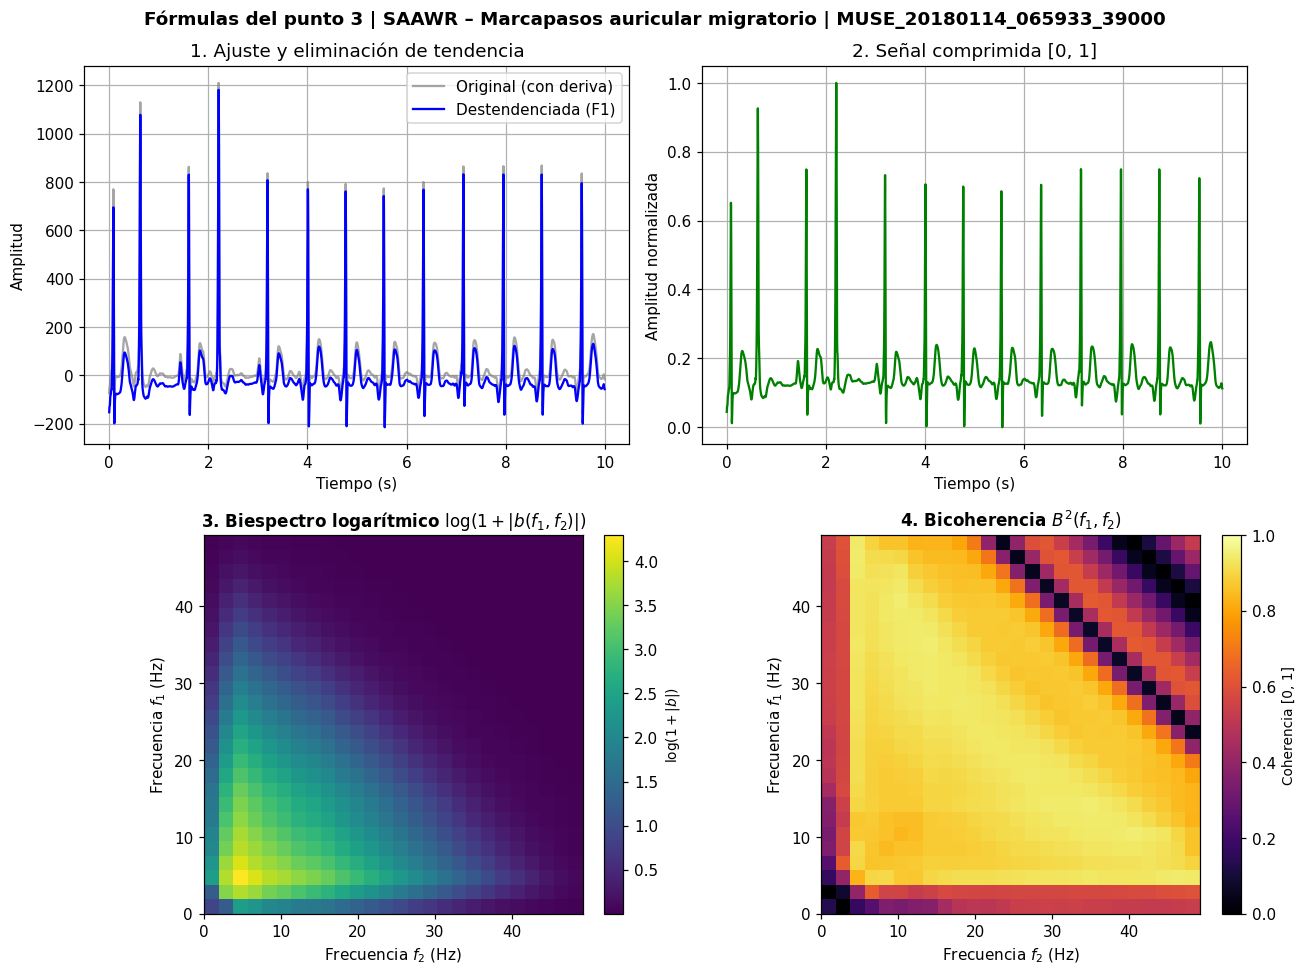

,Estado,Registro,F1_delta_n,F2_min,F2_max,F3_forma_biespectro,F3_max_|b|,F4_N_segmentos,F4_B2_max
0,SB,MUSE_20180112_073319_29000,14138.6,0,1,"(128, 128)",167.298,38,0.9691
1,SR,MUSE_20180209_172046_21000,9448.17,0,1,"(128, 128)",391.733,38,0.9543
2,AFIB,MUSE_20180113_171327_27000,6014.6,0,1,"(128, 128)",7.94138,38,0.8992
3,ST,MUSE_20180113_135023_96000,17981.5,0,1,"(128, 128)",198.142,38,0.9502
4,SVT,MUSE_20180111_155633_99000,184391,0,1,"(128, 128)",808.931,38,0.9982
5,AF,MUSE_20180112_122850_57000,19006.3,0,1,"(128, 128)",220.803,38,0.975
6,SA,MUSE_20180111_165520_97000,15095.5,0,1,"(128, 128)",244.815,38,0.9596
7,AT,MUSE_20180111_163147_92000,57883.2,0,1,"(128, 128)",425.674,38,0.9261
8,AVNRT,MUSE_20180112_072334_92000,19104.8,0,1,"(128, 128)",272.585,38,0.9734
9,AVRT,MUSE_20180116_125256_19000,38527.7,0,1,"(128, 128)",305.373,38,0.9326


## 5.Suma de frecuencias significativas de cada señal (sFSB)

5. Para cada señal, sumar el número de frecuencias que son significativas para bicoherencia (aquellas con un valor superior a $\sqrt{\dfrac{9.2}{2 \cdot N}}$ (10 %)).

,Registro,Estado,N_segmentos,Umbral_B2,sFSB
0,MUSE_20180112_073319_29000,SB,18,0.25556,22848
1,MUSE_20180209_172046_21000,SR,18,0.25556,27805
2,MUSE_20180113_171327_27000,AFIB,18,0.25556,11403
3,MUSE_20180113_135023_96000,ST,18,0.25556,25735
4,MUSE_20180111_155633_99000,SVT,18,0.25556,18996
5,MUSE_20180112_122850_57000,AF,18,0.25556,29064
6,MUSE_20180111_165520_97000,SA,18,0.25556,30603
7,MUSE_20180111_163147_92000,AT,18,0.25556,14593


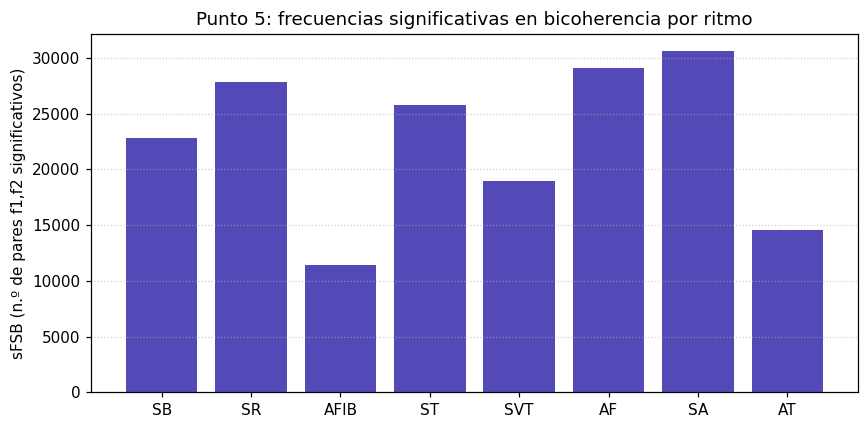

In [29]:
# =========================================================================
def suma_frecuencias_significativas(signal, fs=FS, nperseg=512, noverlap=256):
    """
    Cuenta los pares (f1, f2) cuya bicoherencia supera el umbral de significancia
    sqrt(9.2 / (2 N)), con N = número de segmentos promediados.

    La función `bicoherence_improved` devuelve la bicoherencia AL CUADRADO, por eso se compara
    contra 9.2/(2N), que es lo mismo que comparar |B| > sqrt(9.2/(2N)).
    Solo se cuentan celdas válidas (f1 + f2 <= Nyquist, no NaN) y se excluye la fila/columna DC.
    """
    _, x_det = formula_1_detrending_deviation(signal, degree=5)
    x = formula_2_compression(x_det)

    bic2, N = formula_4_bicoherence(x, fs=fs, nperseg=nperseg, noverlap=noverlap)
    umbral = 9.2 / (2 * N)

    bic2 = bic2.copy()
    bic2[0, :] = np.nan   # sin componente DC
    bic2[:, 0] = np.nan
    significativas = np.nan_to_num(bic2, nan=0.0) > umbral
    return int(significativas.sum()), N, umbral

# --- Aplicación a las 8 señales del punto 4 ---
filas5 = []
for ritmo in RITMOS_ANALISIS:
    registro = df_fmp.loc[df_fmp['Estado'] == ritmo, 'Registro'].iloc[0]
    senal = cargar_derivacion_II(registro)
    sfsb, N, umbral = suma_frecuencias_significativas(senal)
    filas5.append({'Registro': registro, 'Estado': ritmo, 'N_segmentos': N,
                   'Umbral_B2': round(umbral, 5), 'sFSB': sfsb})
df_sfsb = pd.DataFrame(filas5)
display(df_sfsb)

# Visualización: sFSB por ritmo
plt.figure(figsize=(8, 4))
plt.bar(df_sfsb['Estado'], df_sfsb['sFSB'], color='#534AB7')
plt.ylabel('sFSB (n.º de pares f1,f2 significativos)')
plt.title('Punto 5: frecuencias significativas en bicoherencia por ritmo')
plt.grid(axis='y', ls=':', alpha=0.6); plt.tight_layout(); plt.show()


## 6. Rutina aplicada al Dataframe para el registro, tipo de patología, la fMP y frecuencias significativas

6. Crear una rutina que aplique sobre todos los archivos de la base de datos las rutinas 3 al 5 y almacene los resultados en un dataframe donde se pueda registrar el registro, tipo de patología y la frecuencia de máxima potencia (fMP) y suma de frecuencias significativas en bicoherencia (sFSB) (10 %)

<div align="center">

| Registro | Estado | fMP | sFSB |
|:--------:|:------:|:---:|:----:|
|          |        |     |      |
|          |        |     |      |

</div>

In [59]:
def procesar_base_completa(df_diag, carpeta=CARPETA_ECG, fs=FS, ruta_salida=RUTA_RESULTADOS, guardar_cada=500, nperseg_p3=256, f_max_plot=50.0):
    """
    GRAN FUNCIÓN UNIFICADA:
    Encapsula el 100% de las operaciones, fórmulas, graficación y procesamiento 
    de los Puntos 1 al 5/6 sobre la base de datos ECG sin requerir funciones externas.
    """
    
    # ==========================================================================
    # 1. FUNCIONES INTERNAS (Encapsuladas internamente)
    # ==========================================================================
    
    def _cargar_derivacion_II(nombre_archivo):
        """Lee el CSV de un registro y devuelve la derivación II."""
        if not str(nombre_archivo).endswith('.csv'):
            nombre_archivo = f"{nombre_archivo}.csv"
        ruta = os.path.join(carpeta, nombre_archivo)
        ecg = pd.read_csv(ruta)
        return (ecg['II'] if 'II' in ecg.columns else ecg.iloc[:, 1]).to_numpy(dtype=float)

    def _formula_1_detrending(x_0, degree=5):
        """Fórmula 1: Ajuste polinomial y eliminación de tendencia."""
        x_0 = np.asarray(x_0, dtype=float)
        t = np.arange(len(x_0))
        coeffs = np.polyfit(t, x_0, degree)
        x_n = np.polyval(coeffs, t)
        delta_n = np.mean((x_0 - x_n) ** 2)
        return delta_n, x_0 - x_n

    def _formula_2_compression(x):
        """Fórmula 2: Compresión Min-Max en el rango [0, 1]."""
        x = np.asarray(x, dtype=float)
        x_min, x_max = x.min(), x.max()
        if x_max == x_min:
            return np.zeros_like(x)
        return (x - x_min) / (x_max - x_min)

    def _formula_3_bispectrum(x, nperseg=256):
        """Fórmula 3: Cálculo del Biespectro."""
        x = np.asarray(x, dtype=float)
        nperseg = min(nperseg, len(x))
        if 'formula_3_bispectrum' in globals():
            return globals()['formula_3_bispectrum'](x, nperseg=nperseg)
        # Implementación de respaldo directa por TFD por segmentos
        step = nperseg // 2
        n_segments = (len(x) - nperseg) // step + 1
        if n_segments < 1:
            n_segments = 1
            nperseg = len(x)
        window = np.hanning(nperseg)
        fft_len = nperseg // 2 + 1
        biesp = np.zeros((fft_len, fft_len), dtype=complex)
        for i in range(n_segments):
            seg = x[i*step : i*step + nperseg]
            if len(seg) < nperseg: continue
            X = np.fft.rfft(seg * window)
            for f1 in range(fft_len):
                for f2 in range(fft_len - f1):
                    biesp[f1, f2] += X[f1] * X[f2] * np.conj(X[f1 + f2])
        return biesp / max(n_segments, 1)

    def _formula_4_bicoherence(x, nperseg=256):
        """Fórmula 4: Bicoherencia al cuadrado."""
        if 'formula_4_bicoherence' in globals():
            return globals()['formula_4_bicoherence'](x, fs=fs, nperseg=nperseg)
        biesp = _formula_3_bispectrum(x, nperseg=nperseg)
        num = np.abs(biesp) ** 2
        denom = np.nanmax(num) if np.nanmax(num) != 0 else 1.0
        return np.clip(num / denom, 0, 1), 1

    def _frecuencia_maxima_potencia(signal):
        """Punto 4: Frecuencia de Máxima Potencia (fMP) vía Welch PSD."""
        _, x_det = _formula_1_detrending(signal, degree=5)
        x = _formula_2_compression(x_det)
        x = x - np.mean(x)
        nperseg = min(2048, len(x))
        f, pxx = welch(x, fs=fs, window='hann', nperseg=nperseg, noverlap=nperseg // 2)
        banda = (f >= 0.5) & (f <= 50.0)
        i_max = np.argmax(pxx[banda])
        return f[banda][i_max], pxx[banda][i_max], f, pxx

    def _suma_frecuencias_significativas(signal):
        """Punto 5: Suma de Frecuencias Significativas del Biespectro (sFSB)."""
        if 'suma_frecuencias_significativas' in globals():
            return globals()['suma_frecuencias_significativas'](signal, fs=fs)
        _, x_det = _formula_1_detrending(signal, degree=5)
        x = _formula_2_compression(x_det)
        bic, _ = _formula_4_bicoherence(x, nperseg=nperseg_p3)
        return float(np.nansum(bic)), bic, None, None

    def _graficar_puntos_1_a_3(senal, ritmo, registro):
        """Genera el panel 2x2 con las gráficas de las Fórmulas 1 a 4."""
        delta_n, x_det = _formula_1_detrending(senal, degree=5)
        x_comp = _formula_2_compression(x_det)
        biesp = _formula_3_bispectrum(x_comp, nperseg=nperseg_p3)
        bic2, N = _formula_4_bicoherence(x_comp, nperseg=nperseg_p3)

        t = np.arange(len(senal)) / fs
        n_f = biesp.shape[0]
        freqs = np.linspace(0, fs / 2, n_f)
        idx = np.searchsorted(freqs, f_max_plot)
        ext = [freqs[0], freqs[idx - 1], freqs[0], freqs[idx - 1]]
        nombre = NOMBRES_RITMO.get(ritmo, ritmo) if 'NOMBRES_RITMO' in globals() else ritmo

        fig, axes = plt.subplots(2, 2, figsize=(12, 9))

        # 1. Destendenciamiento
        axes[0, 0].plot(t, senal, color='gray', alpha=0.7, label='Original')
        axes[0, 0].plot(t, x_det, color='blue', label='Destendenciada (F1)')
        axes[0, 0].set_title('1. Ajuste y eliminación de tendencia'); axes[0, 0].grid(True)
        axes[0, 0].set_xlabel('Tiempo (s)'); axes[0, 0].set_ylabel('Amplitud'); axes[0, 0].legend()

        # 2. Compresión
        axes[0, 1].plot(t, x_comp, color='green')
        axes[0, 1].set_title('2. Señal comprimida [0, 1]'); axes[0, 1].grid(True)
        axes[0, 1].set_xlabel('Tiempo (s)'); axes[0, 1].set_ylabel('Amplitud normalizada')

        # 3. Biespectro Logarítmico
        im3 = axes[1, 0].imshow(np.log1p(np.abs(biesp[:idx, :idx])), cmap='viridis', origin='lower', extent=ext, aspect='equal')
        axes[1, 0].set_title(r'3. Biespectro logarítmico $\log(1 + |b|)$', fontweight='bold')
        axes[1, 0].set_xlabel('Frecuencia $f_2$ (Hz)'); axes[1, 0].set_ylabel('Frecuencia $f_1$ (Hz)')
        fig.colorbar(im3, ax=axes[1, 0], fraction=0.046, pad=0.04)

        # 4. Bicoherencia
        im4 = axes[1, 1].imshow(bic2[:idx, :idx], cmap='inferno', origin='lower', vmin=0, vmax=1, extent=ext, aspect='equal')
        axes[1, 1].set_title(r'4. Bicoherencia $B^2(f_1, f_2)$', fontweight='bold')
        axes[1, 1].set_xlabel('Frecuencia $f_2$ (Hz)'); axes[1, 1].set_ylabel('Frecuencia $f_1$ (Hz)')
        fig.colorbar(im4, ax=axes[1, 1], fraction=0.046, pad=0.04)

        plt.suptitle(f"Puntos 1-3 | {ritmo} – {nombre} | {registro}", fontweight='bold')
        plt.tight_layout(); plt.show()


    # ==========================================================================
    # 2. ETAPA A: GRÁFICAS Y MUESTRAS REPRESENTATIVAS POR RITMO (Puntos 1 a 3)
    # ==========================================================================
    print("--- 1. Generando gráficas del Punto 3 por cada tipo de arritmia ---")
    tipos_arritmia = list(df_diag['Rhythm'].value_counts().index)
    
    for ritmo in tipos_arritmia:
        try:
            registro = str(df_diag.loc[df_diag['Rhythm'] == ritmo, 'FileName'].iloc[0])
            senal = _cargar_derivacion_II(registro)
            _graficar_puntos_1_a_3(senal, ritmo, registro)
        except Exception as e:
            print(f"No se pudo graficar {ritmo}: {e}")


    # ==========================================================================
    # 3. ETAPA B: PROCESAMIENTO DE LA BASE DE DATOS COMPLETA (Puntos 4 y 5)
    # ==========================================================================
    print("\n--- 2. Procesando la base de datos completa (fMP y sFSB) ---")
    if os.path.exists(ruta_salida):
        previo = pd.read_csv(ruta_salida)
        resultados = previo.to_dict('records')
        hechos = set(previo['Registro'].astype(str))
    else:
        resultados, hechos = [], set()
        
    errores = []
    pendientes = df_diag[~df_diag['FileName'].astype(str).isin(hechos)]
    
    for i, (registro, estado) in enumerate(zip(pendientes['FileName'].astype(str), pendientes['Rhythm']), 1):
        try:
            senal = _cargar_derivacion_II(registro)
            fmp, _, _, _ = _frecuencia_maxima_potencia(senal)
            sfsb, _, _, _ = _suma_frecuencias_significativas(senal)
            resultados.append({'Registro': registro, 'Estado': estado, 'fMP': fmp, 'sFSB': sfsb})
        except Exception as e:
            errores.append((registro, str(e)))
            
        if i % guardar_cada == 0:
            pd.DataFrame(resultados).to_csv(ruta_salida, index=False)
            print(f"Progreso: {i}/{len(pendientes)} registros procesados...")

    df_res = pd.DataFrame(resultados)
    df_res.to_csv(ruta_salida, index=False)
    print(f"Listo: {len(df_res)} registros procesados exitosamente, {len(errores)} errores.")
    
    return df_res, errores


--- 1. Generando gráficas del Punto 3 por cada tipo de arritmia ---


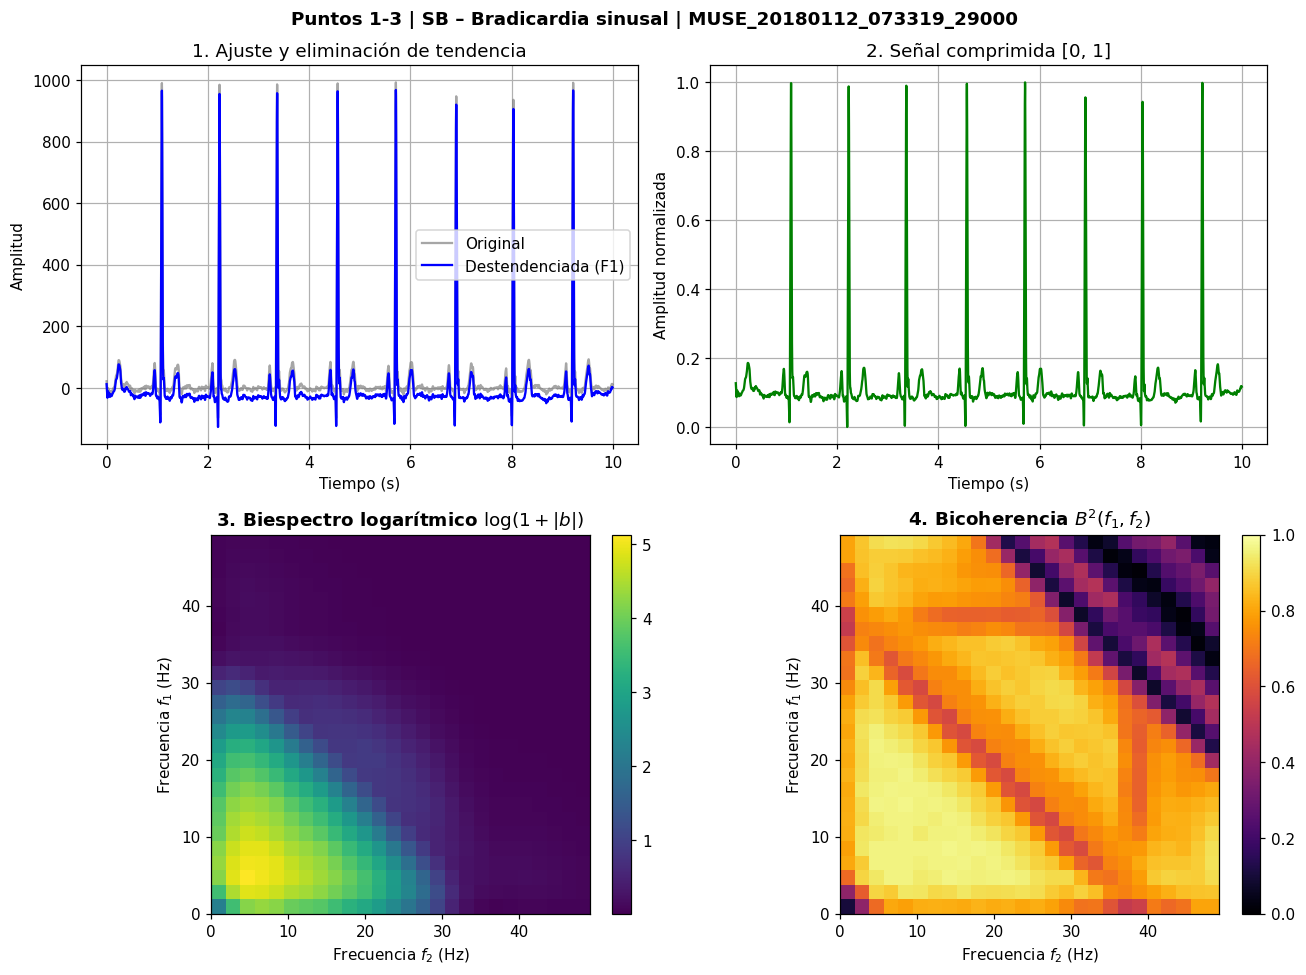

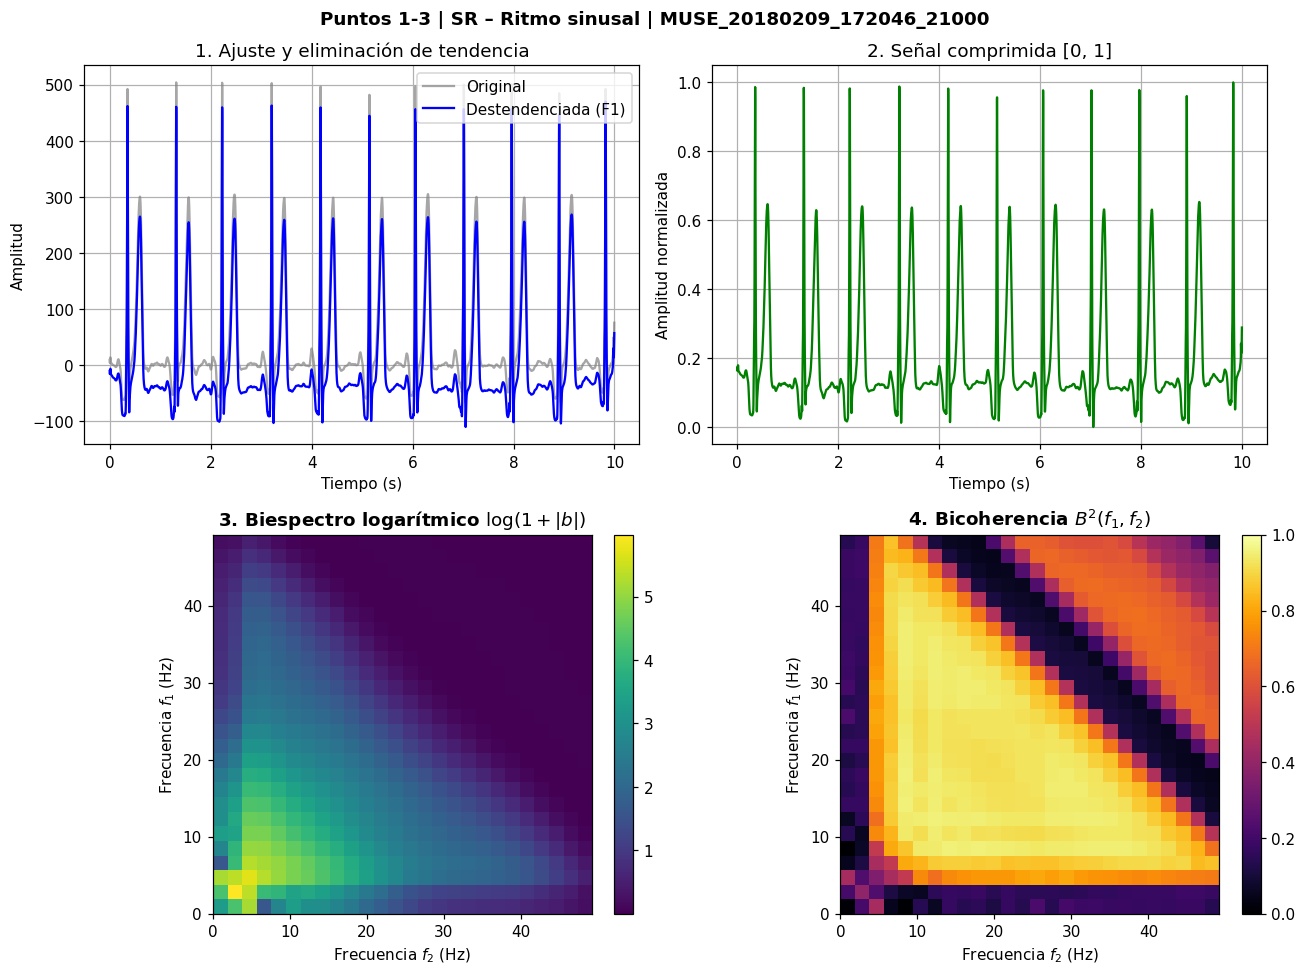

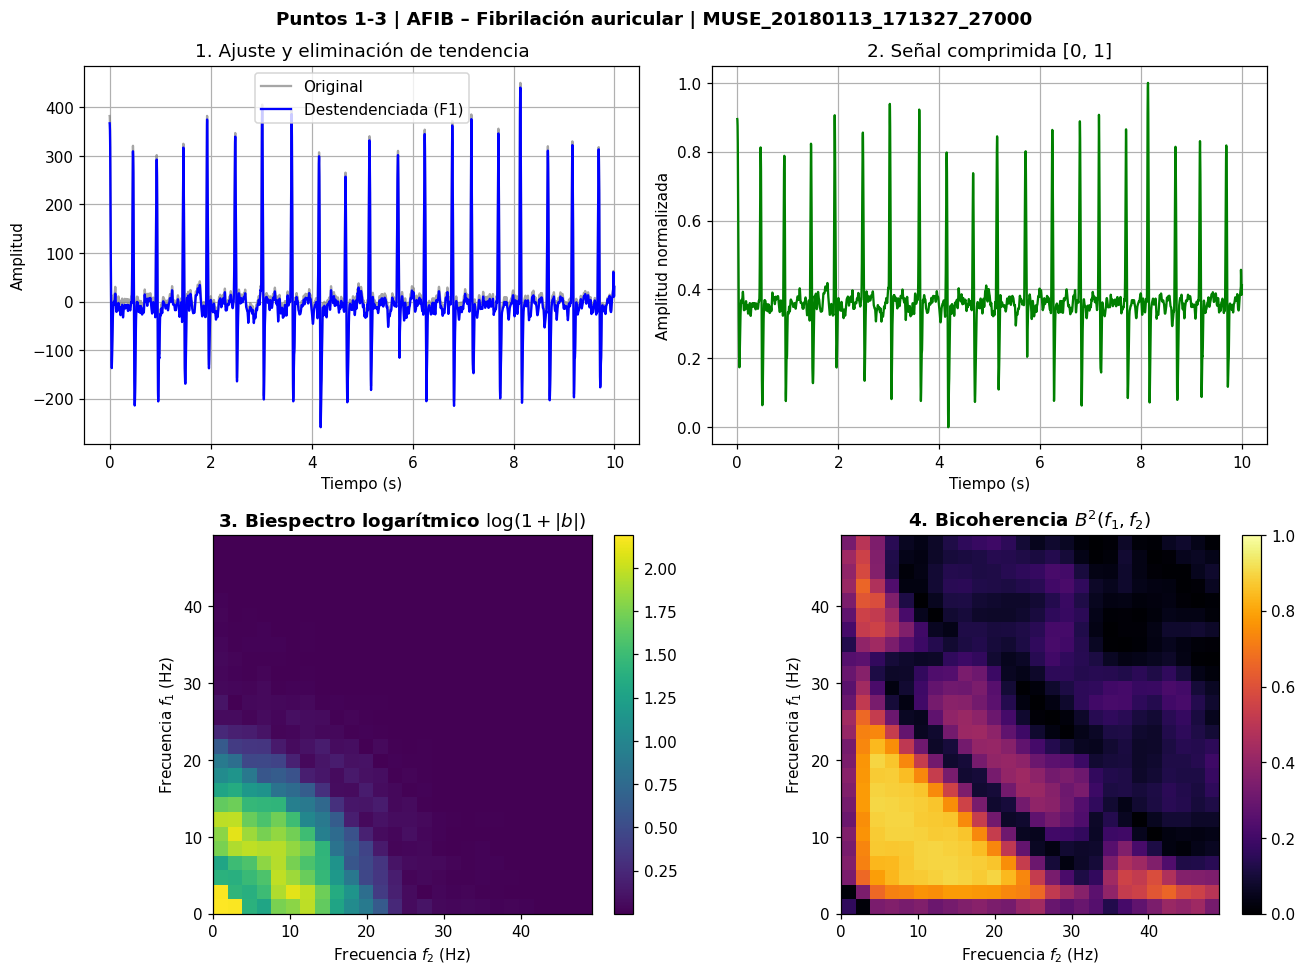

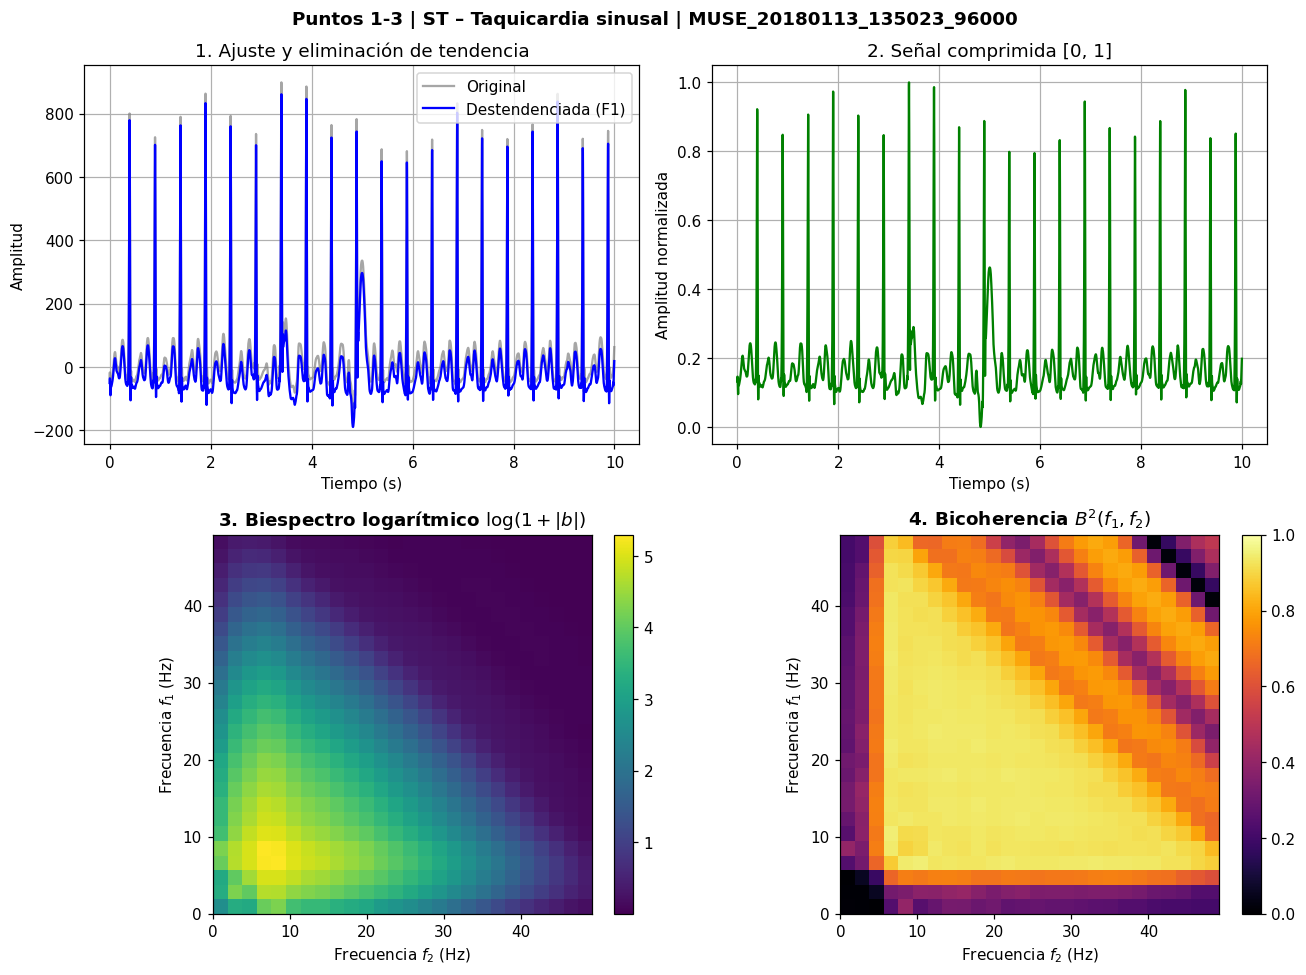

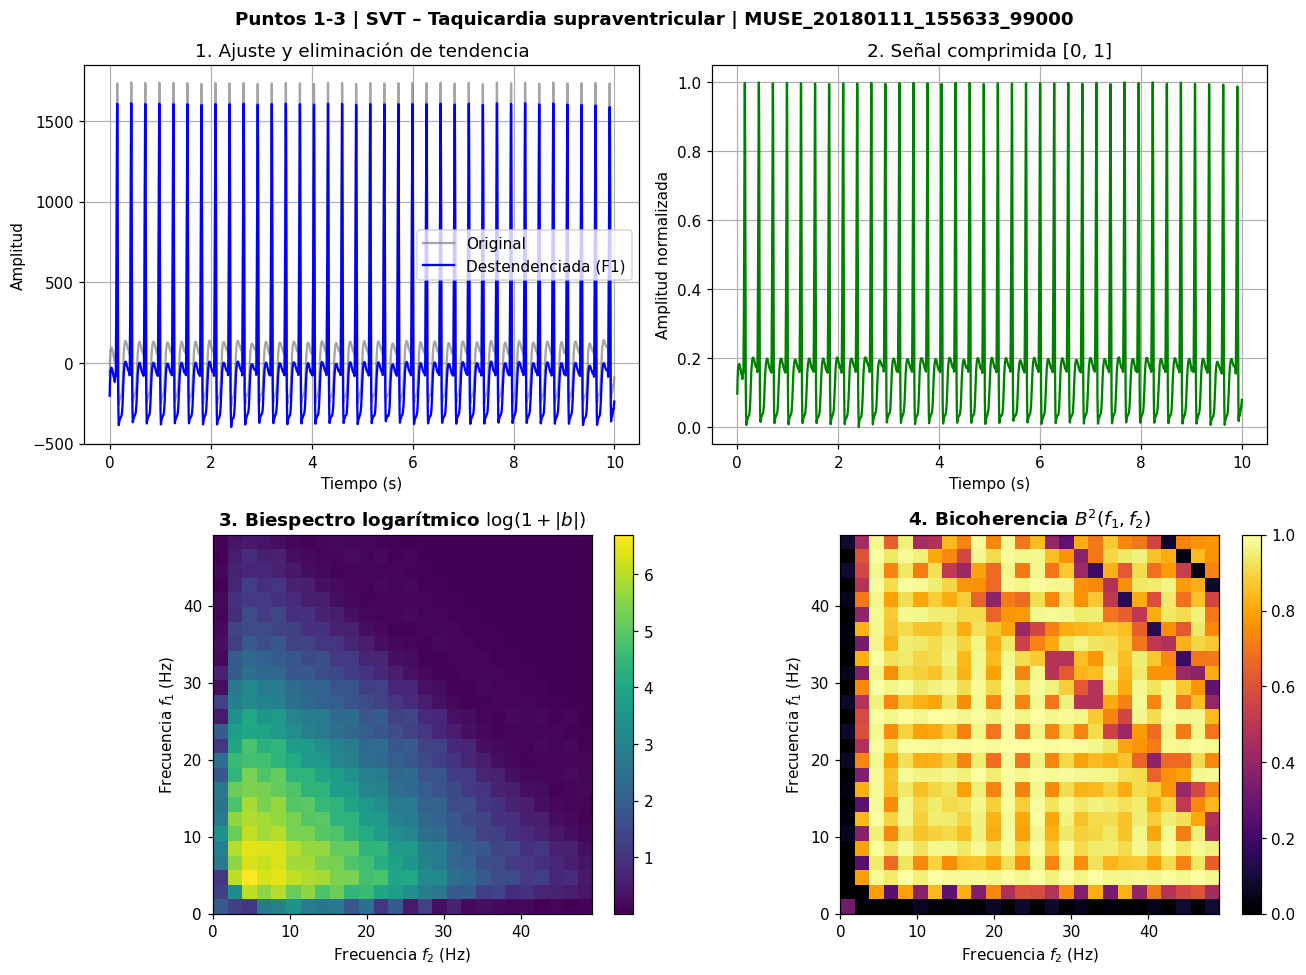

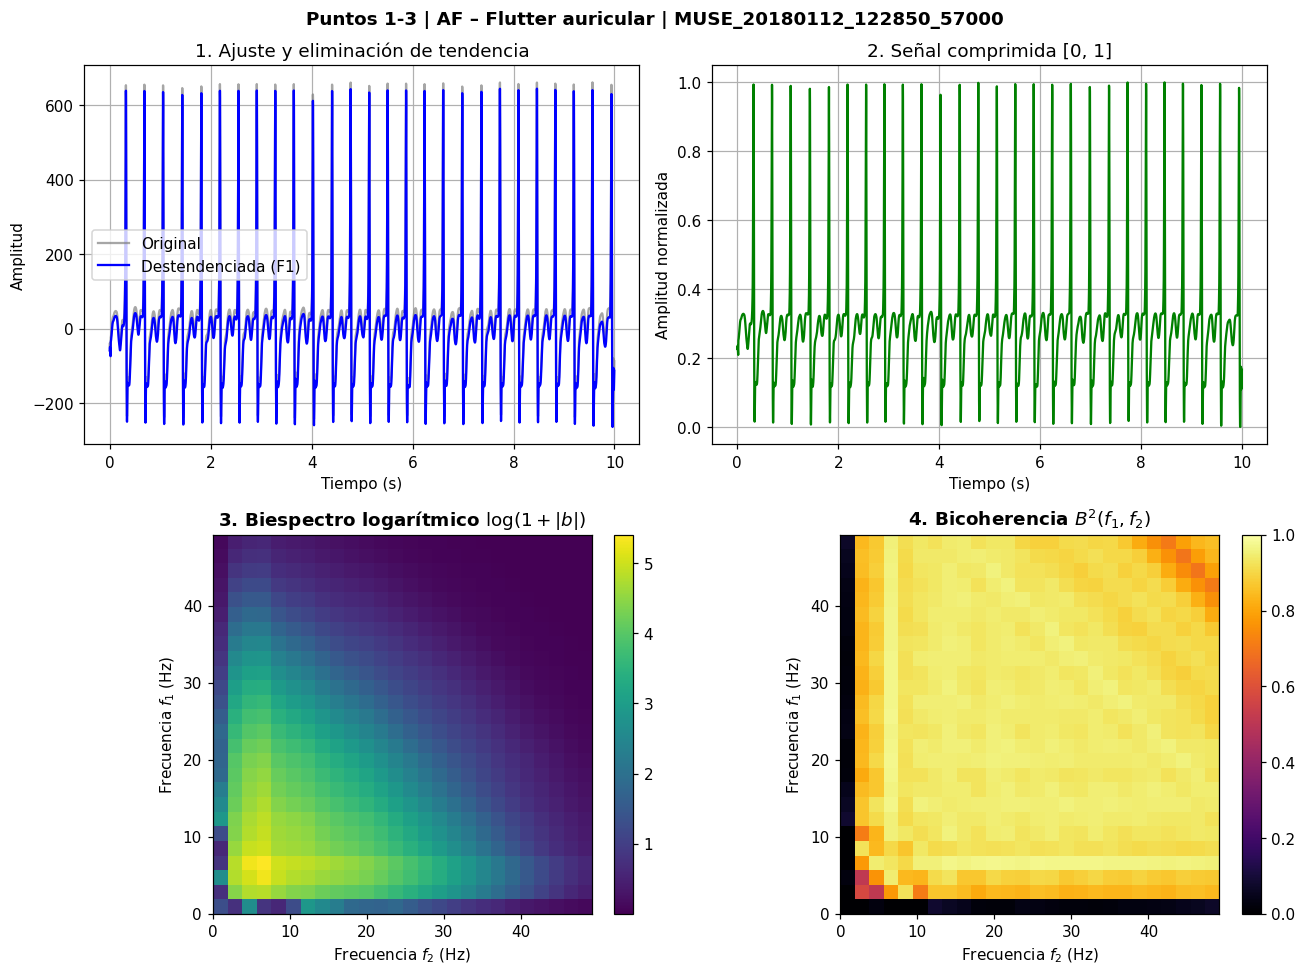

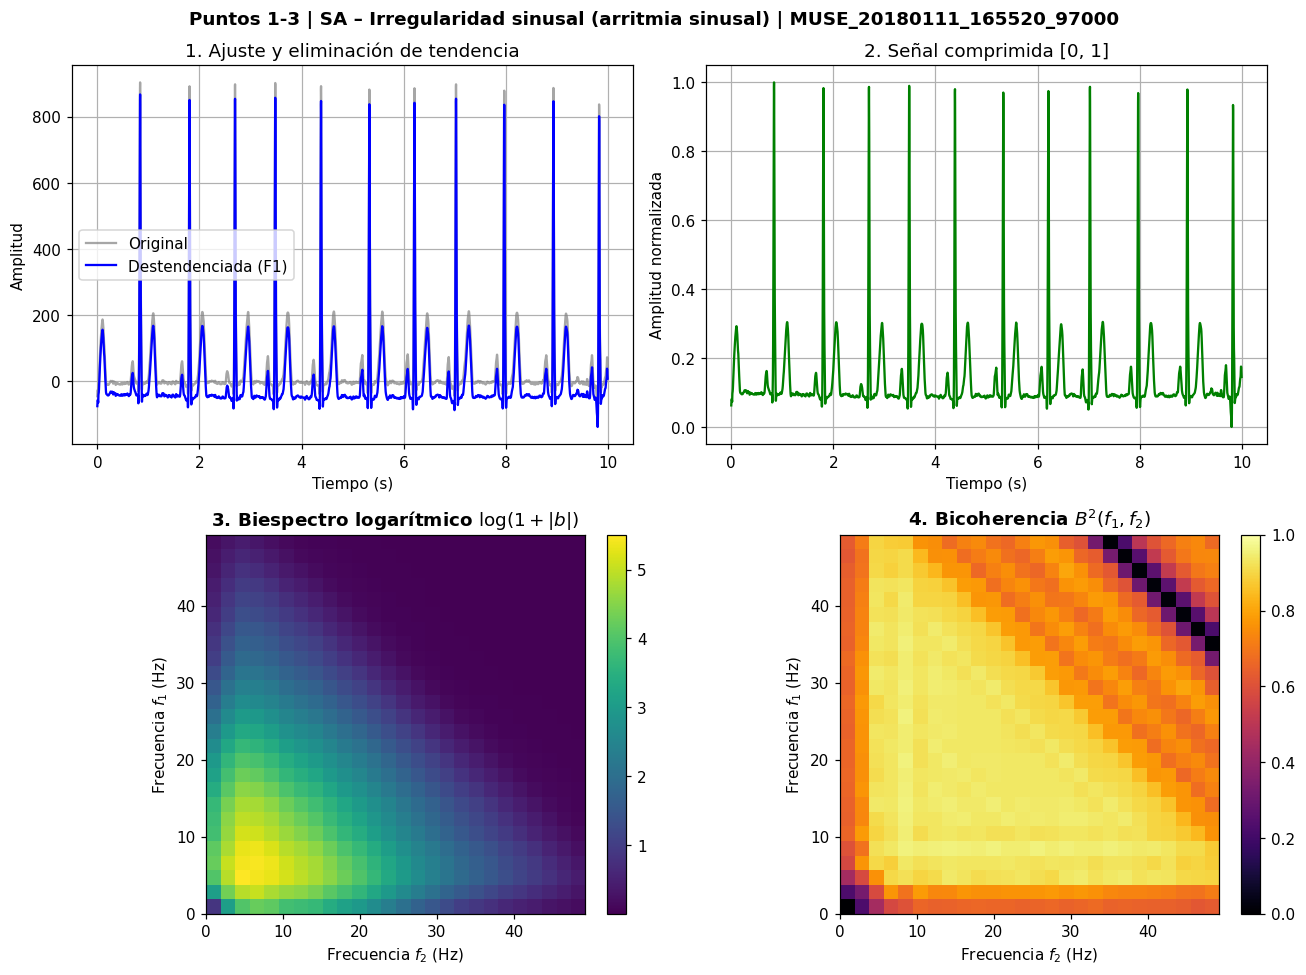

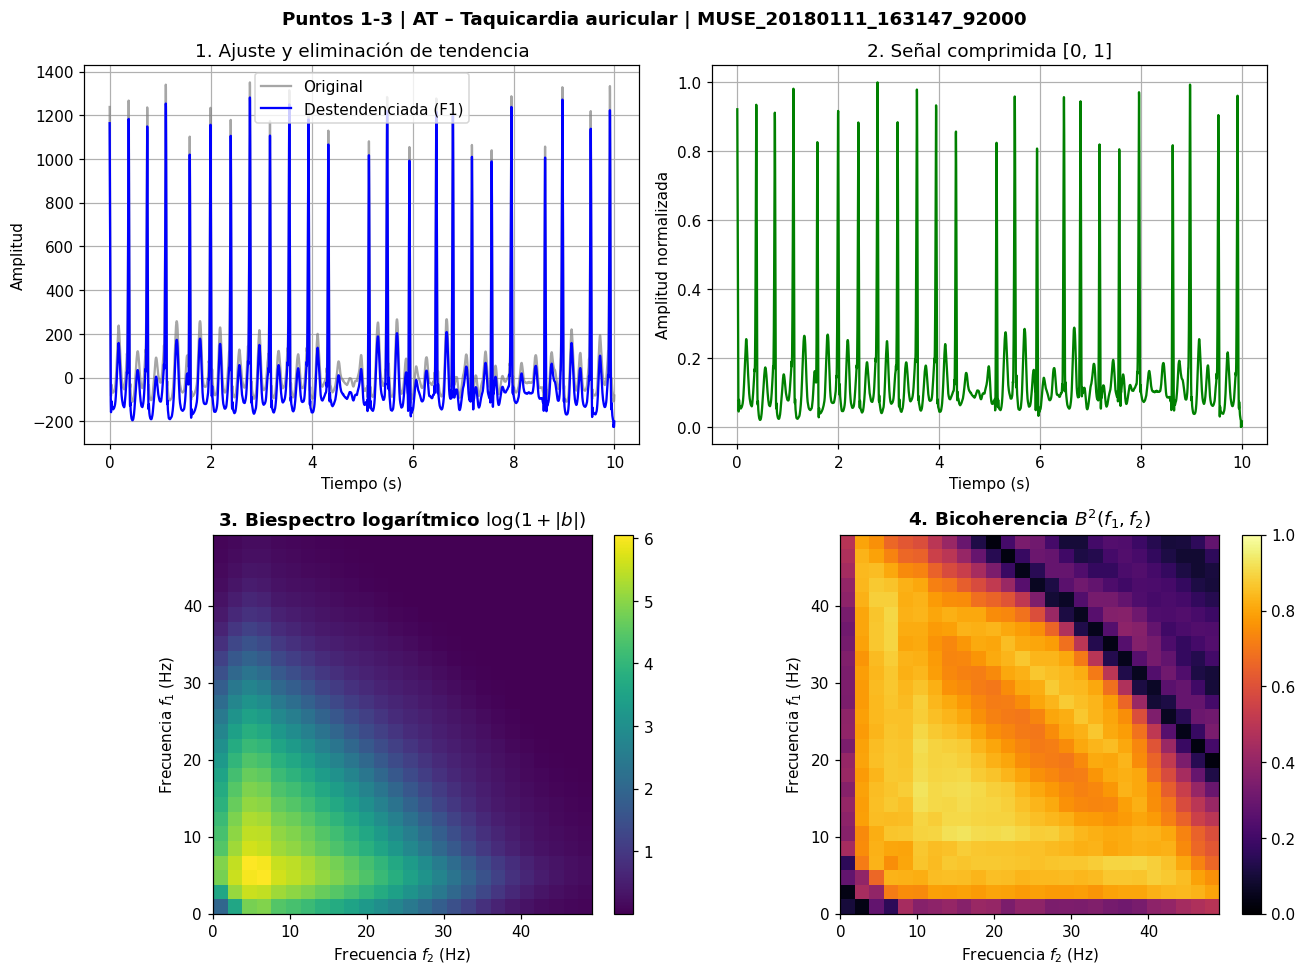

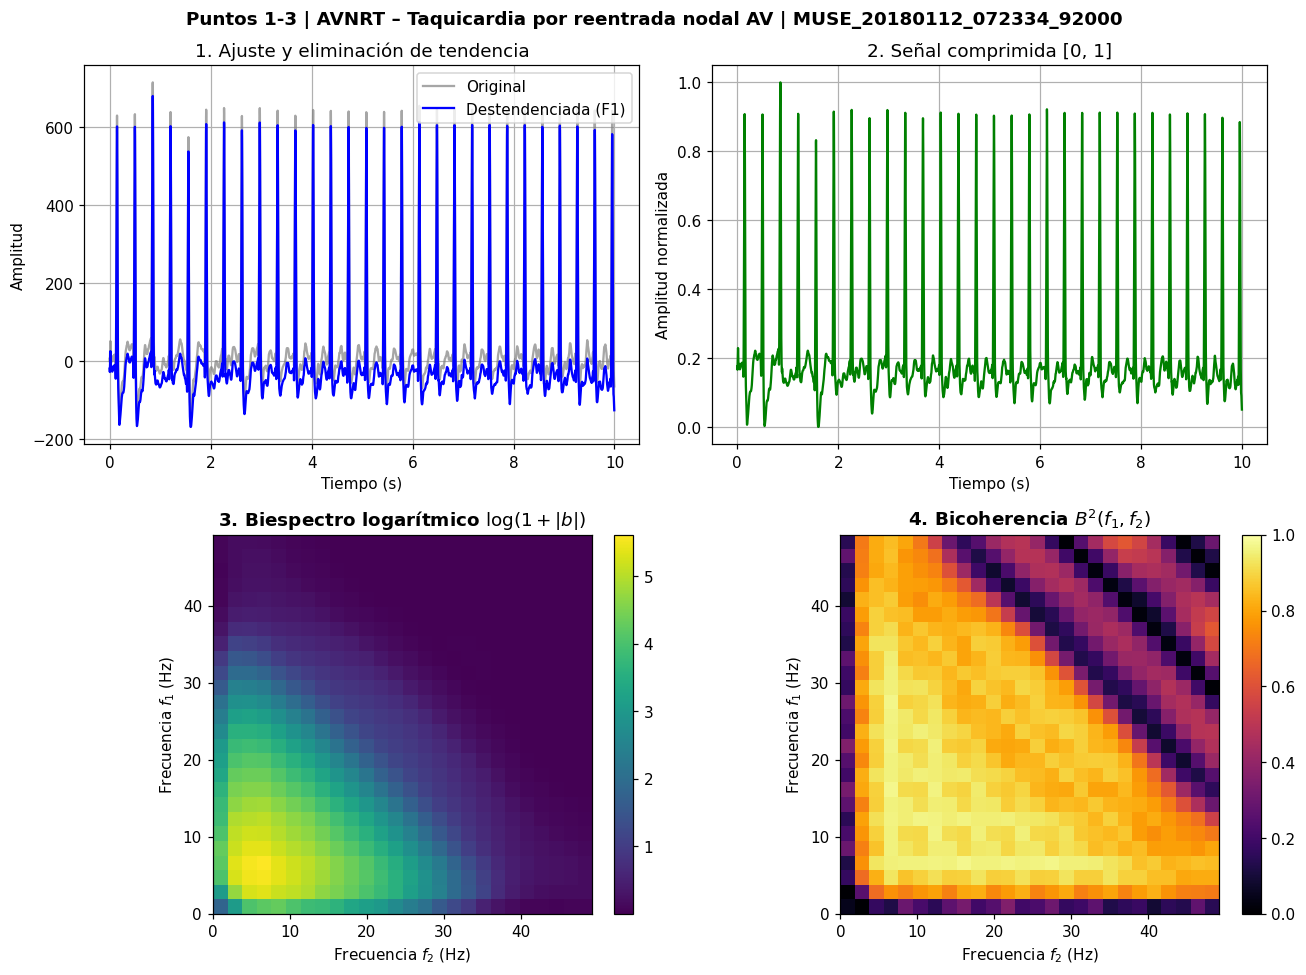

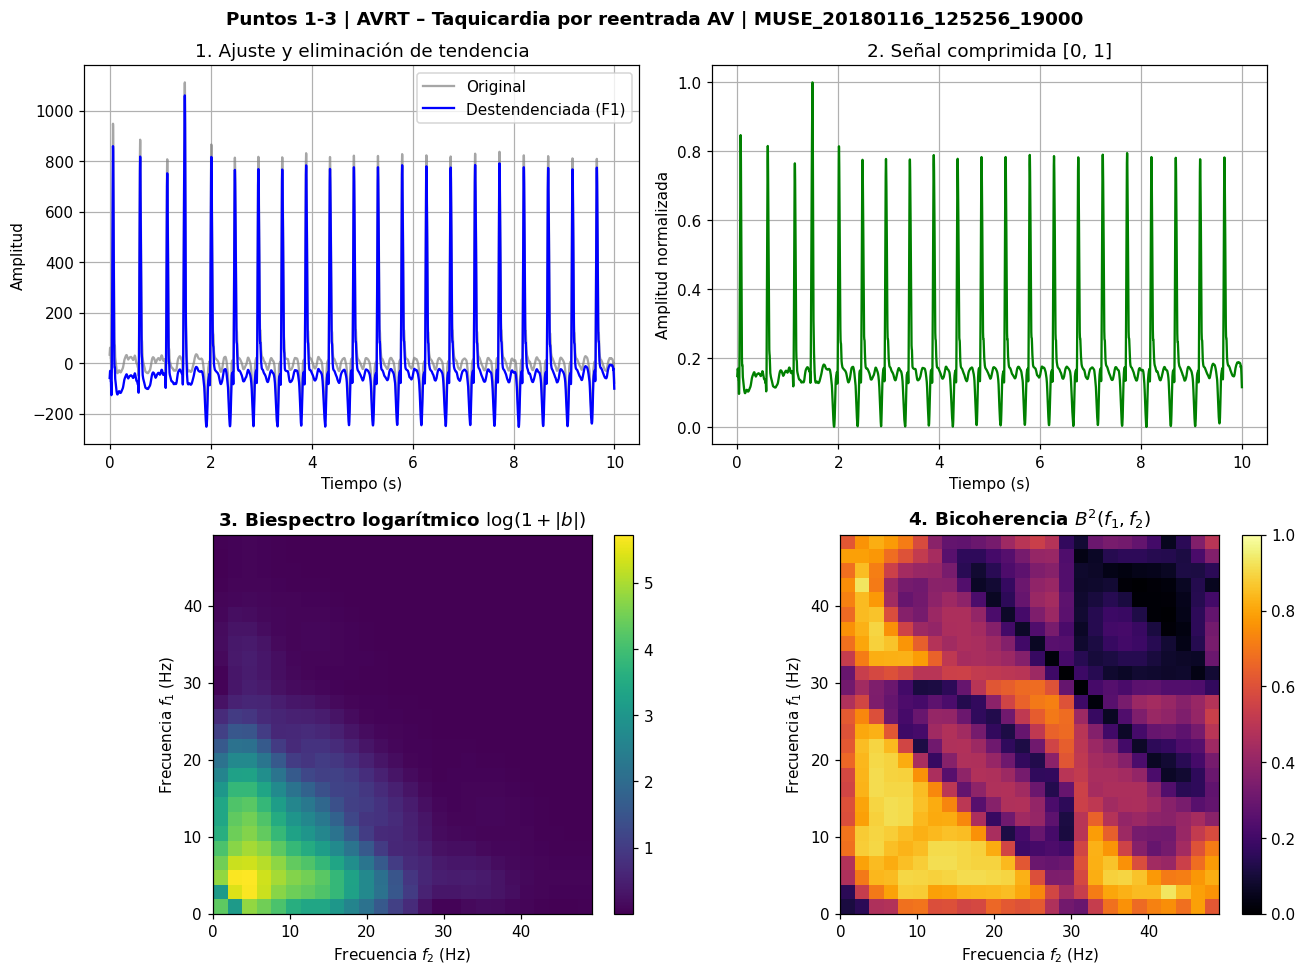

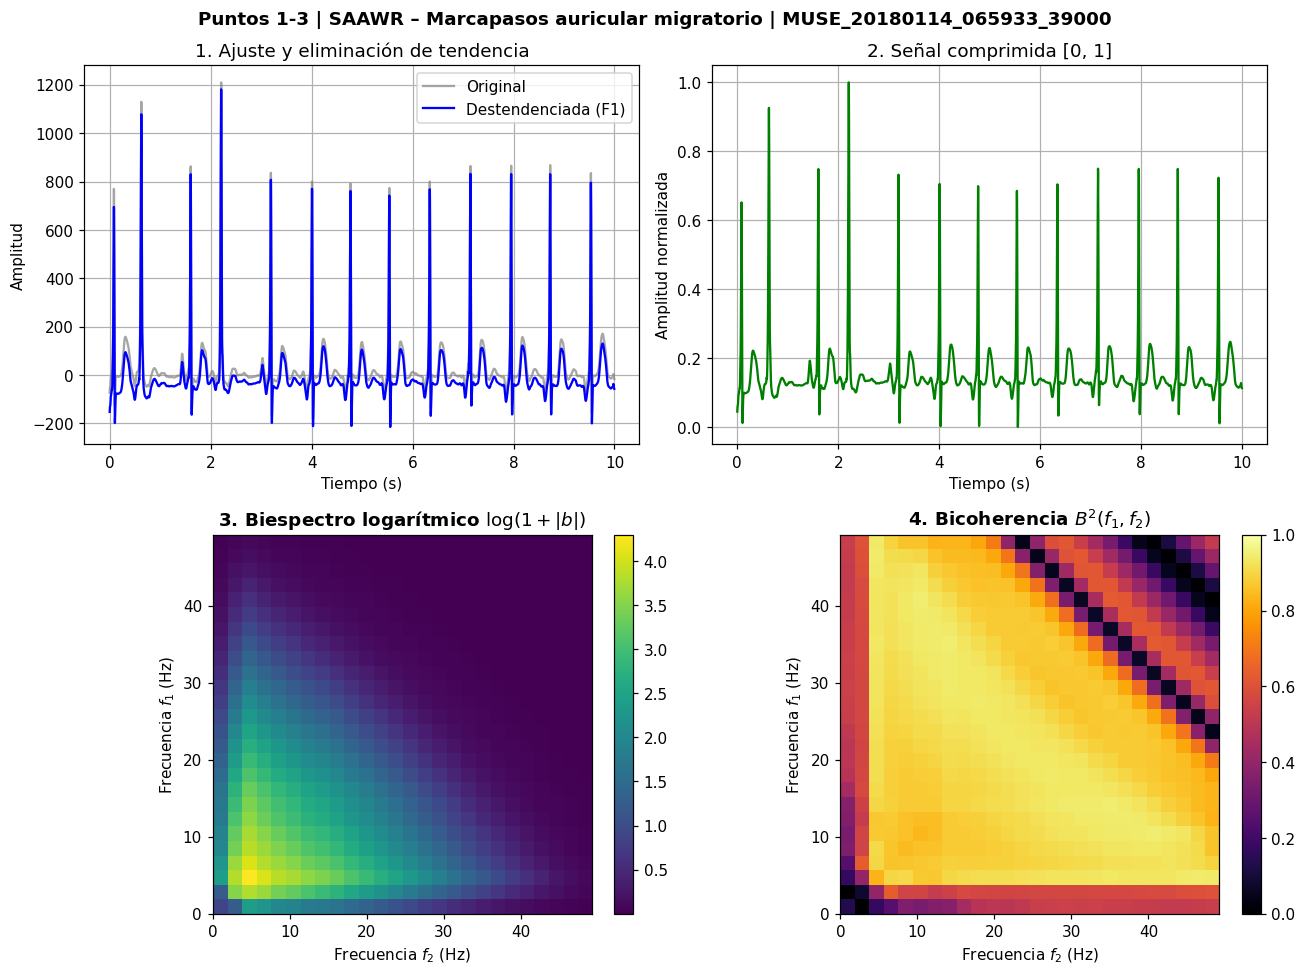


--- 2. Procesando la base de datos completa (fMP y sFSB) ---
Listo: 10646 registros procesados exitosamente, 0 errores.


,Registro,Estado,fMP,sFSB
0,MUSE_20180113_171327_27000,AFIB,10.9863,11403
1,MUSE_20180112_073319_29000,SB,3.41797,22848
2,MUSE_20180111_165520_97000,SA,1.2207,30603
3,MUSE_20180113_121940_44000,SB,2.68555,23567
4,MUSE_20180112_122850_57000,AF,5.37109,29064


In [58]:
df_resultados, errores = procesar_base_completa(df_diag)
display(df_resultados.head())

## 7. Estadística descriptiva para cada arritmia

7. Para las señales de análisis del punto 2 aplicar las rutinas del punto 3 al 
5  y  hacer  un  informe  que  permita  evidenciar  las  diferencias  entre  las 
señales las diferentes arritmias utilizando las herramientas de estadística 
descriptiva (5%). 

In [62]:
if not df_resultados.empty:
    display(
        df_resultados.groupby("Estado")[["fMP", "sFSB"]]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )
else:
    print("No se procesaron registros correctamente. Revisa `errores`.")

fMP                   sFSB                        
       count mean median  std count    mean  median     std
Estado                                                     
AF       445 4.27   3.91 2.24   445 22990.9   22761 6121.87
AFIB    1780 4.14   3.42 2.94  1780 20717.8   20313 5959.91
AT       121 4.72   4.39 2.55   121 22017.8   21898 6495.01
AVNRT     16 4.96   5.49  1.2    16 23701.8 23433.5 3881.56
AVRT       8 4.79   4.76 0.93     8 24159.6   24977 2547.09
SA       399 3.51   3.42 2.43   399 26527.1   26924 4678.73
SAAWR      7 3.59   3.42 0.54     7   21964   21798 4820.53
SB      3889 2.86   2.93 1.94  3889 25389.7   25656 4713.33
SR      1826 4.15   3.91 1.84  1826 27019.5 27934.5 4556.28
ST      1568 5.41   5.37 2.22  1568 26948.6   28291 5177.63
SVT      587 4.58   4.88 2.28   587 21266.5   22888 7924.36

## 8. Diferencia estadística a través de pruebas estadísticas

8. Indicar  si  hay  o  no  diferencias  estadísticas  entre  las  características 
espectrales del punto 4 y 5 para las poblaciones de estudio (5%)

## 9. Análisis de resultados y conclusiones

9. Hacer un informe con todos los puntos anteriores. El informe debe 
incluir análisis de resultados y conclusiones (15%). Trabajo sin sustentar 
no se califica

## 10. Bibliografía

[1] L.-R. Liu et al., “An arrhythmia classification approach via deep learning using single-lead ECG without QRS wave detection,” Heliyon, vol. 10, Art. no. e27200, Feb. 2024, doi: 10.1016/j.heliyon.2024.e27200.

[2] J. Zheng et al., “Optimal multi-stage arrhythmia classification approach,” Sci. Rep., vol. 10, Art. no. 2898, Feb. 2020, doi: 10.1038/s41598-020-59821-7.

[3] M. Gadaleta et al., “Prediction of atrial fibrillation from at-home single-lead ECG signals without arrhythmias,” npj Digit. Med., vol. 6, Art. no. 229, Dec. 2023, doi: 10.1038/s41746-023-00966-w.

[4] Zheng, Jianwei; Rakovski, Cyril; Danioko, Sidy; Zhang, Jianming; Yao, Hai; Hangyuan, Guo (2019). A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients. figshare. Collection. https://doi.org/10.6084/m9.figshare.c.4560497

[5] A. M. Russo et al., "Sex differences in arrhythmias," Nat. Rev. Cardiol., vol. 10, no. 4, pp. 201-209, 2013.

[6] L. A. MacFarlane et al., "Sex differences in electrophysiology and arrhythmias," Circ. Res., vol. 118, no. 6, pp. 1021-1031, 2016.

[7] J. Zheng et al., "A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients," Sci. Data, vol. 7, no. 1, p. 48, 2020.

[8] J. C. Perry y A. R. Garson, "Pediatric Arrhythmias," en Braunwald's Heart Disease: A Textbook of Cardiovascular Medicine, 11.ª ed., D. P. Zipes et al., Eds. Filadelfia, PA: Elsevier, 2019, pp. 883-911.

[9] L. Staerk et al., "Atrial Fibrillation: Epidemiology, Pathophysiology, and Clinical Outcomes," Circ. Res., vol. 120, no. 9, pp. 1501-1517, Abr. 2017.